In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 8192     # Increased batch size for better training stability
EPOCHS = 300          # More epochs for better convergence
LOG_INTERVAL = 50     # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
LATENT_DIM = 256
HIDDEN_DIM = 8192

# VAE-specific hyperparameters
LR = 5e-4             # Lower learning rate for more stable training
BETA = 0.5            # Reduced beta to prevent posterior collapse
BETA_WARMUP = 50      # Epochs to gradually increase beta
WEIGHT_DECAY = 1e-5   # L2 regularization

# Visualization settings
SAVE_PLT_INTERVAL = 10  # How often to save plots (every 10 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE} (increased for stability)")
print(f"Epochs: {EPOCHS} (more epochs for convergence)")
print(f"Hidden dimension: {HIDDEN_DIM} (larger capacity)")
print(f"Latent dimension: {LATENT_DIM} (increased for better representation)")
print(f"Learning rate: {LR} (lower for stability)")
print(f"Beta (KL weight): {BETA} (reduced to prevent collapse)")
print(f"Beta warmup epochs: {BETA_WARMUP}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Device: {device}")


Batch size: 8192 (increased for stability)
Epochs: 300 (more epochs for convergence)
Hidden dimension: 8192 (larger capacity)
Latent dimension: 256 (increased for better representation)
Learning rate: 0.0005 (lower for stability)
Beta (KL weight): 0.5 (reduced to prevent collapse)
Beta warmup epochs: 50
Weight decay: 1e-05
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")


Batch size: 8192
Training batches: 8
Test batches: 2


In [5]:
class VAE(nn.Module):
    """
    Variational Autoencoder with better architecture and training stability.
    """
    
    def __init__(self, input_dim, latent_dim, hidden_dim):
        super().__init__()
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        
        # Encoder network with batch normalization and dropout
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
        )
        
        # Encoder outputs (mean and log variance)
        self.fc_mu = nn.Linear(hidden_dim // 2, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim // 2, latent_dim)
        
        # Decoder network with batch normalization and dropout
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, input_dim),
        )
        
        # Initialize weights properly
        self._initialize_weights()
    
    def _initialize_weights(self):
        """Initialize network weights for better training."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
    
    def encode(self, x):
        """
        Encode input data into latent space.
        
        Args:
            x: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        # Clamp logvar to prevent numerical instability
        logvar = torch.clamp(logvar, min=-10, max=10)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick for sampling from latent distribution.
        
        Args:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        
        Returns:
            z: Sampled latent vector
        """
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        """
        Decode latent vector back to data space.
        
        Args:
            z: Latent vector of shape (batch_size, latent_dim)
        
        Returns:
            reconstructed: Reconstructed data
        """
        return self.decoder(z)
    
    def forward(self, x):
        """
        Forward pass through the VAE.
        
        Args:
            x: Input data tensor
        
        Returns:
            reconstructed: Reconstructed data
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)
        return reconstructed, mu, logvar


In [6]:
# Initialize model
vae = VAE(INPUT_DIM, LATENT_DIM, HIDDEN_DIM)

# Move model to device
vae = vae.to(device)

# Set up optimizer with weight decay
optimizer = torch.optim.Adam(vae.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Learning rate scheduler for better convergence
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=20
)

print(f"Model parameters: {sum(p.numel() for p in vae.parameters()):,}")
print(f"Learning rate: {LR}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Model moved to device: {device}")
print(f"Learning rate scheduler: ReduceLROnPlateau")

# Let's see what our model looks like
print("\nVAE architecture:")
print(vae)


Model parameters: 217,441,552
Learning rate: 0.0005
Weight decay: 1e-05
Model moved to device: cuda
Learning rate scheduler: ReduceLROnPlateau

VAE architecture:
VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=8192, bias=True)
    (1): BatchNorm1d(8192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=8192, out_features=8192, bias=True)
    (5): BatchNorm1d(8192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=8192, out_features=4096, bias=True)
    (9): BatchNorm1d(4096, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
  )
  (fc_mu): Linear(in_features=4096, out_features=256, bias=True)
  (fc_logvar): Linear(in_features=4096, out_features=256, bias=True)
  (decoder): Sequential(
    (0): Linear(in_fe

In [7]:
def vae_loss(reconstructed, original, mu, logvar, beta=1.0):
    """
    Compute the VAE loss function with better numerical stability.
    
    Args:
        reconstructed: Reconstructed data from decoder
        original: Original input data
        mu: Mean of latent distribution
        logvar: Log variance of latent distribution
        beta: Weight for KL divergence term
    
    Returns:
        total_loss: Total VAE loss
        recon_loss: Reconstruction loss
        kl_loss: KL divergence loss
    """
    # Reconstruction loss (MSE with mean reduction for better scaling)
    recon_loss = F.mse_loss(reconstructed, original, reduction='mean')
    
    # KL divergence loss with numerical stability
    # KL(q(z|x) || p(z)) where p(z) = N(0, I)
    # closed form analytical solution for KL divergence
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    
    # Total loss
    total_loss = recon_loss + beta * kl_loss
    
    return total_loss, recon_loss, kl_loss

def get_beta_schedule(epoch, max_epochs, warmup_epochs):
    """
    Get beta value with warmup schedule to prevent posterior collapse.
    
    Args:
        epoch: Current epoch
        max_epochs: Total number of epochs
        warmup_epochs: Number of epochs for warmup
    
    Returns:
        beta: Current beta value
    """
    if epoch < warmup_epochs:
        # Linear warmup from 0 to BETA
        return BETA * (epoch / warmup_epochs)
    else:
        # Cyclical annealing to prevent posterior collapse
        cycle_length = 50
        cycle_position = (epoch - warmup_epochs) % cycle_length
        cycle_progress = cycle_position / cycle_length
        return BETA * (0.5 + 0.5 * np.cos(np.pi * cycle_progress))

def train_epoch(epoch):
    """
    Train the VAE for one epoch with beta scheduling.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_total_loss: Average total loss for this epoch
        avg_recon_loss: Average reconstruction loss
        avg_kl_loss: Average KL divergence loss
        current_beta: Current beta value used
    """
    vae.train()
    
    # Get current beta value with scheduling
    current_beta = get_beta_schedule(epoch, EPOCHS, BETA_WARMUP)
    
    total_losses = []
    recon_losses = []
    kl_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        
        # Clear gradients
        optimizer.zero_grad()
        
        # Forward pass
        reconstructed, mu, logvar = vae(data)
        
        # Compute loss with current beta
        total_loss, recon_loss, kl_loss = vae_loss(reconstructed, data, mu, logvar, current_beta)
        
        # Backward pass
        total_loss.backward()
        
        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(vae.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Track losses
        total_losses.append(total_loss.item())
        recon_losses.append(recon_loss.item())
        kl_losses.append(kl_loss.item())
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tTotal Loss: {:.6f}\tRecon Loss: {:.6f}\tKL Loss: {:.6f}\tBeta: {:.3f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), total_loss.item(), recon_loss.item(), kl_loss.item(), current_beta))
    
    # Calculate average losses
    avg_total_loss = sum(total_losses) / len(total_losses)
    avg_recon_loss = sum(recon_losses) / len(recon_losses)
    avg_kl_loss = sum(kl_losses) / len(kl_losses)
    
    # Update learning rate scheduler
    scheduler.step(avg_total_loss)
    
    print('====> Epoch: {} Average Total Loss: {:.4f}, Average Recon Loss: {:.4f}, Average KL Loss: {:.4f}, Beta: {:.3f}'.format(
        epoch, avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta))
    
    return avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta

In [8]:
def generate_samples(num_samples=1000):
    """
    Generate new samples using the VAE decoder.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        generated_samples: Generated data as numpy array
    """
    vae.eval()
    
    with torch.no_grad():
        # Sample from standard Gaussian in latent space
        z = torch.randn(num_samples, LATENT_DIM, device=device)
        
        # Decode to generate samples
        generated_samples = vae.decode(z)
        
        # Convert to numpy for visualization
        generated_samples = generated_samples.cpu().numpy()
    
    return generated_samples

def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

def visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=False):
    """
    Visualize the current state of our VAE training.
    
    Args:
        epoch: Current epoch number
        total_losses: List of total losses
        recon_losses: List of reconstruction losses
        kl_losses: List of KL divergence losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Loss plots
    if len(total_losses) > 0:
        epochs_range = range(1, len(total_losses) + 1)
        
        # Total loss
        plt.subplot(2, 3, 4)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Total Loss')
        plt.title('Total Loss Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Reconstruction and KL losses
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=2)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Loss Components')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=1, alpha=0.7)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=1, alpha=0.7)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('All Losses Combined')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save plot if requested
    if save_plot:
        if not os.path.exists('vae_results'):
            os.makedirs('vae_results')
        plt.savefig(f'vae_results/vae_progress_epoch_{epoch}.png', dpi=150, bbox_inches='tight')
        print(f"💾 Saved plot: vae_results/vae_progress_epoch_{epoch}.png")
    
    plt.show()


🎯 Starting VAE training...
📊 Initial state (before training):
💾 Saved plot: vae_results/vae_progress_epoch_0.png


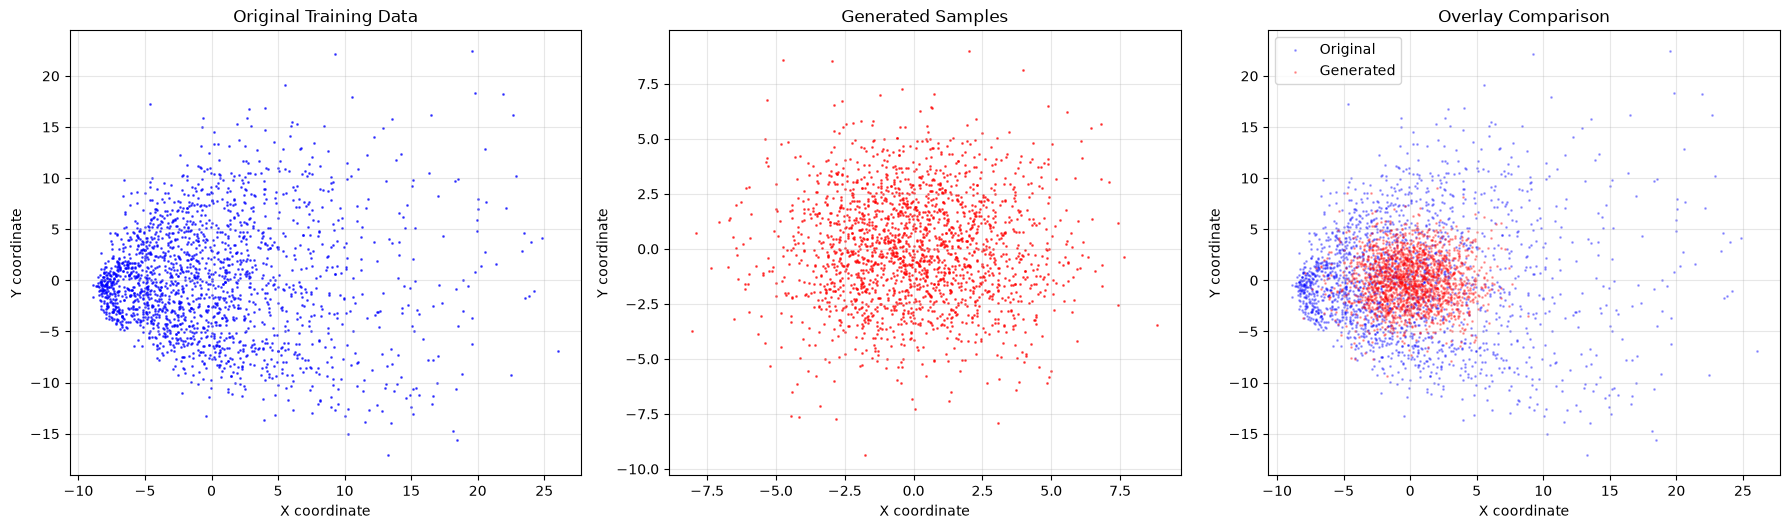


📊 Epoch 1/300
----------------------------------------
Epoch: 1 [0/60000 (0%)]	Total Loss: 1.146865	Recon Loss: 1.138712	KL Loss: 0.815354	Beta: 0.010
====> Epoch: 1 Average Total Loss: 0.9386, Average Recon Loss: 0.8475, Average KL Loss: 9.1188, Beta: 0.010
📈 Epoch 1 Summary:
   Total Loss: 0.9386
   Reconstruction Loss: 0.8475
   KL Divergence Loss: 9.1188
   Beta: 0.010
   Learning Rate: 0.000500

📊 Epoch 2/300
----------------------------------------
Epoch: 2 [0/60000 (0%)]	Total Loss: 0.277608	Recon Loss: 0.174469	KL Loss: 5.156961	Beta: 0.020
====> Epoch: 2 Average Total Loss: 0.1623, Average Recon Loss: 0.1263, Average KL Loss: 1.8033, Beta: 0.020
📈 Epoch 2 Summary:
   Total Loss: 0.1623
   Reconstruction Loss: 0.1263
   KL Divergence Loss: 1.8033
   Beta: 0.020
   Learning Rate: 0.000500

📊 Epoch 3/300
----------------------------------------
Epoch: 3 [0/60000 (0%)]	Total Loss: 0.105768	Recon Loss: 0.085786	KL Loss: 0.666054	Beta: 0.030
====> Epoch: 3 Average Total Loss: 0.098

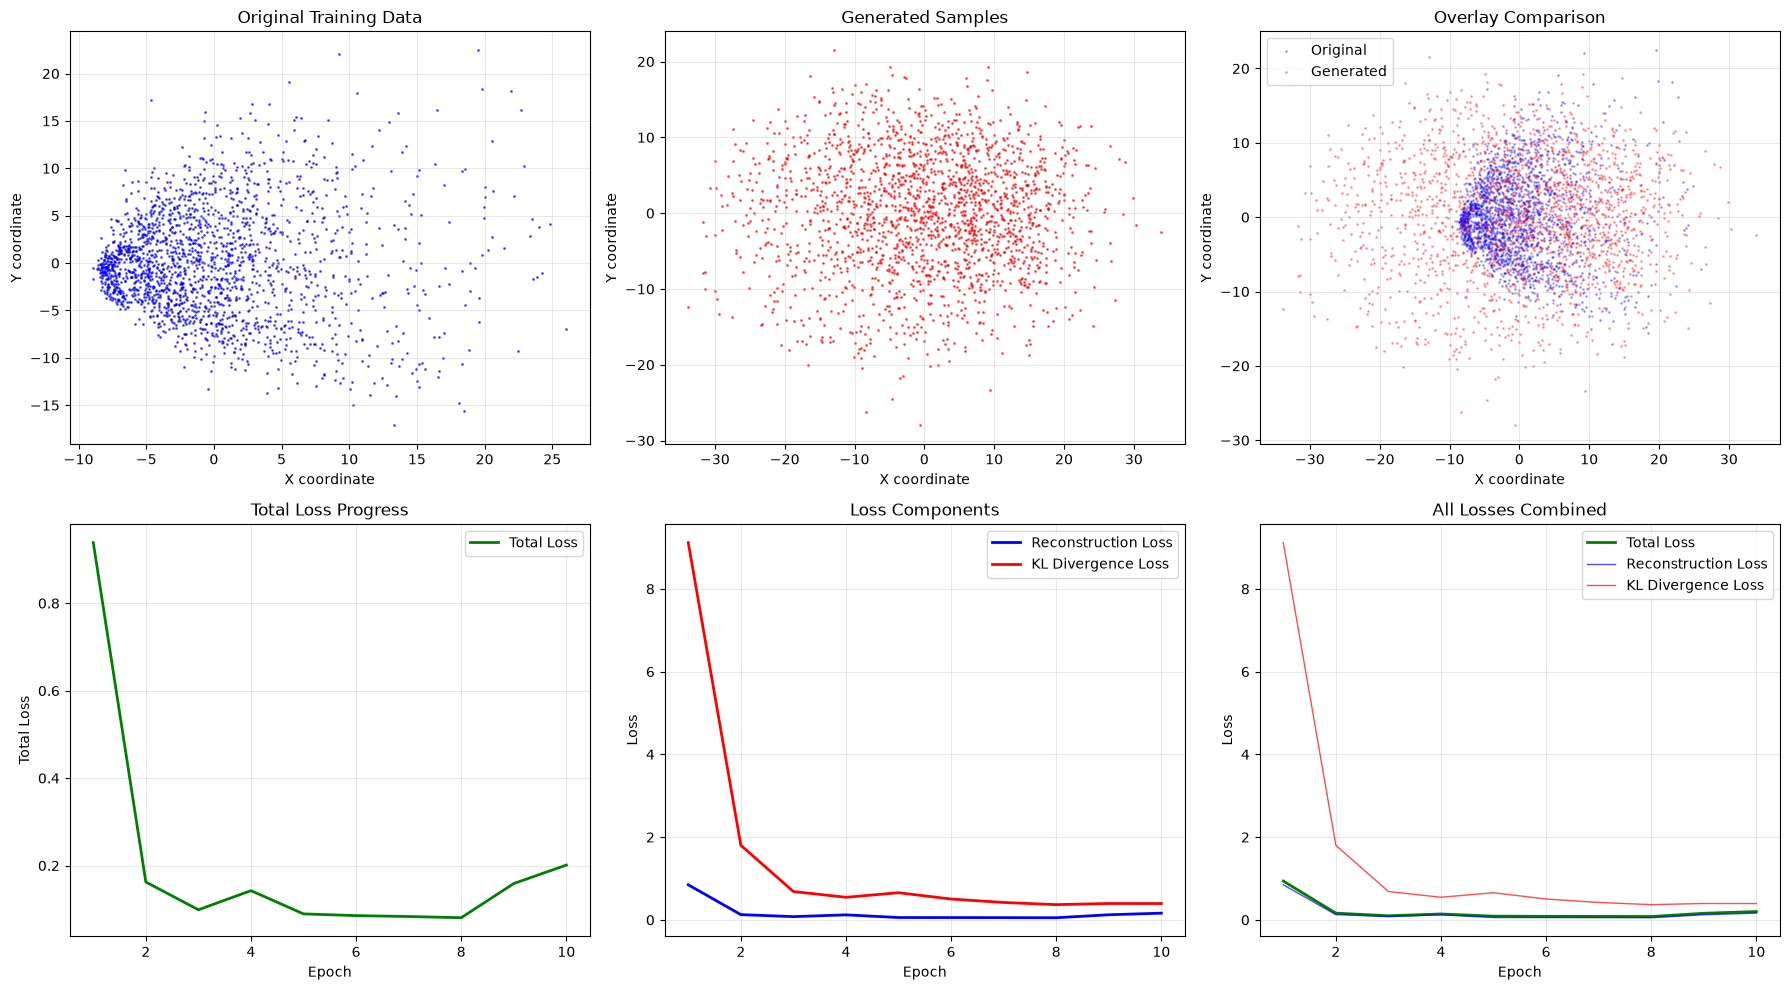

📈 Epoch 10 Summary:
   Total Loss: 0.2011
   Reconstruction Loss: 0.1616
   KL Divergence Loss: 0.3946
   Beta: 0.100
   Learning Rate: 0.000500

📊 Epoch 11/300
----------------------------------------
Epoch: 11 [0/60000 (0%)]	Total Loss: 0.204598	Recon Loss: 0.131776	KL Loss: 0.662014	Beta: 0.110
====> Epoch: 11 Average Total Loss: 0.1362, Average Recon Loss: 0.0904, Average KL Loss: 0.4156, Beta: 0.110
📈 Epoch 11 Summary:
   Total Loss: 0.1362
   Reconstruction Loss: 0.0904
   KL Divergence Loss: 0.4156
   Beta: 0.110
   Learning Rate: 0.000500

📊 Epoch 12/300
----------------------------------------
Epoch: 12 [0/60000 (0%)]	Total Loss: 0.117032	Recon Loss: 0.063035	KL Loss: 0.449973	Beta: 0.120
====> Epoch: 12 Average Total Loss: 0.1025, Average Recon Loss: 0.0595, Average KL Loss: 0.3586, Beta: 0.120
📈 Epoch 12 Summary:
   Total Loss: 0.1025
   Reconstruction Loss: 0.0595
   KL Divergence Loss: 0.3586
   Beta: 0.120
   Learning Rate: 0.000500

📊 Epoch 13/300
-----------------------

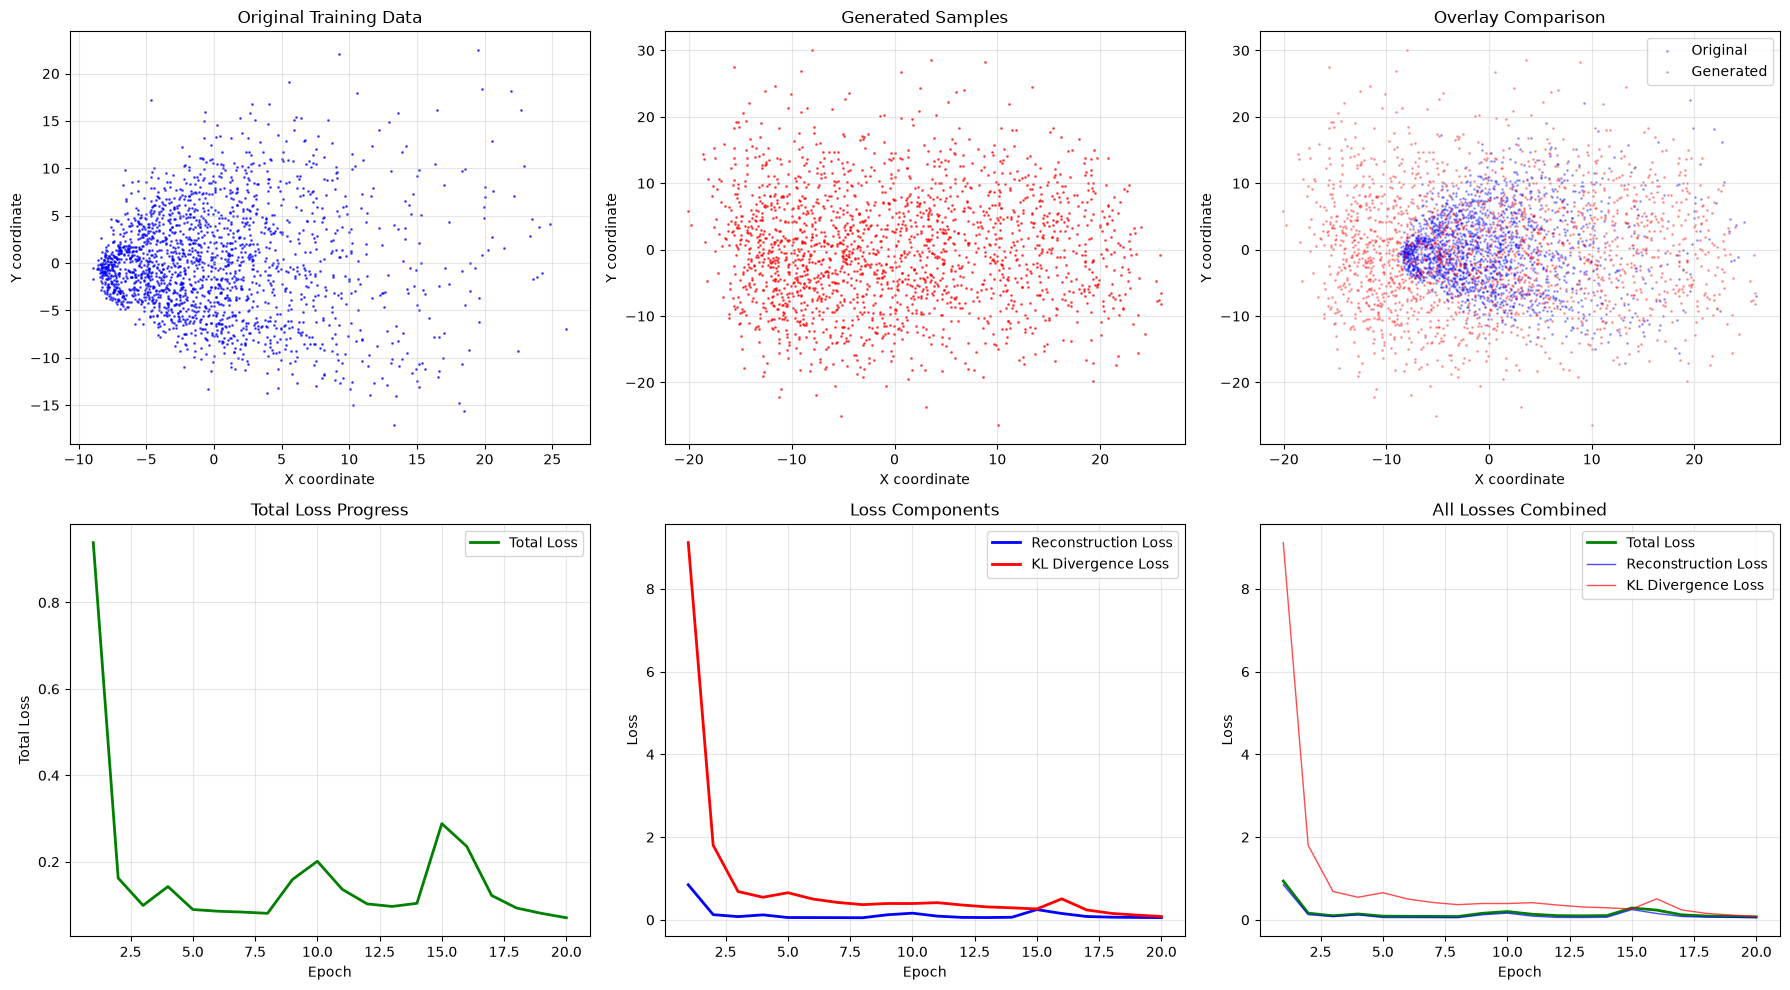

📈 Epoch 20 Summary:
   Total Loss: 0.0704
   Reconstruction Loss: 0.0541
   KL Divergence Loss: 0.0818
   Beta: 0.200
   Learning Rate: 0.000500

📊 Epoch 21/300
----------------------------------------
Epoch: 21 [0/60000 (0%)]	Total Loss: 0.067998	Recon Loss: 0.052389	KL Loss: 0.074329	Beta: 0.210
====> Epoch: 21 Average Total Loss: 0.0662, Average Recon Loss: 0.0513, Average KL Loss: 0.0709, Beta: 0.210
📈 Epoch 21 Summary:
   Total Loss: 0.0662
   Reconstruction Loss: 0.0513
   KL Divergence Loss: 0.0709
   Beta: 0.210
   Learning Rate: 0.000500

📊 Epoch 22/300
----------------------------------------
Epoch: 22 [0/60000 (0%)]	Total Loss: 0.065308	Recon Loss: 0.050583	KL Loss: 0.066931	Beta: 0.220
====> Epoch: 22 Average Total Loss: 0.0638, Average Recon Loss: 0.0499, Average KL Loss: 0.0629, Beta: 0.220
📈 Epoch 22 Summary:
   Total Loss: 0.0638
   Reconstruction Loss: 0.0499
   KL Divergence Loss: 0.0629
   Beta: 0.220
   Learning Rate: 0.000500

📊 Epoch 23/300
-----------------------

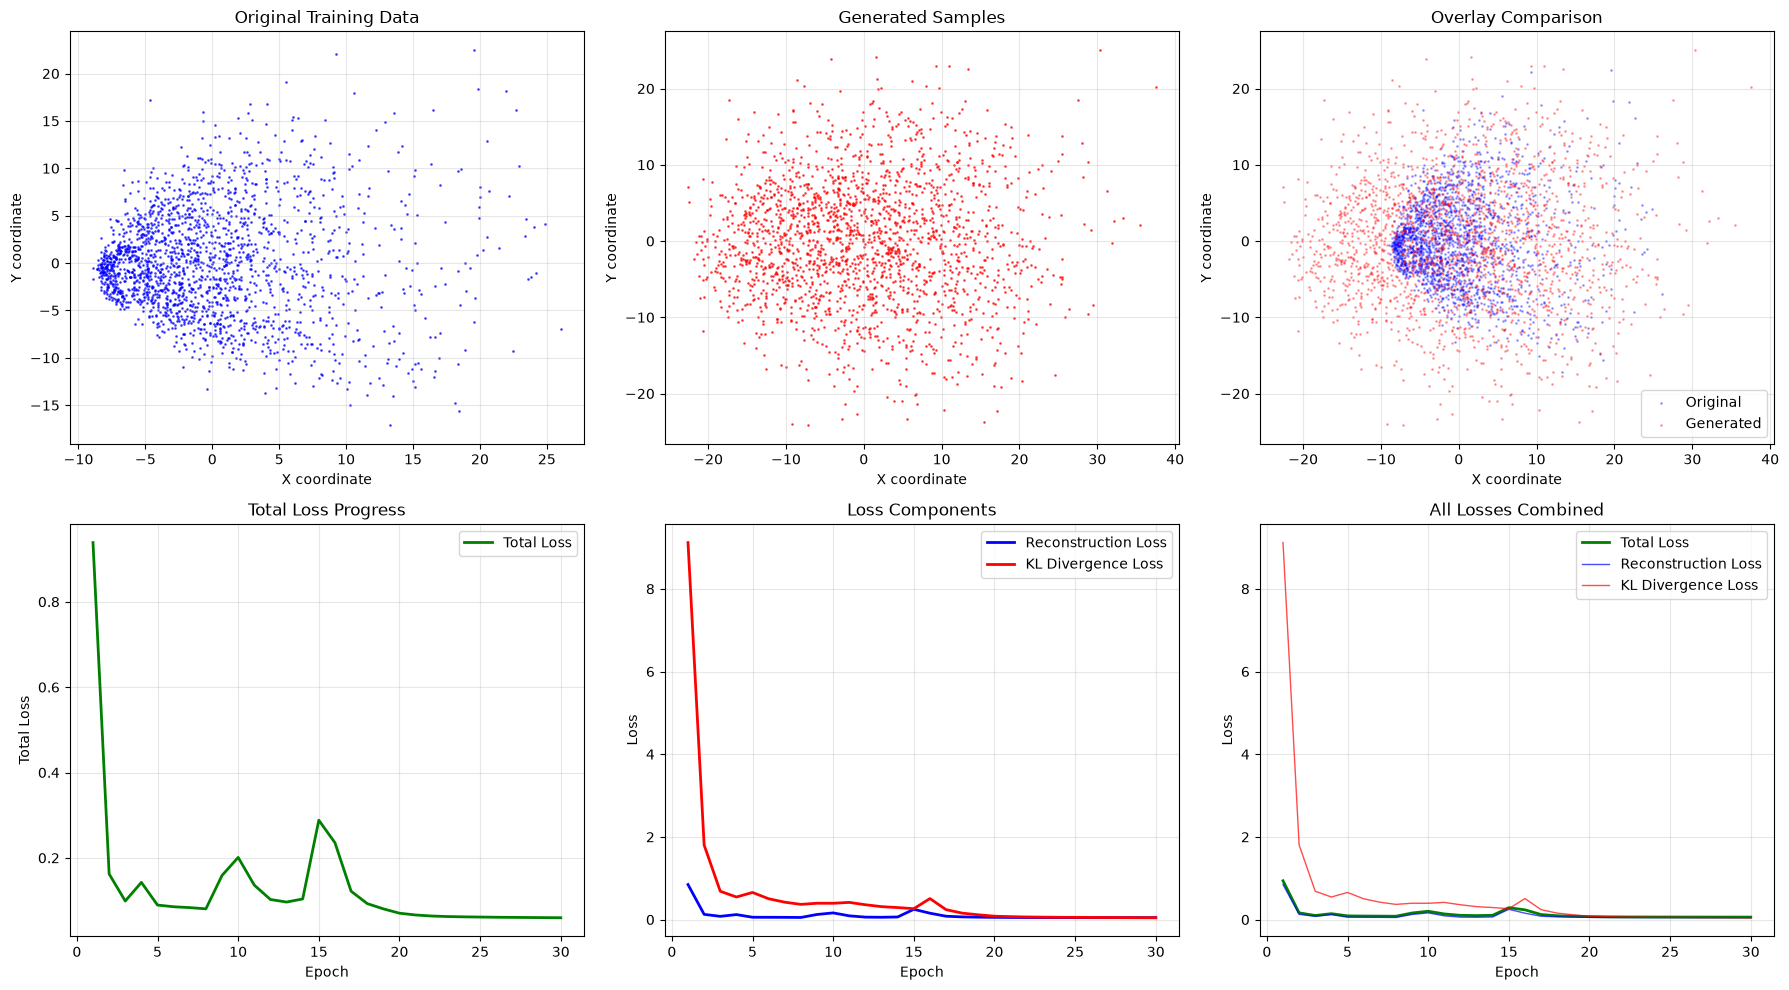

📈 Epoch 30 Summary:
   Total Loss: 0.0598
   Reconstruction Loss: 0.0464
   KL Divergence Loss: 0.0445
   Beta: 0.300
   Learning Rate: 0.000500

📊 Epoch 31/300
----------------------------------------
Epoch: 31 [0/60000 (0%)]	Total Loss: 0.059686	Recon Loss: 0.045963	KL Loss: 0.044268	Beta: 0.310
====> Epoch: 31 Average Total Loss: 0.0598, Average Recon Loss: 0.0463, Average KL Loss: 0.0436, Beta: 0.310
📈 Epoch 31 Summary:
   Total Loss: 0.0598
   Reconstruction Loss: 0.0463
   KL Divergence Loss: 0.0436
   Beta: 0.310
   Learning Rate: 0.000500

📊 Epoch 32/300
----------------------------------------
Epoch: 32 [0/60000 (0%)]	Total Loss: 0.059786	Recon Loss: 0.046114	KL Loss: 0.042727	Beta: 0.320
====> Epoch: 32 Average Total Loss: 0.0597, Average Recon Loss: 0.0461, Average KL Loss: 0.0426, Beta: 0.320
📈 Epoch 32 Summary:
   Total Loss: 0.0597
   Reconstruction Loss: 0.0461
   KL Divergence Loss: 0.0426
   Beta: 0.320
   Learning Rate: 0.000500

📊 Epoch 33/300
-----------------------

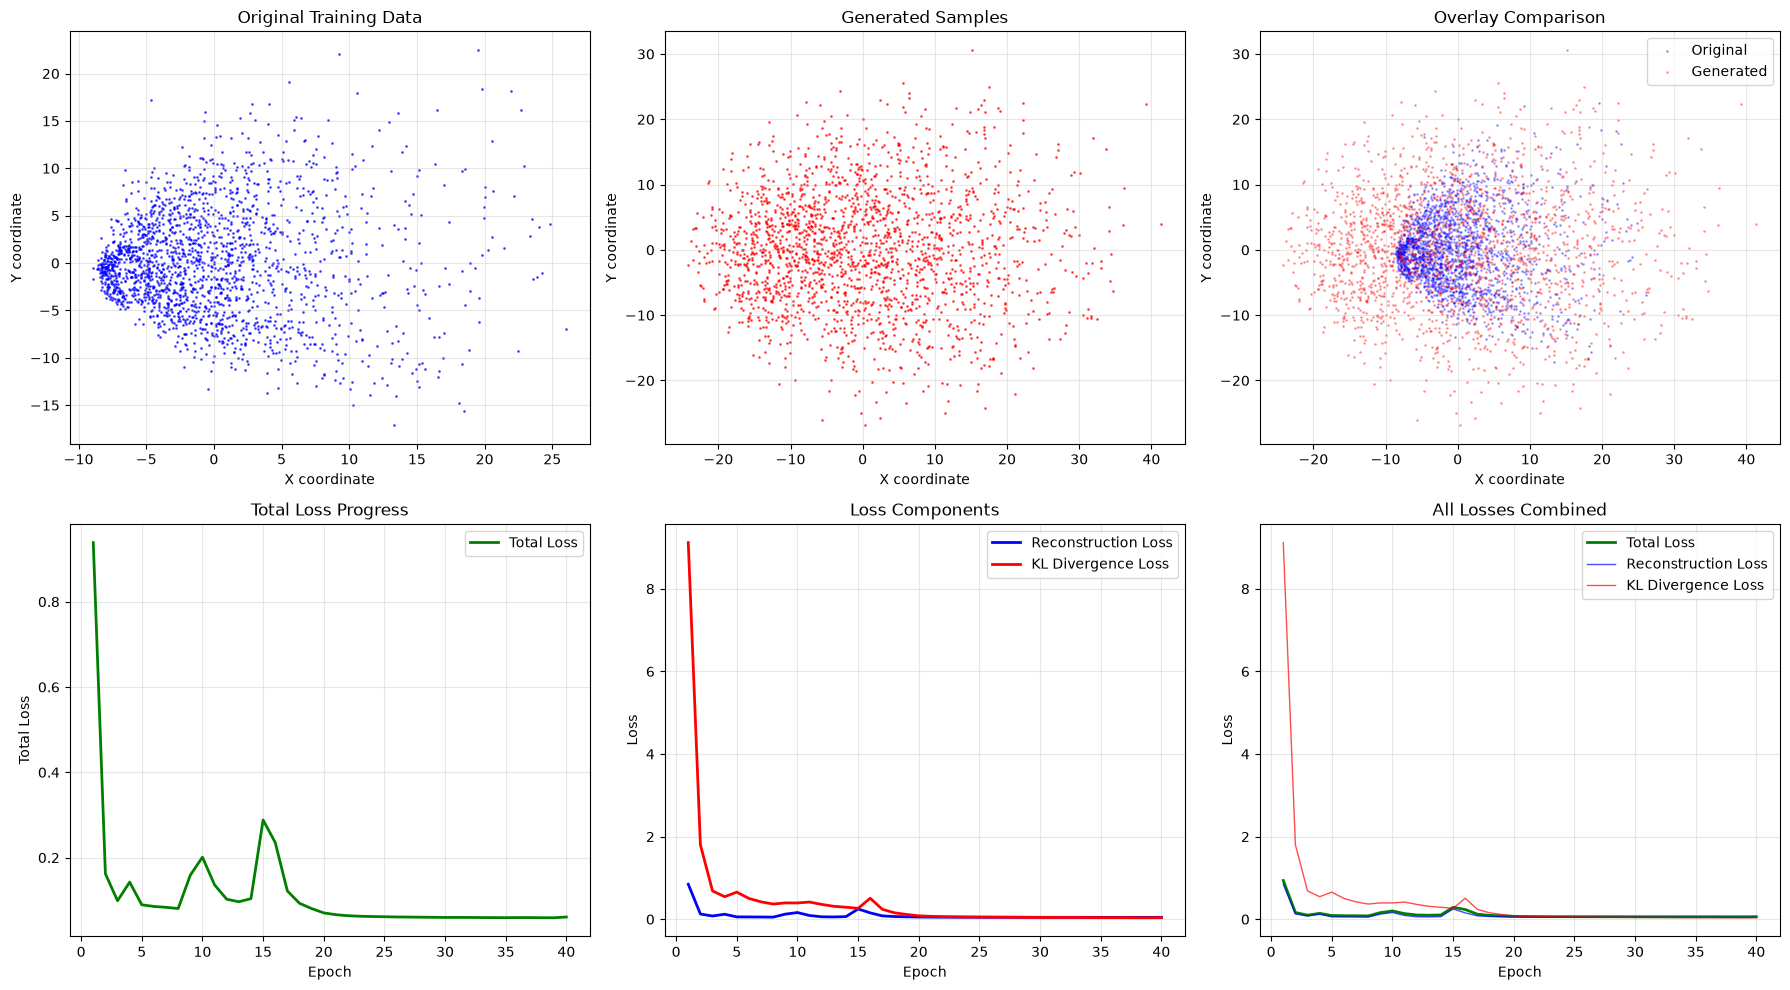

📈 Epoch 40 Summary:
   Total Loss: 0.0608
   Reconstruction Loss: 0.0453
   KL Divergence Loss: 0.0388
   Beta: 0.400
   Learning Rate: 0.000500

📊 Epoch 41/300
----------------------------------------
Epoch: 41 [0/60000 (0%)]	Total Loss: 0.059924	Recon Loss: 0.044179	KL Loss: 0.038401	Beta: 0.410
====> Epoch: 41 Average Total Loss: 0.0597, Average Recon Loss: 0.0446, Average KL Loss: 0.0370, Beta: 0.410
📈 Epoch 41 Summary:
   Total Loss: 0.0597
   Reconstruction Loss: 0.0446
   KL Divergence Loss: 0.0370
   Beta: 0.410
   Learning Rate: 0.000500

📊 Epoch 42/300
----------------------------------------
Epoch: 42 [0/60000 (0%)]	Total Loss: 0.058963	Recon Loss: 0.044418	KL Loss: 0.034632	Beta: 0.420
====> Epoch: 42 Average Total Loss: 0.0589, Average Recon Loss: 0.0443, Average KL Loss: 0.0347, Beta: 0.420
📈 Epoch 42 Summary:
   Total Loss: 0.0589
   Reconstruction Loss: 0.0443
   KL Divergence Loss: 0.0347
   Beta: 0.420
   Learning Rate: 0.000500

📊 Epoch 43/300
-----------------------

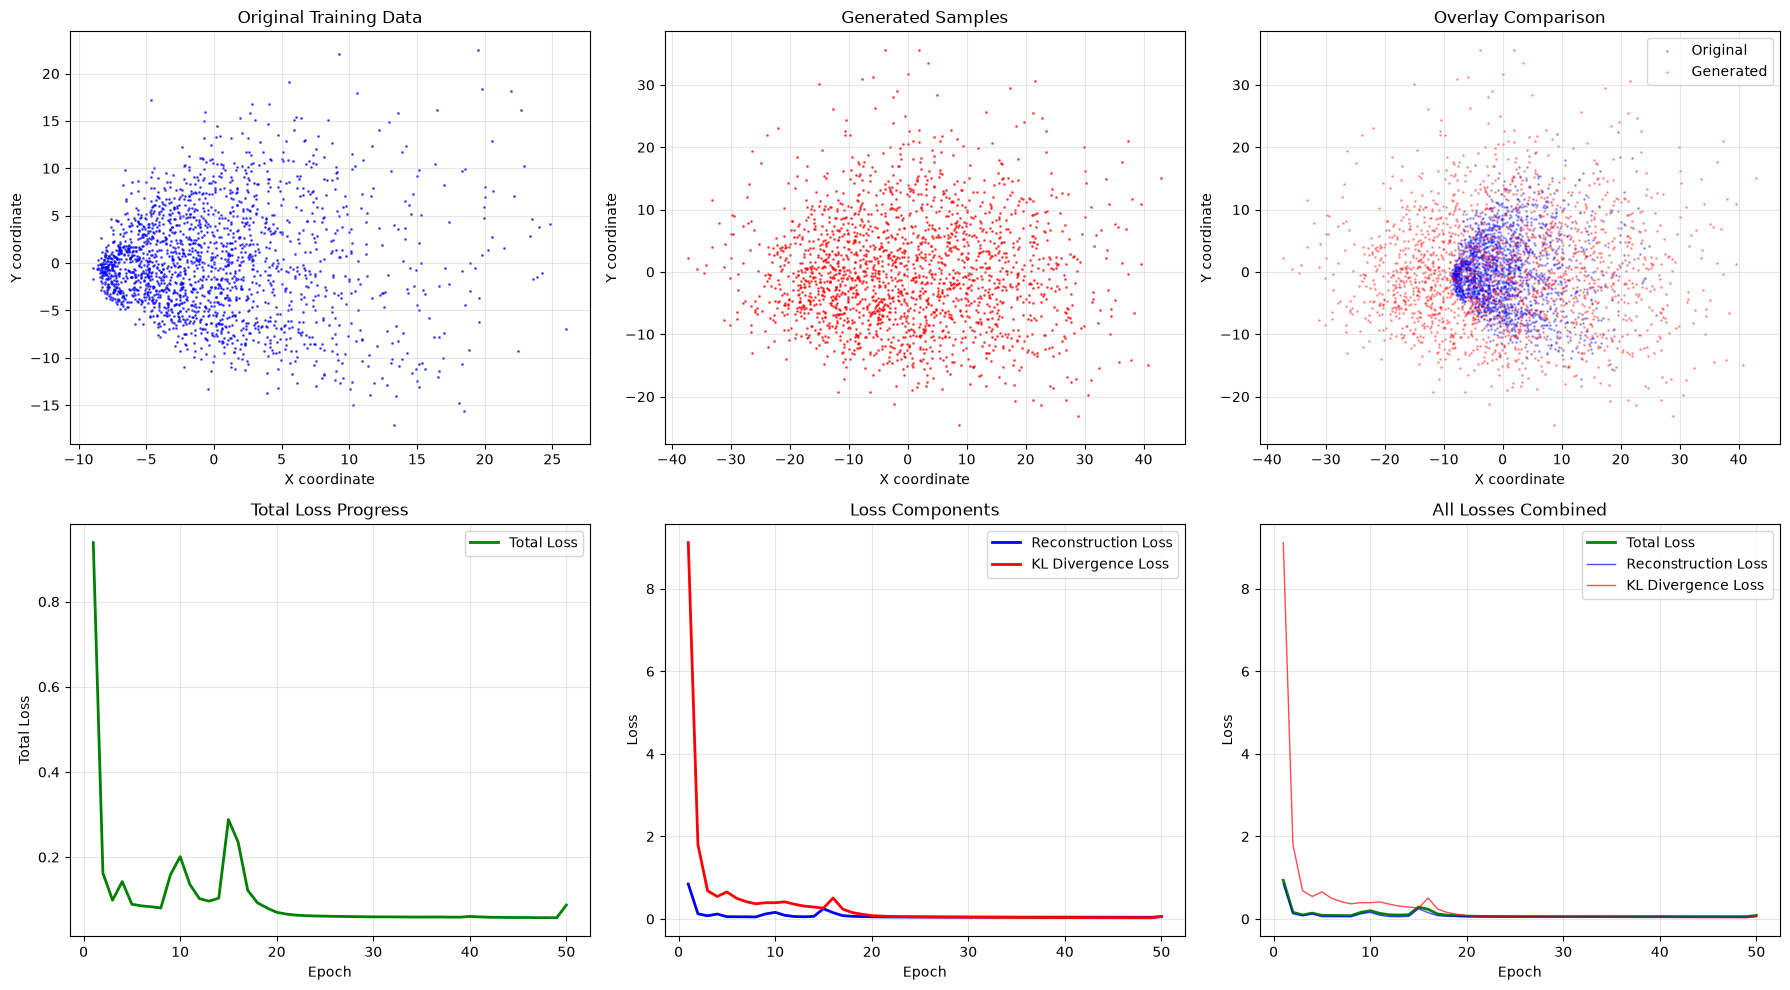

📈 Epoch 50 Summary:
   Total Loss: 0.0875
   Reconstruction Loss: 0.0556
   KL Divergence Loss: 0.0638
   Beta: 0.500
   Learning Rate: 0.000500

📊 Epoch 51/300
----------------------------------------
Epoch: 51 [0/60000 (0%)]	Total Loss: 0.157741	Recon Loss: 0.105716	KL Loss: 0.104154	Beta: 0.500
====> Epoch: 51 Average Total Loss: 0.1043, Average Recon Loss: 0.0694, Average KL Loss: 0.0700, Beta: 0.500
📈 Epoch 51 Summary:
   Total Loss: 0.1043
   Reconstruction Loss: 0.0694
   KL Divergence Loss: 0.0700
   Beta: 0.500
   Learning Rate: 0.000500

📊 Epoch 52/300
----------------------------------------
Epoch: 52 [0/60000 (0%)]	Total Loss: 0.108712	Recon Loss: 0.068565	KL Loss: 0.080612	Beta: 0.498
====> Epoch: 52 Average Total Loss: 0.0868, Average Recon Loss: 0.0570, Average KL Loss: 0.0599, Beta: 0.498
📈 Epoch 52 Summary:
   Total Loss: 0.0868
   Reconstruction Loss: 0.0570
   KL Divergence Loss: 0.0599
   Beta: 0.498
   Learning Rate: 0.000500

📊 Epoch 53/300
-----------------------

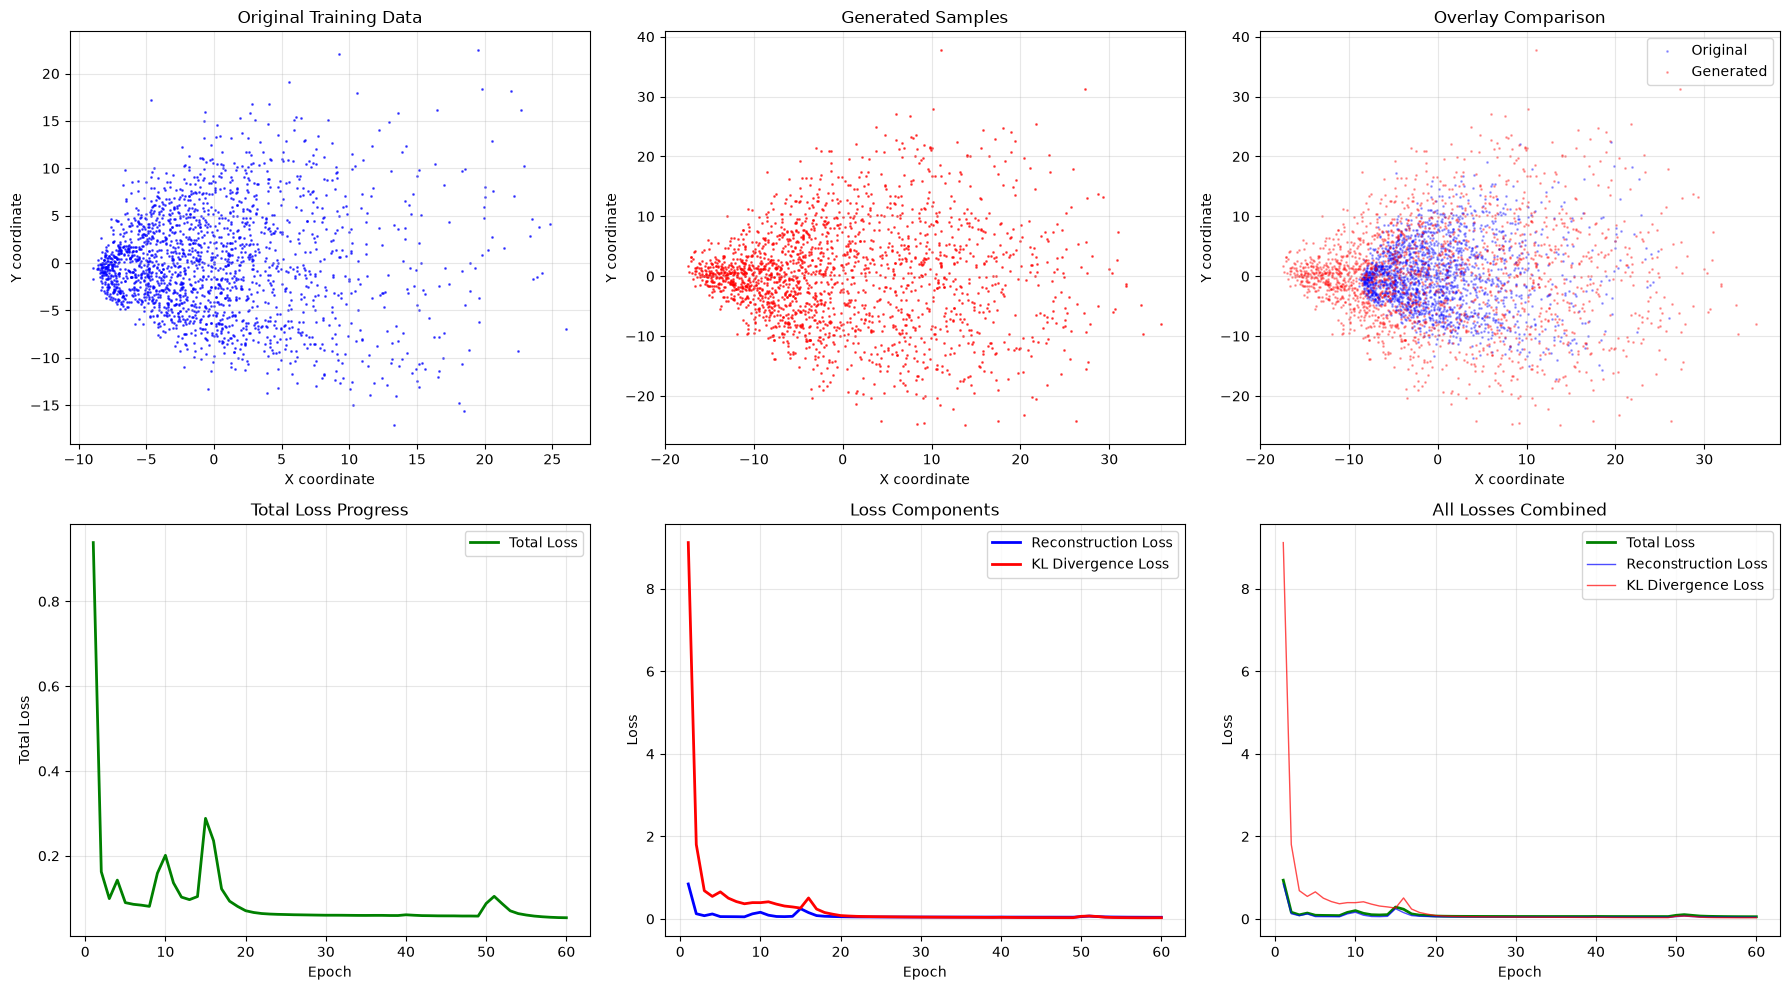

📈 Epoch 60 Summary:
   Total Loss: 0.0538
   Reconstruction Loss: 0.0403
   KL Divergence Loss: 0.0300
   Beta: 0.452
   Learning Rate: 0.000500

📊 Epoch 61/300
----------------------------------------
Epoch: 61 [0/60000 (0%)]	Total Loss: 0.054342	Recon Loss: 0.040797	KL Loss: 0.030601	Beta: 0.443
====> Epoch: 61 Average Total Loss: 0.0544, Average Recon Loss: 0.0404, Average KL Loss: 0.0317, Beta: 0.443
📈 Epoch 61 Summary:
   Total Loss: 0.0544
   Reconstruction Loss: 0.0404
   KL Divergence Loss: 0.0317
   Beta: 0.443
   Learning Rate: 0.000500

📊 Epoch 62/300
----------------------------------------
Epoch: 62 [0/60000 (0%)]	Total Loss: 0.054911	Recon Loss: 0.040054	KL Loss: 0.034372	Beta: 0.432
====> Epoch: 62 Average Total Loss: 0.0534, Average Recon Loss: 0.0395, Average KL Loss: 0.0322, Beta: 0.432
📈 Epoch 62 Summary:
   Total Loss: 0.0534
   Reconstruction Loss: 0.0395
   KL Divergence Loss: 0.0322
   Beta: 0.432
   Learning Rate: 0.000500

📊 Epoch 63/300
-----------------------

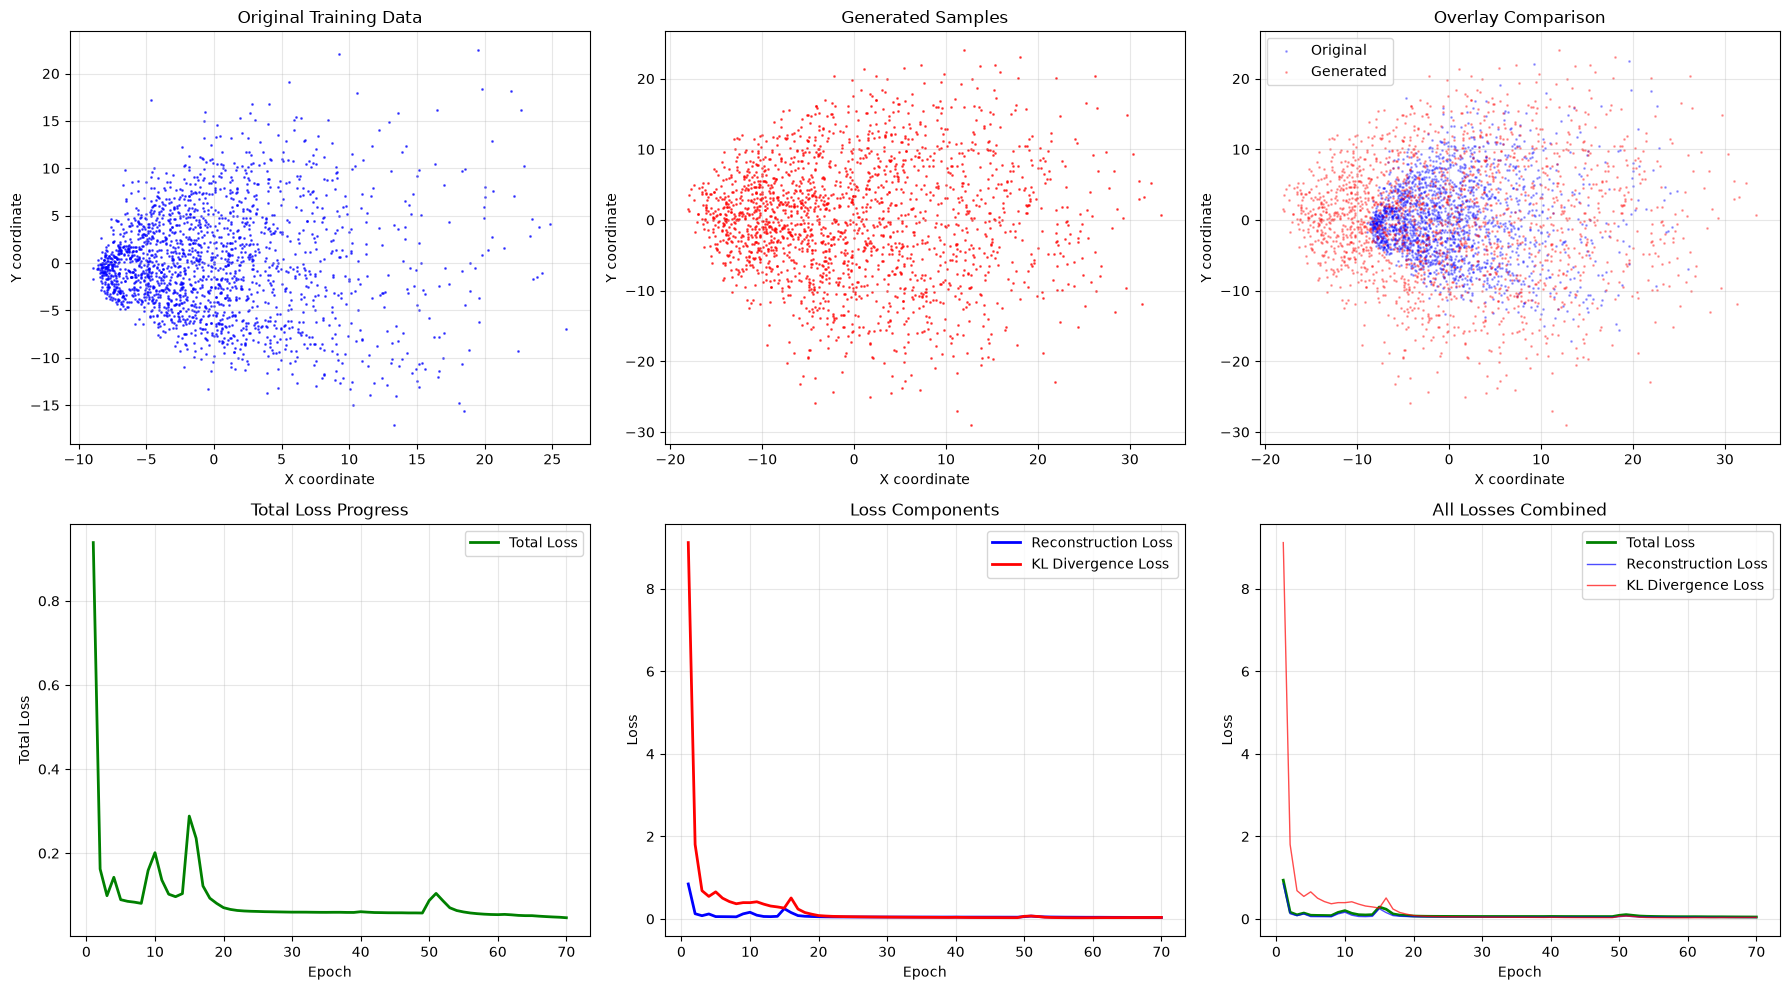

📈 Epoch 70 Summary:
   Total Loss: 0.0465
   Reconstruction Loss: 0.0343
   KL Divergence Loss: 0.0371
   Beta: 0.327
   Learning Rate: 0.000500

📊 Epoch 71/300
----------------------------------------
Epoch: 71 [0/60000 (0%)]	Total Loss: 0.045612	Recon Loss: 0.034116	KL Loss: 0.036827	Beta: 0.312
====> Epoch: 71 Average Total Loss: 0.0461, Average Recon Loss: 0.0340, Average KL Loss: 0.0387, Beta: 0.312
📈 Epoch 71 Summary:
   Total Loss: 0.0461
   Reconstruction Loss: 0.0340
   KL Divergence Loss: 0.0387
   Beta: 0.312
   Learning Rate: 0.000500

📊 Epoch 72/300
----------------------------------------
Epoch: 72 [0/60000 (0%)]	Total Loss: 0.045025	Recon Loss: 0.033188	KL Loss: 0.039876	Beta: 0.297
====> Epoch: 72 Average Total Loss: 0.0449, Average Recon Loss: 0.0331, Average KL Loss: 0.0398, Beta: 0.297
📈 Epoch 72 Summary:
   Total Loss: 0.0449
   Reconstruction Loss: 0.0331
   KL Divergence Loss: 0.0398
   Beta: 0.297
   Learning Rate: 0.000500

📊 Epoch 73/300
-----------------------

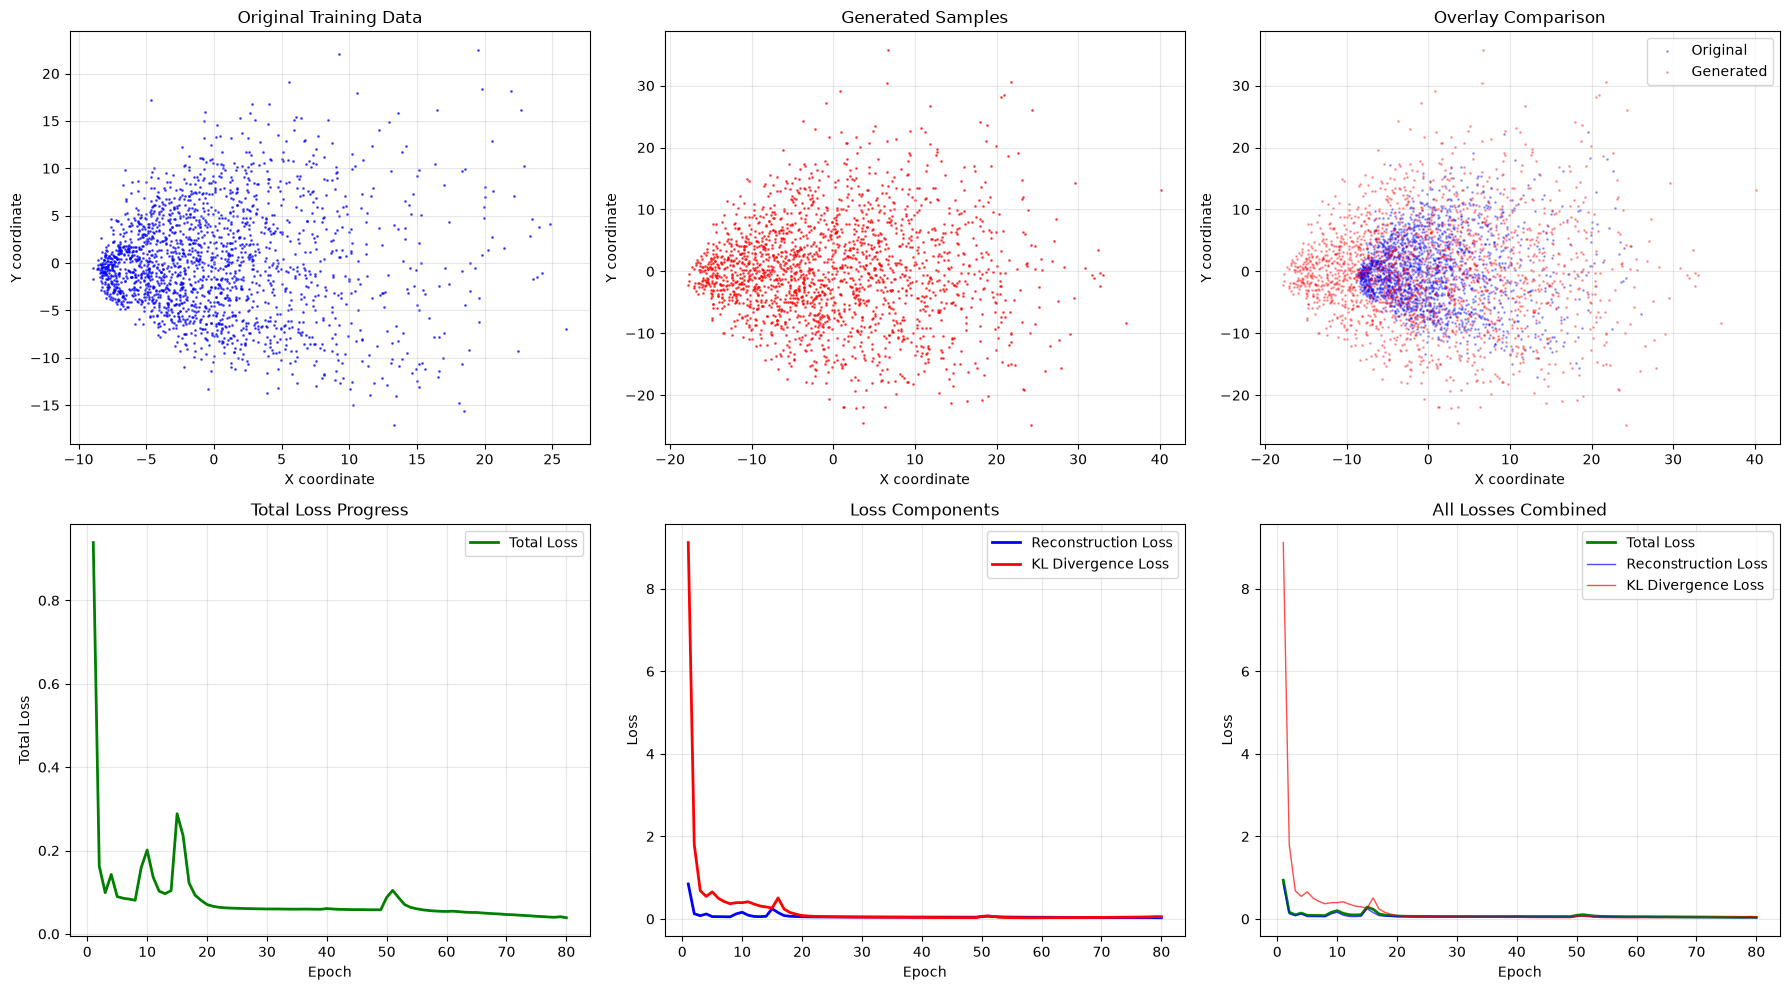

📈 Epoch 80 Summary:
   Total Loss: 0.0387
   Reconstruction Loss: 0.0294
   KL Divergence Loss: 0.0543
   Beta: 0.173
   Learning Rate: 0.000500

📊 Epoch 81/300
----------------------------------------
Epoch: 81 [0/60000 (0%)]	Total Loss: 0.037452	Recon Loss: 0.028395	KL Loss: 0.057337	Beta: 0.158
====> Epoch: 81 Average Total Loss: 0.0370, Average Recon Loss: 0.0279, Average KL Loss: 0.0573, Beta: 0.158
📈 Epoch 81 Summary:
   Total Loss: 0.0370
   Reconstruction Loss: 0.0279
   KL Divergence Loss: 0.0573
   Beta: 0.158
   Learning Rate: 0.000500

📊 Epoch 82/300
----------------------------------------
Epoch: 82 [0/60000 (0%)]	Total Loss: 0.035700	Recon Loss: 0.027603	KL Loss: 0.056399	Beta: 0.144
====> Epoch: 82 Average Total Loss: 0.0354, Average Recon Loss: 0.0270, Average KL Loss: 0.0582, Beta: 0.144
📈 Epoch 82 Summary:
   Total Loss: 0.0354
   Reconstruction Loss: 0.0270
   KL Divergence Loss: 0.0582
   Beta: 0.144
   Learning Rate: 0.000500

📊 Epoch 83/300
-----------------------

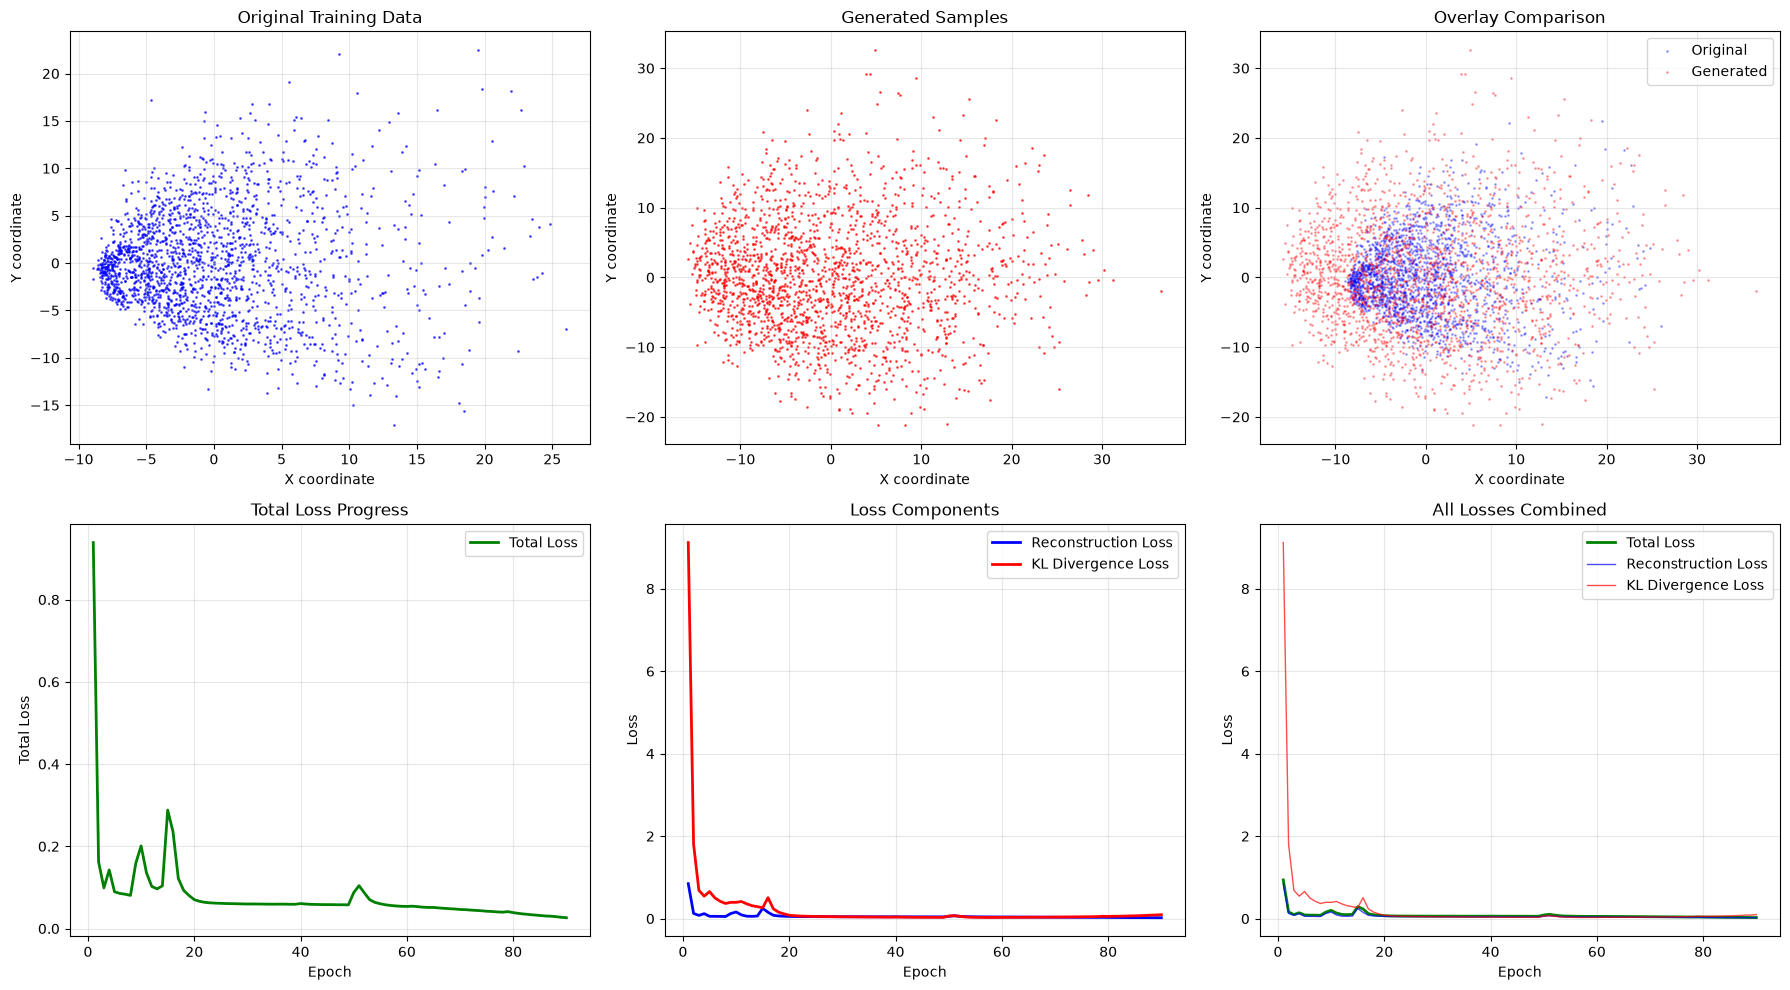

📈 Epoch 90 Summary:
   Total Loss: 0.0263
   Reconstruction Loss: 0.0217
   KL Divergence Loss: 0.0964
   Beta: 0.048
   Learning Rate: 0.000500

📊 Epoch 91/300
----------------------------------------
Epoch: 91 [0/60000 (0%)]	Total Loss: 0.025124	Recon Loss: 0.021222	KL Loss: 0.100268	Beta: 0.039
====> Epoch: 91 Average Total Loss: 0.0250, Average Recon Loss: 0.0210, Average KL Loss: 0.1034, Beta: 0.039
📈 Epoch 91 Summary:
   Total Loss: 0.0250
   Reconstruction Loss: 0.0210
   KL Divergence Loss: 0.1034
   Beta: 0.039
   Learning Rate: 0.000500

📊 Epoch 92/300
----------------------------------------
Epoch: 92 [0/60000 (0%)]	Total Loss: 0.023969	Recon Loss: 0.020633	KL Loss: 0.107885	Beta: 0.031
====> Epoch: 92 Average Total Loss: 0.0237, Average Recon Loss: 0.0201, Average KL Loss: 0.1142, Beta: 0.031
📈 Epoch 92 Summary:
   Total Loss: 0.0237
   Reconstruction Loss: 0.0201
   KL Divergence Loss: 0.1142
   Beta: 0.031
   Learning Rate: 0.000500

📊 Epoch 93/300
-----------------------

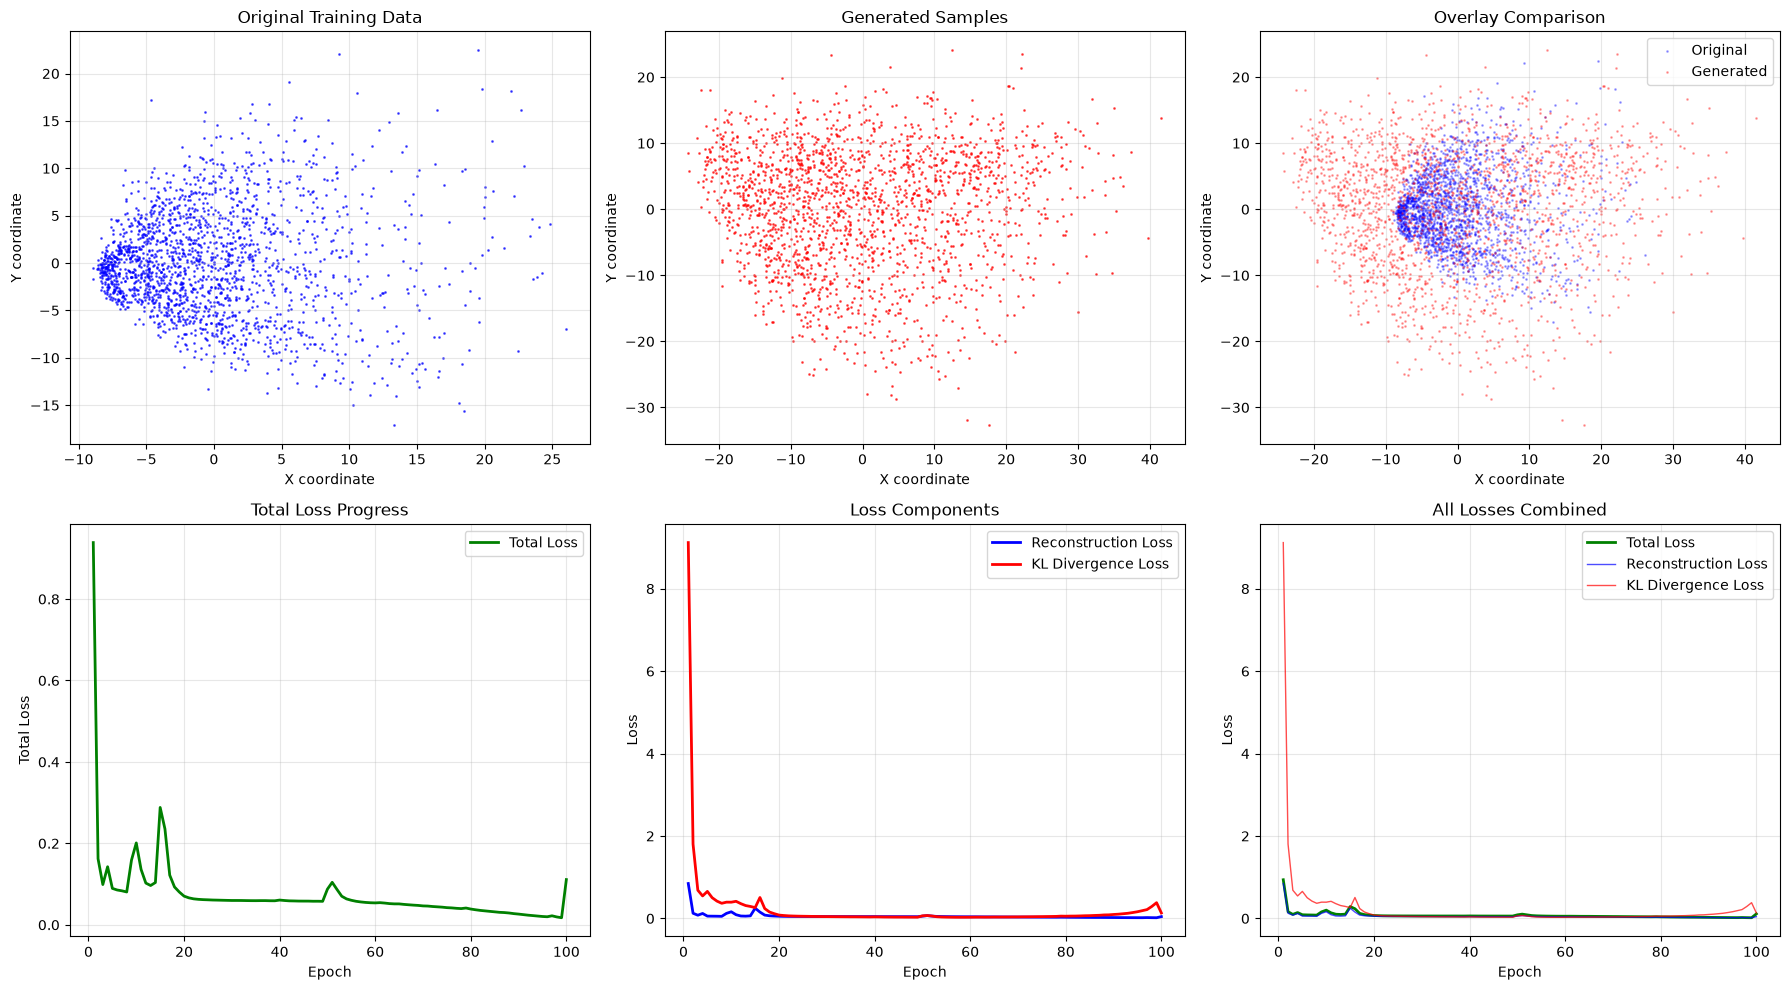

📈 Epoch 100 Summary:
   Total Loss: 0.1111
   Reconstruction Loss: 0.0443
   KL Divergence Loss: 0.1335
   Beta: 0.500
   Learning Rate: 0.000500

📊 Epoch 101/300
----------------------------------------
Epoch: 101 [0/60000 (0%)]	Total Loss: 0.081736	Recon Loss: 0.050223	KL Loss: 0.063088	Beta: 0.500
====> Epoch: 101 Average Total Loss: 0.0738, Average Recon Loss: 0.0485, Average KL Loss: 0.0507, Beta: 0.500
📈 Epoch 101 Summary:
   Total Loss: 0.0738
   Reconstruction Loss: 0.0485
   KL Divergence Loss: 0.0507
   Beta: 0.500
   Learning Rate: 0.000500

📊 Epoch 102/300
----------------------------------------
Epoch: 102 [0/60000 (0%)]	Total Loss: 0.067081	Recon Loss: 0.046671	KL Loss: 0.040982	Beta: 0.498
====> Epoch: 102 Average Total Loss: 0.0635, Average Recon Loss: 0.0461, Average KL Loss: 0.0348, Beta: 0.498
📈 Epoch 102 Summary:
   Total Loss: 0.0635
   Reconstruction Loss: 0.0461
   KL Divergence Loss: 0.0348
   Beta: 0.498
   Learning Rate: 0.000500

📊 Epoch 103/300
-------------

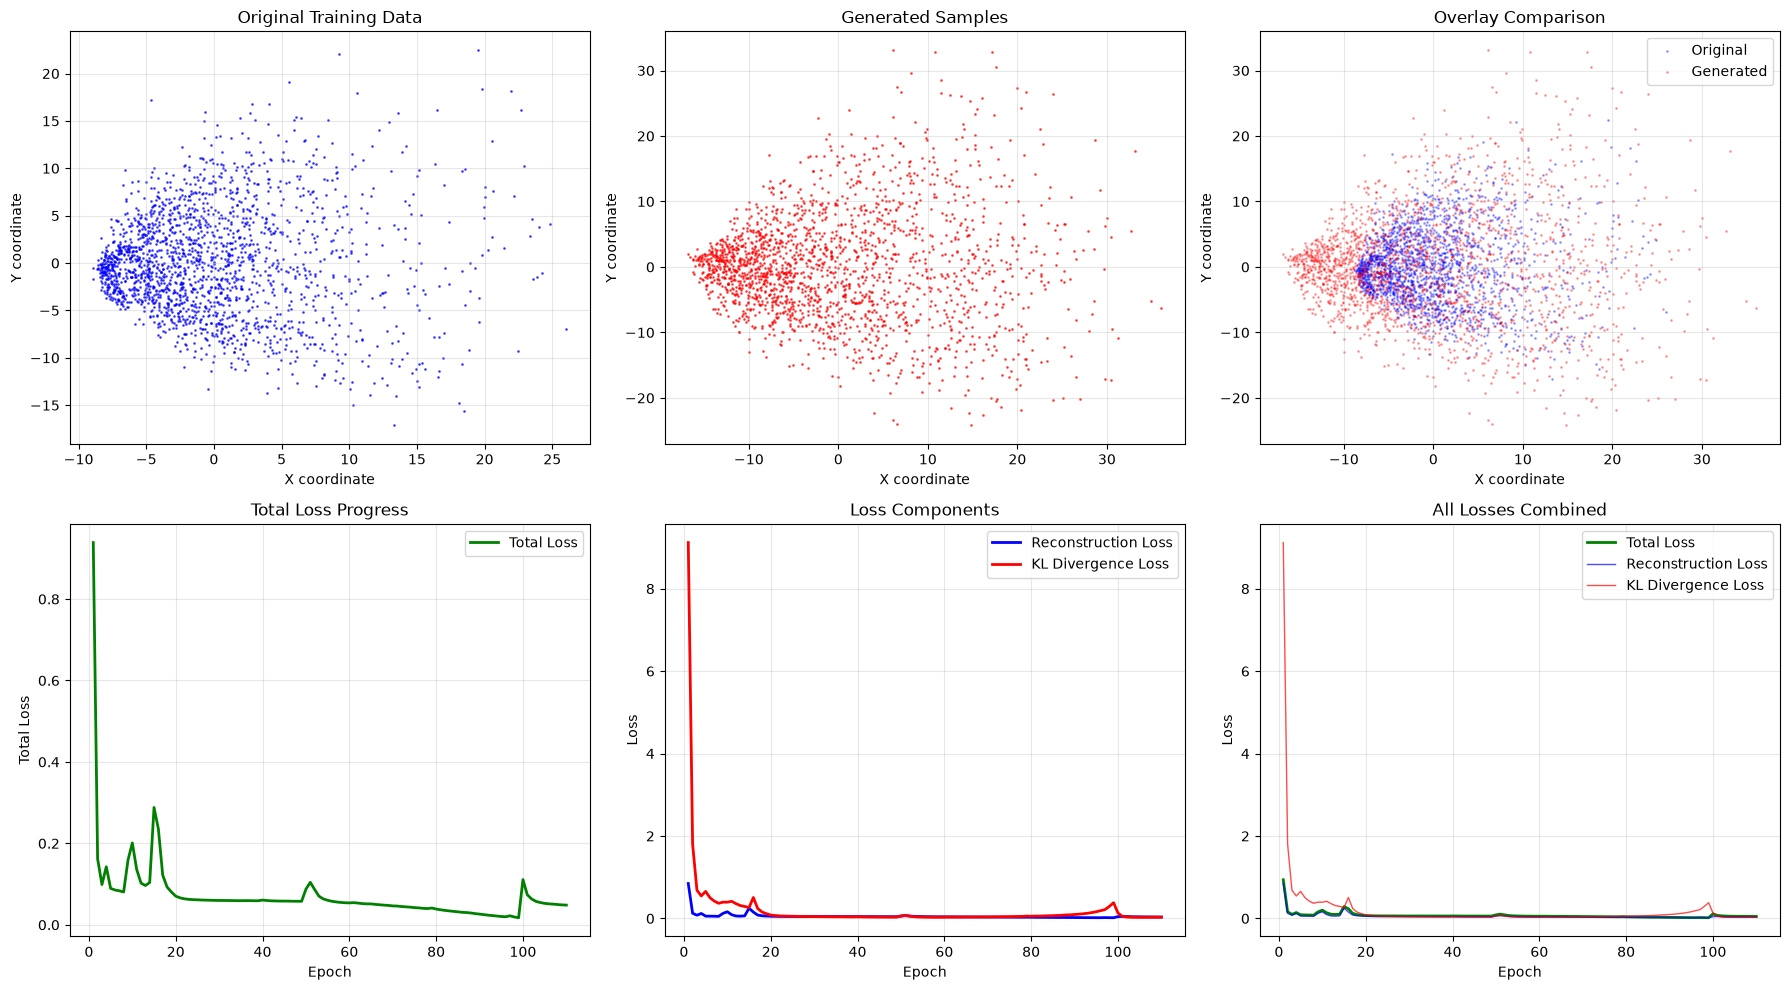

📈 Epoch 110 Summary:
   Total Loss: 0.0484
   Reconstruction Loss: 0.0353
   KL Divergence Loss: 0.0291
   Beta: 0.452
   Learning Rate: 0.000500

📊 Epoch 111/300
----------------------------------------
Epoch: 111 [0/60000 (0%)]	Total Loss: 0.049239	Recon Loss: 0.035634	KL Loss: 0.030736	Beta: 0.443
====> Epoch: 111 Average Total Loss: 0.0481, Average Recon Loss: 0.0348, Average KL Loss: 0.0300, Beta: 0.443
📈 Epoch 111 Summary:
   Total Loss: 0.0481
   Reconstruction Loss: 0.0348
   KL Divergence Loss: 0.0300
   Beta: 0.443
   Learning Rate: 0.000500

📊 Epoch 112/300
----------------------------------------
Epoch: 112 [0/60000 (0%)]	Total Loss: 0.047175	Recon Loss: 0.034089	KL Loss: 0.030274	Beta: 0.432
====> Epoch: 112 Average Total Loss: 0.0474, Average Recon Loss: 0.0342, Average KL Loss: 0.0305, Beta: 0.432
📈 Epoch 112 Summary:
   Total Loss: 0.0474
   Reconstruction Loss: 0.0342
   KL Divergence Loss: 0.0305
   Beta: 0.432
   Learning Rate: 0.000500

📊 Epoch 113/300
-------------

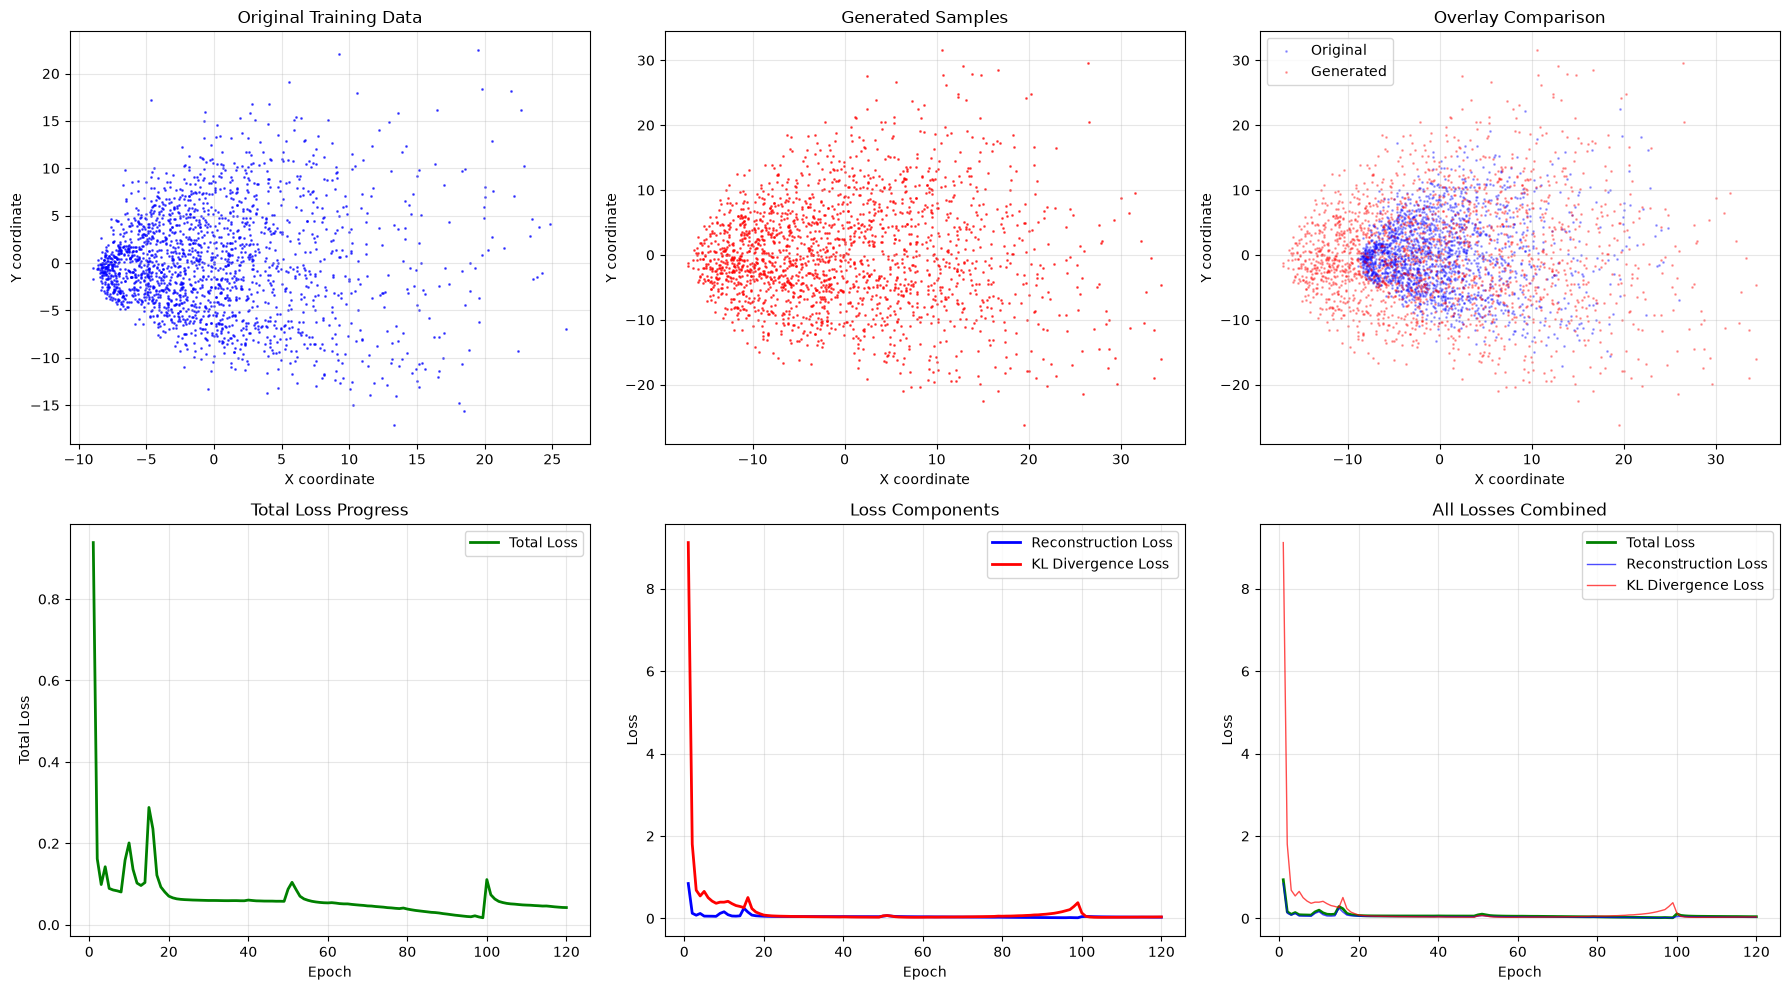

📈 Epoch 120 Summary:
   Total Loss: 0.0424
   Reconstruction Loss: 0.0302
   KL Divergence Loss: 0.0373
   Beta: 0.327
   Learning Rate: 0.000250

📊 Epoch 121/300
----------------------------------------
Epoch: 121 [0/60000 (0%)]	Total Loss: 0.041907	Recon Loss: 0.029937	KL Loss: 0.038343	Beta: 0.312
====> Epoch: 121 Average Total Loss: 0.0415, Average Recon Loss: 0.0296, Average KL Loss: 0.0379, Beta: 0.312
📈 Epoch 121 Summary:
   Total Loss: 0.0415
   Reconstruction Loss: 0.0296
   KL Divergence Loss: 0.0379
   Beta: 0.312
   Learning Rate: 0.000250

📊 Epoch 122/300
----------------------------------------
Epoch: 122 [0/60000 (0%)]	Total Loss: 0.040553	Recon Loss: 0.029410	KL Loss: 0.037541	Beta: 0.297
====> Epoch: 122 Average Total Loss: 0.0404, Average Recon Loss: 0.0289, Average KL Loss: 0.0386, Beta: 0.297
📈 Epoch 122 Summary:
   Total Loss: 0.0404
   Reconstruction Loss: 0.0289
   KL Divergence Loss: 0.0386
   Beta: 0.297
   Learning Rate: 0.000250

📊 Epoch 123/300
-------------

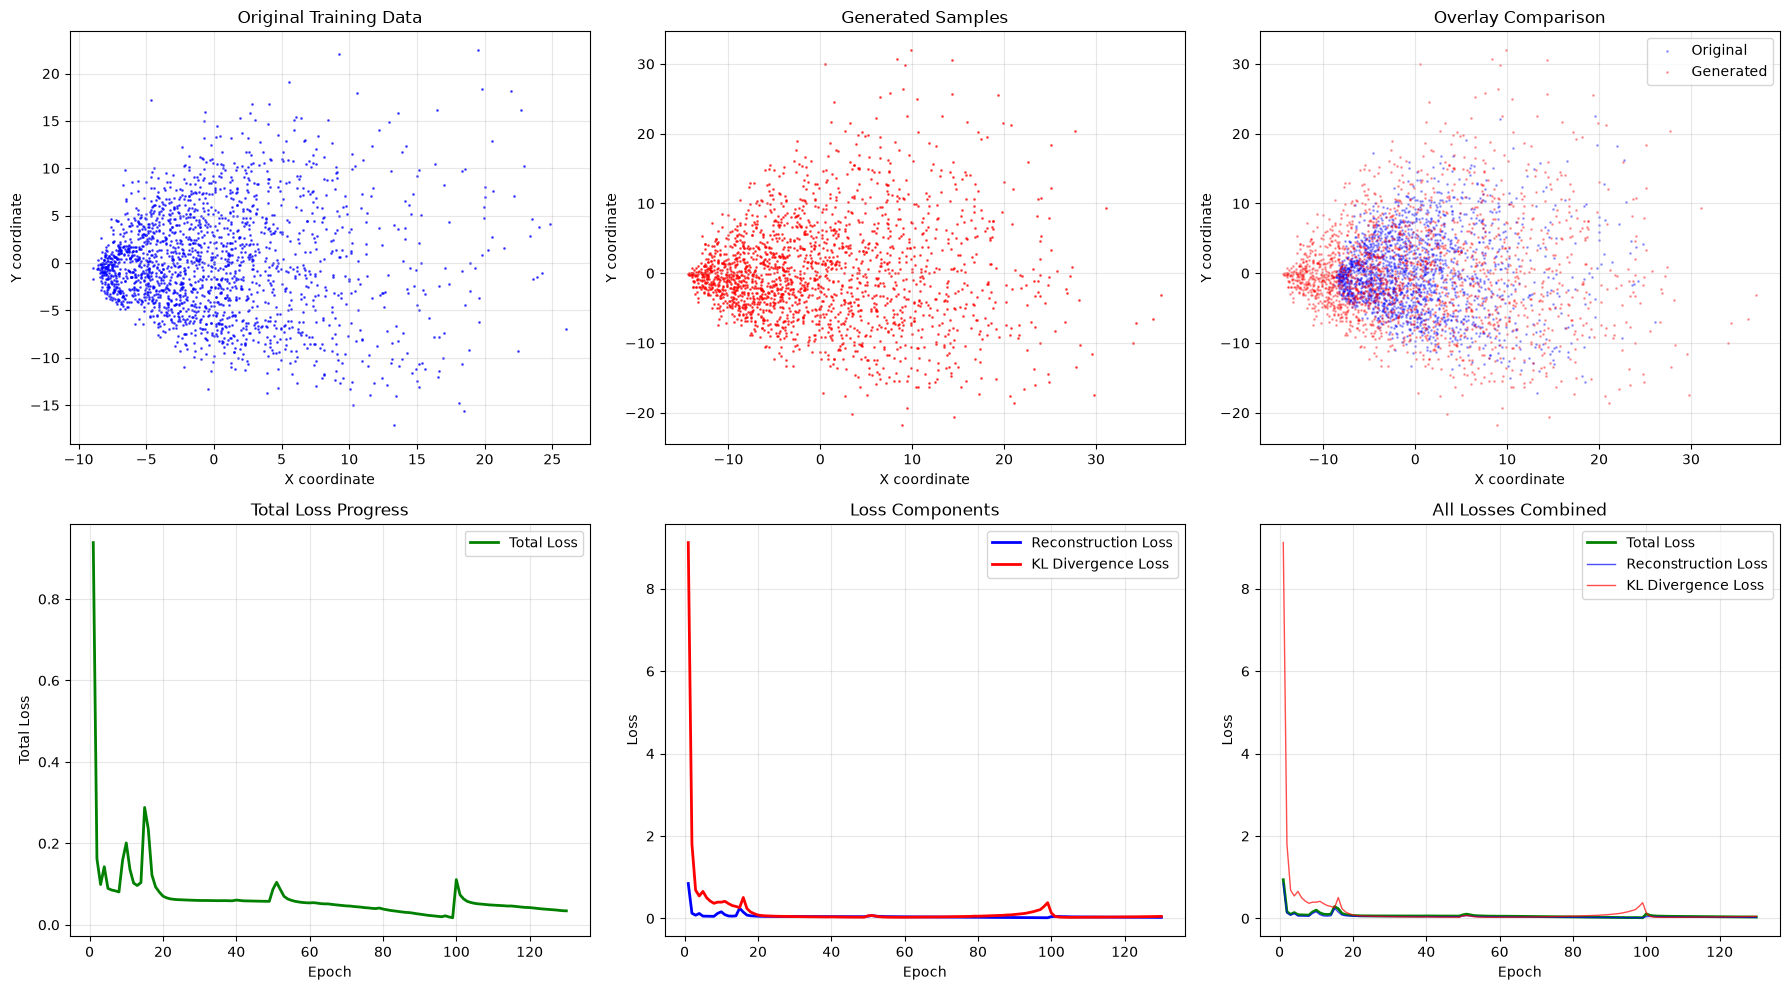

📈 Epoch 130 Summary:
   Total Loss: 0.0343
   Reconstruction Loss: 0.0258
   KL Divergence Loss: 0.0494
   Beta: 0.173
   Learning Rate: 0.000250

📊 Epoch 131/300
----------------------------------------
Epoch: 131 [0/60000 (0%)]	Total Loss: 0.033090	Recon Loss: 0.025207	KL Loss: 0.049901	Beta: 0.158
====> Epoch: 131 Average Total Loss: 0.0332, Average Recon Loss: 0.0253, Average KL Loss: 0.0503, Beta: 0.158
📈 Epoch 131 Summary:
   Total Loss: 0.0332
   Reconstruction Loss: 0.0253
   KL Divergence Loss: 0.0503
   Beta: 0.158
   Learning Rate: 0.000250

📊 Epoch 132/300
----------------------------------------
Epoch: 132 [0/60000 (0%)]	Total Loss: 0.032251	Recon Loss: 0.024899	KL Loss: 0.051217	Beta: 0.144
====> Epoch: 132 Average Total Loss: 0.0324, Average Recon Loss: 0.0250, Average KL Loss: 0.0520, Beta: 0.144
📈 Epoch 132 Summary:
   Total Loss: 0.0324
   Reconstruction Loss: 0.0250
   KL Divergence Loss: 0.0520
   Beta: 0.144
   Learning Rate: 0.000250

📊 Epoch 133/300
-------------

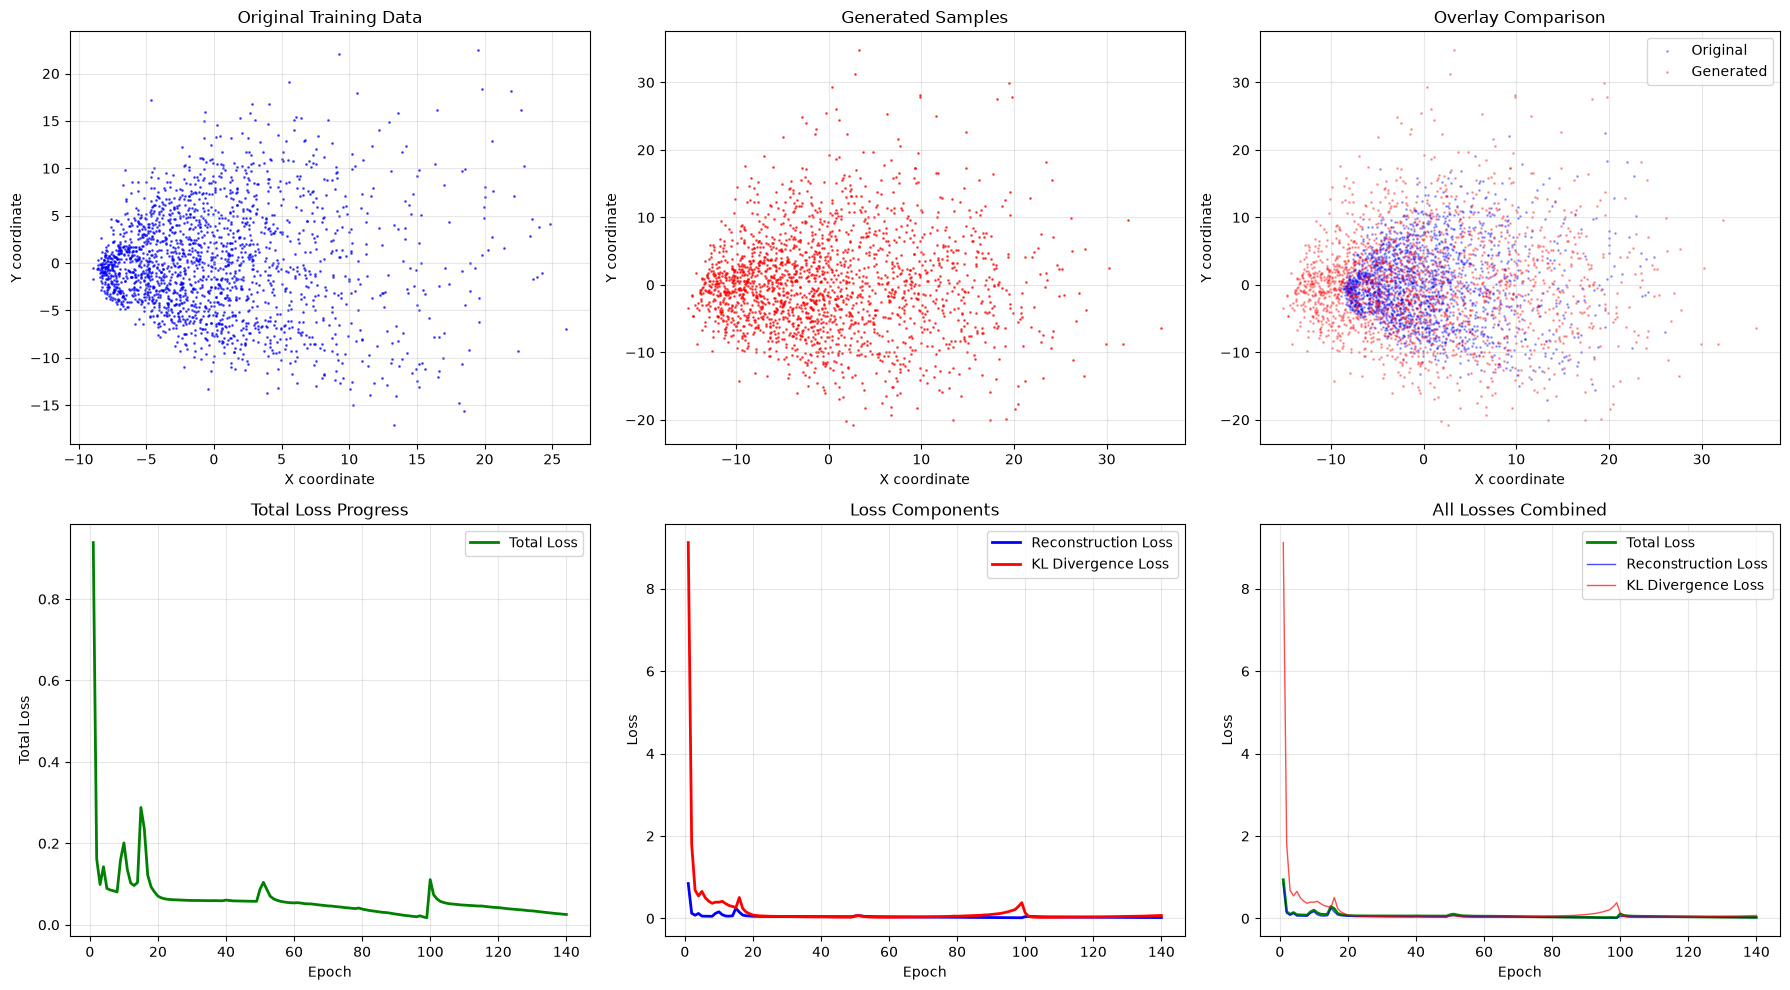

📈 Epoch 140 Summary:
   Total Loss: 0.0254
   Reconstruction Loss: 0.0219
   KL Divergence Loss: 0.0718
   Beta: 0.048
   Learning Rate: 0.000250

📊 Epoch 141/300
----------------------------------------
Epoch: 141 [0/60000 (0%)]	Total Loss: 0.024595	Recon Loss: 0.021679	KL Loss: 0.074907	Beta: 0.039
====> Epoch: 141 Average Total Loss: 0.0245, Average Recon Loss: 0.0216, Average KL Loss: 0.0762, Beta: 0.039
📈 Epoch 141 Summary:
   Total Loss: 0.0245
   Reconstruction Loss: 0.0216
   KL Divergence Loss: 0.0762
   Beta: 0.039
   Learning Rate: 0.000125

📊 Epoch 142/300
----------------------------------------
Epoch: 142 [0/60000 (0%)]	Total Loss: 0.023781	Recon Loss: 0.021361	KL Loss: 0.078241	Beta: 0.031
====> Epoch: 142 Average Total Loss: 0.0234, Average Recon Loss: 0.0209, Average KL Loss: 0.0793, Beta: 0.031
📈 Epoch 142 Summary:
   Total Loss: 0.0234
   Reconstruction Loss: 0.0209
   KL Divergence Loss: 0.0793
   Beta: 0.031
   Learning Rate: 0.000125

📊 Epoch 143/300
-------------

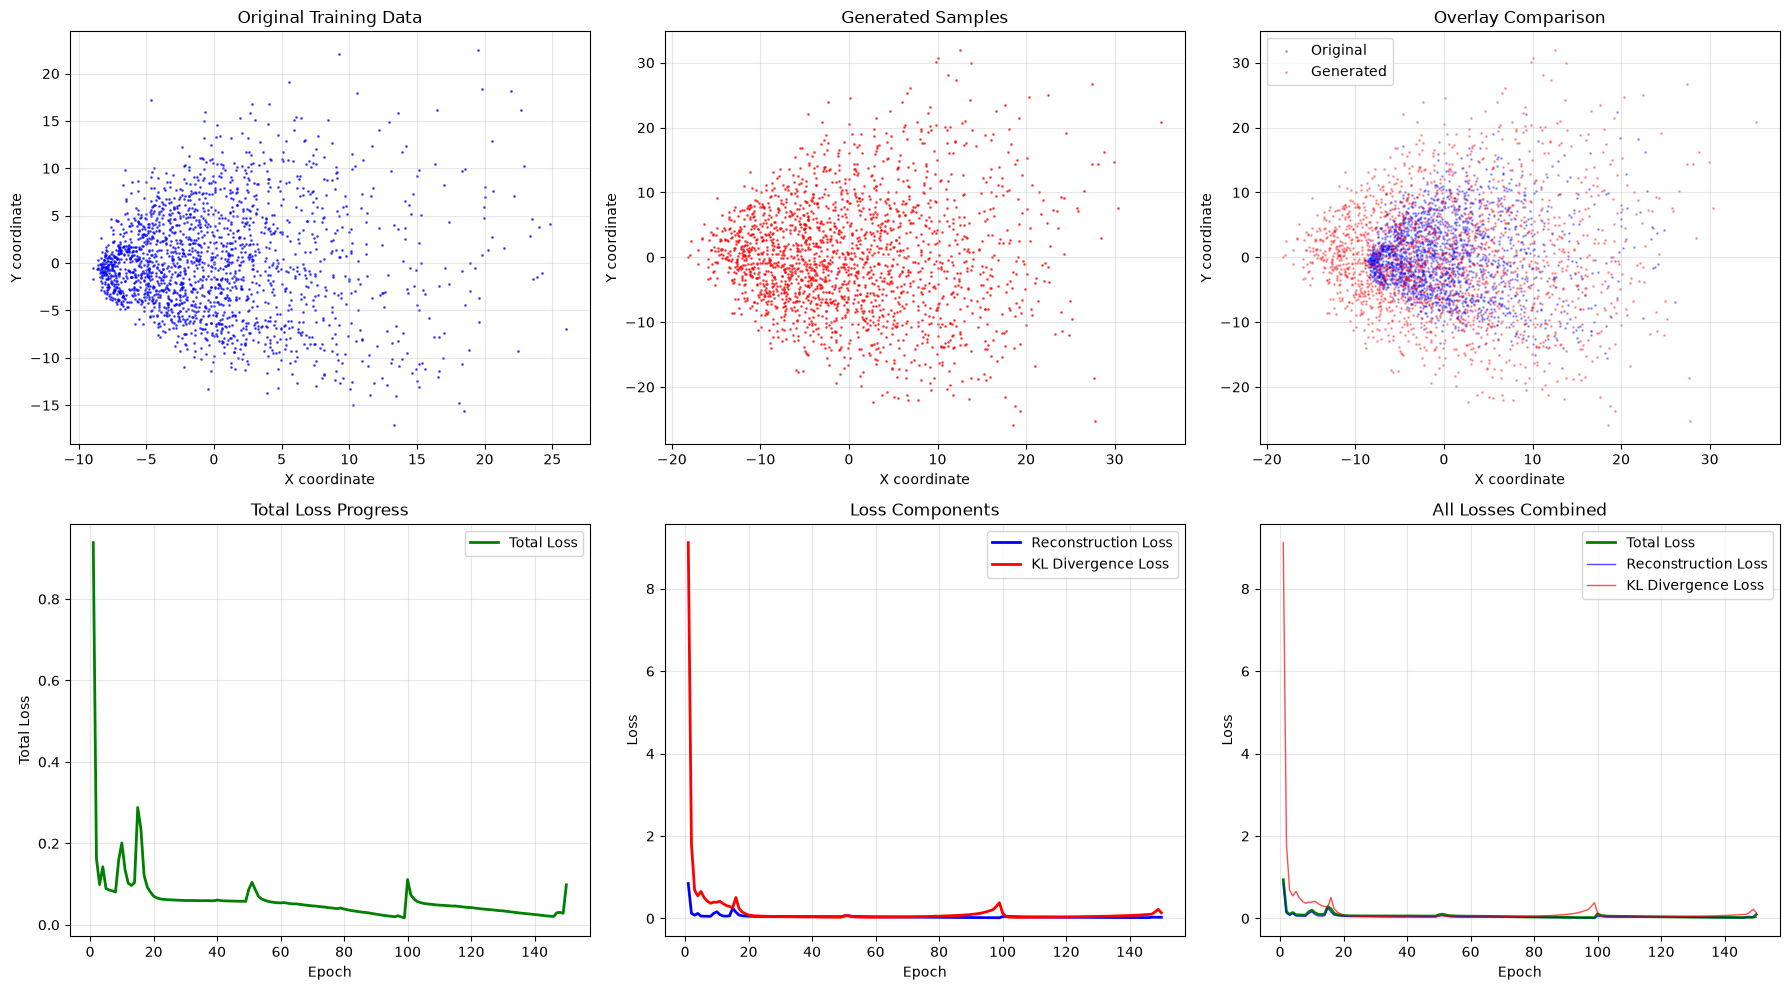

📈 Epoch 150 Summary:
   Total Loss: 0.0981
   Reconstruction Loss: 0.0292
   KL Divergence Loss: 0.1379
   Beta: 0.500
   Learning Rate: 0.000125

📊 Epoch 151/300
----------------------------------------
Epoch: 151 [0/60000 (0%)]	Total Loss: 0.066350	Recon Loss: 0.036220	KL Loss: 0.060320	Beta: 0.500
====> Epoch: 151 Average Total Loss: 0.0615, Average Recon Loss: 0.0373, Average KL Loss: 0.0484, Beta: 0.500
📈 Epoch 151 Summary:
   Total Loss: 0.0615
   Reconstruction Loss: 0.0373
   KL Divergence Loss: 0.0484
   Beta: 0.500
   Learning Rate: 0.000125

📊 Epoch 152/300
----------------------------------------
Epoch: 152 [0/60000 (0%)]	Total Loss: 0.056103	Recon Loss: 0.036259	KL Loss: 0.039845	Beta: 0.498
====> Epoch: 152 Average Total Loss: 0.0541, Average Recon Loss: 0.0351, Average KL Loss: 0.0381, Beta: 0.498
📈 Epoch 152 Summary:
   Total Loss: 0.0541
   Reconstruction Loss: 0.0351
   KL Divergence Loss: 0.0381
   Beta: 0.498
   Learning Rate: 0.000125

📊 Epoch 153/300
-------------

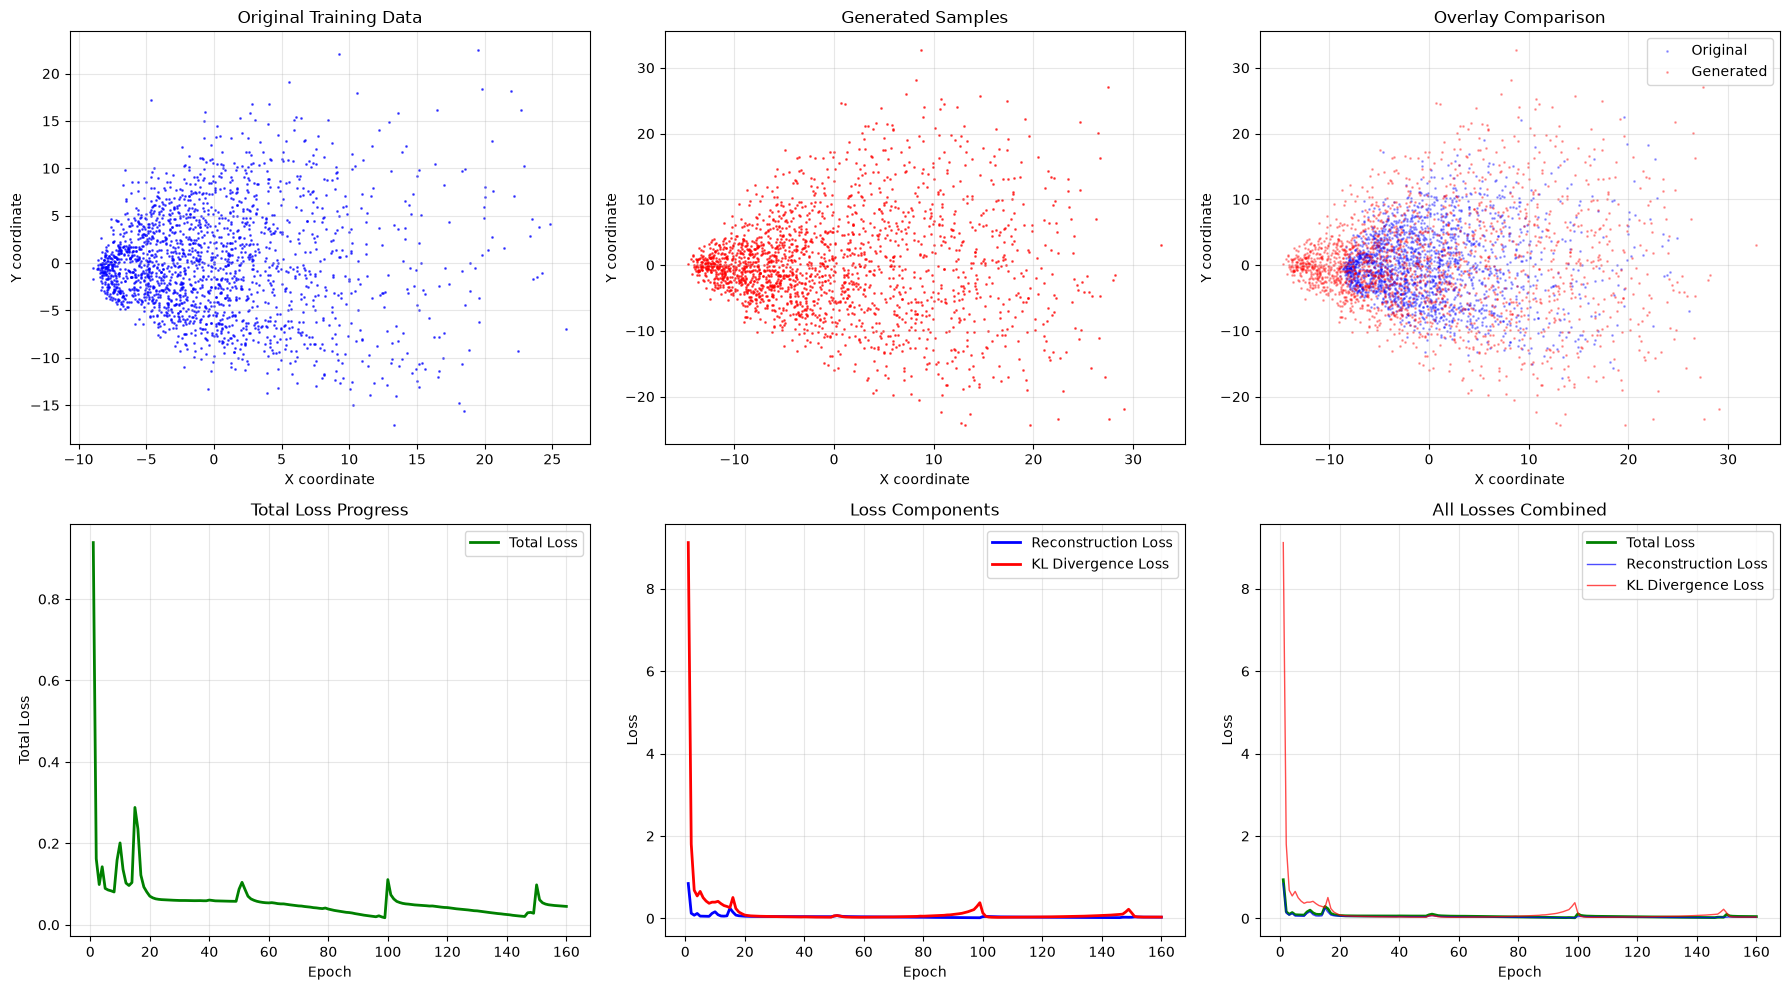

📈 Epoch 160 Summary:
   Total Loss: 0.0452
   Reconstruction Loss: 0.0300
   KL Divergence Loss: 0.0337
   Beta: 0.452
   Learning Rate: 0.000125

📊 Epoch 161/300
----------------------------------------
Epoch: 161 [0/60000 (0%)]	Total Loss: 0.045135	Recon Loss: 0.030234	KL Loss: 0.033663	Beta: 0.443
====> Epoch: 161 Average Total Loss: 0.0449, Average Recon Loss: 0.0298, Average KL Loss: 0.0341, Beta: 0.443
📈 Epoch 161 Summary:
   Total Loss: 0.0449
   Reconstruction Loss: 0.0298
   KL Divergence Loss: 0.0341
   Beta: 0.443
   Learning Rate: 0.000125

📊 Epoch 162/300
----------------------------------------
Epoch: 162 [0/60000 (0%)]	Total Loss: 0.044583	Recon Loss: 0.029643	KL Loss: 0.034563	Beta: 0.432
====> Epoch: 162 Average Total Loss: 0.0442, Average Recon Loss: 0.0293, Average KL Loss: 0.0347, Beta: 0.432
📈 Epoch 162 Summary:
   Total Loss: 0.0442
   Reconstruction Loss: 0.0293
   KL Divergence Loss: 0.0347
   Beta: 0.432
   Learning Rate: 0.000063

📊 Epoch 163/300
-------------

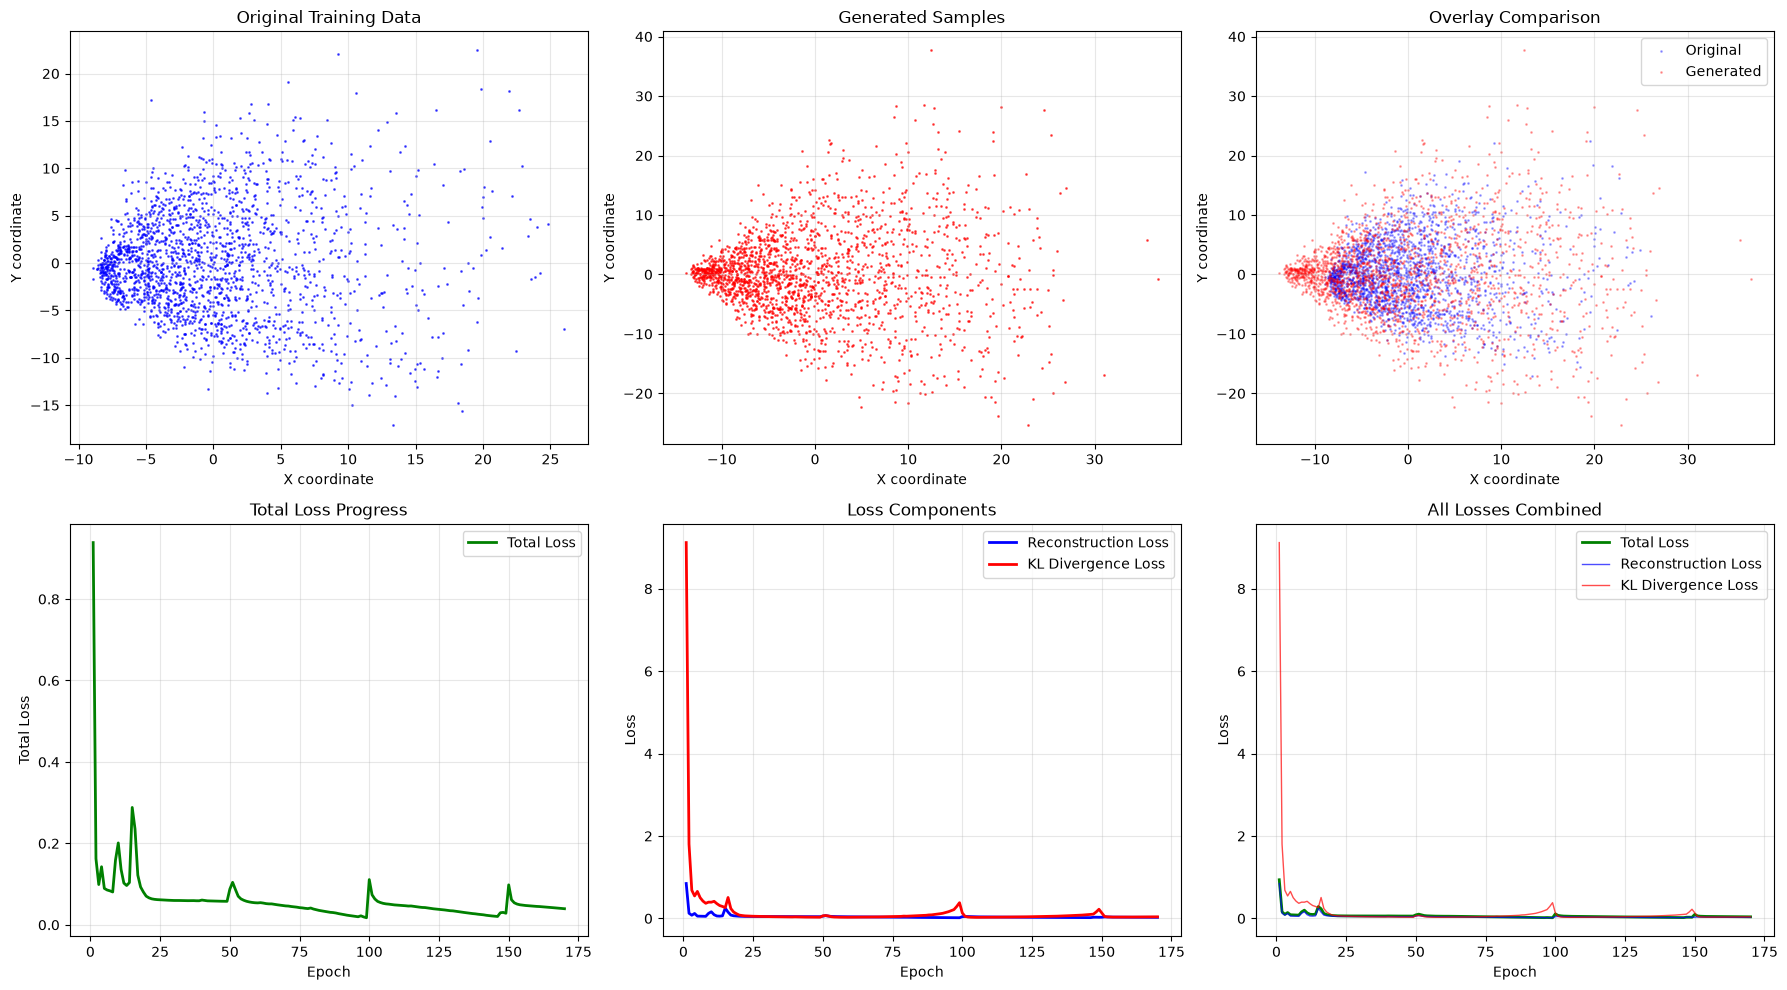

📈 Epoch 170 Summary:
   Total Loss: 0.0395
   Reconstruction Loss: 0.0267
   KL Divergence Loss: 0.0392
   Beta: 0.327
   Learning Rate: 0.000063

📊 Epoch 171/300
----------------------------------------
Epoch: 171 [0/60000 (0%)]	Total Loss: 0.038900	Recon Loss: 0.026405	KL Loss: 0.040026	Beta: 0.312
====> Epoch: 171 Average Total Loss: 0.0389, Average Recon Loss: 0.0264, Average KL Loss: 0.0400, Beta: 0.312
📈 Epoch 171 Summary:
   Total Loss: 0.0389
   Reconstruction Loss: 0.0264
   KL Divergence Loss: 0.0400
   Beta: 0.312
   Learning Rate: 0.000063

📊 Epoch 172/300
----------------------------------------
Epoch: 172 [0/60000 (0%)]	Total Loss: 0.038341	Recon Loss: 0.026378	KL Loss: 0.040301	Beta: 0.297
====> Epoch: 172 Average Total Loss: 0.0382, Average Recon Loss: 0.0261, Average KL Loss: 0.0409, Beta: 0.297
📈 Epoch 172 Summary:
   Total Loss: 0.0382
   Reconstruction Loss: 0.0261
   KL Divergence Loss: 0.0409
   Beta: 0.297
   Learning Rate: 0.000063

📊 Epoch 173/300
-------------

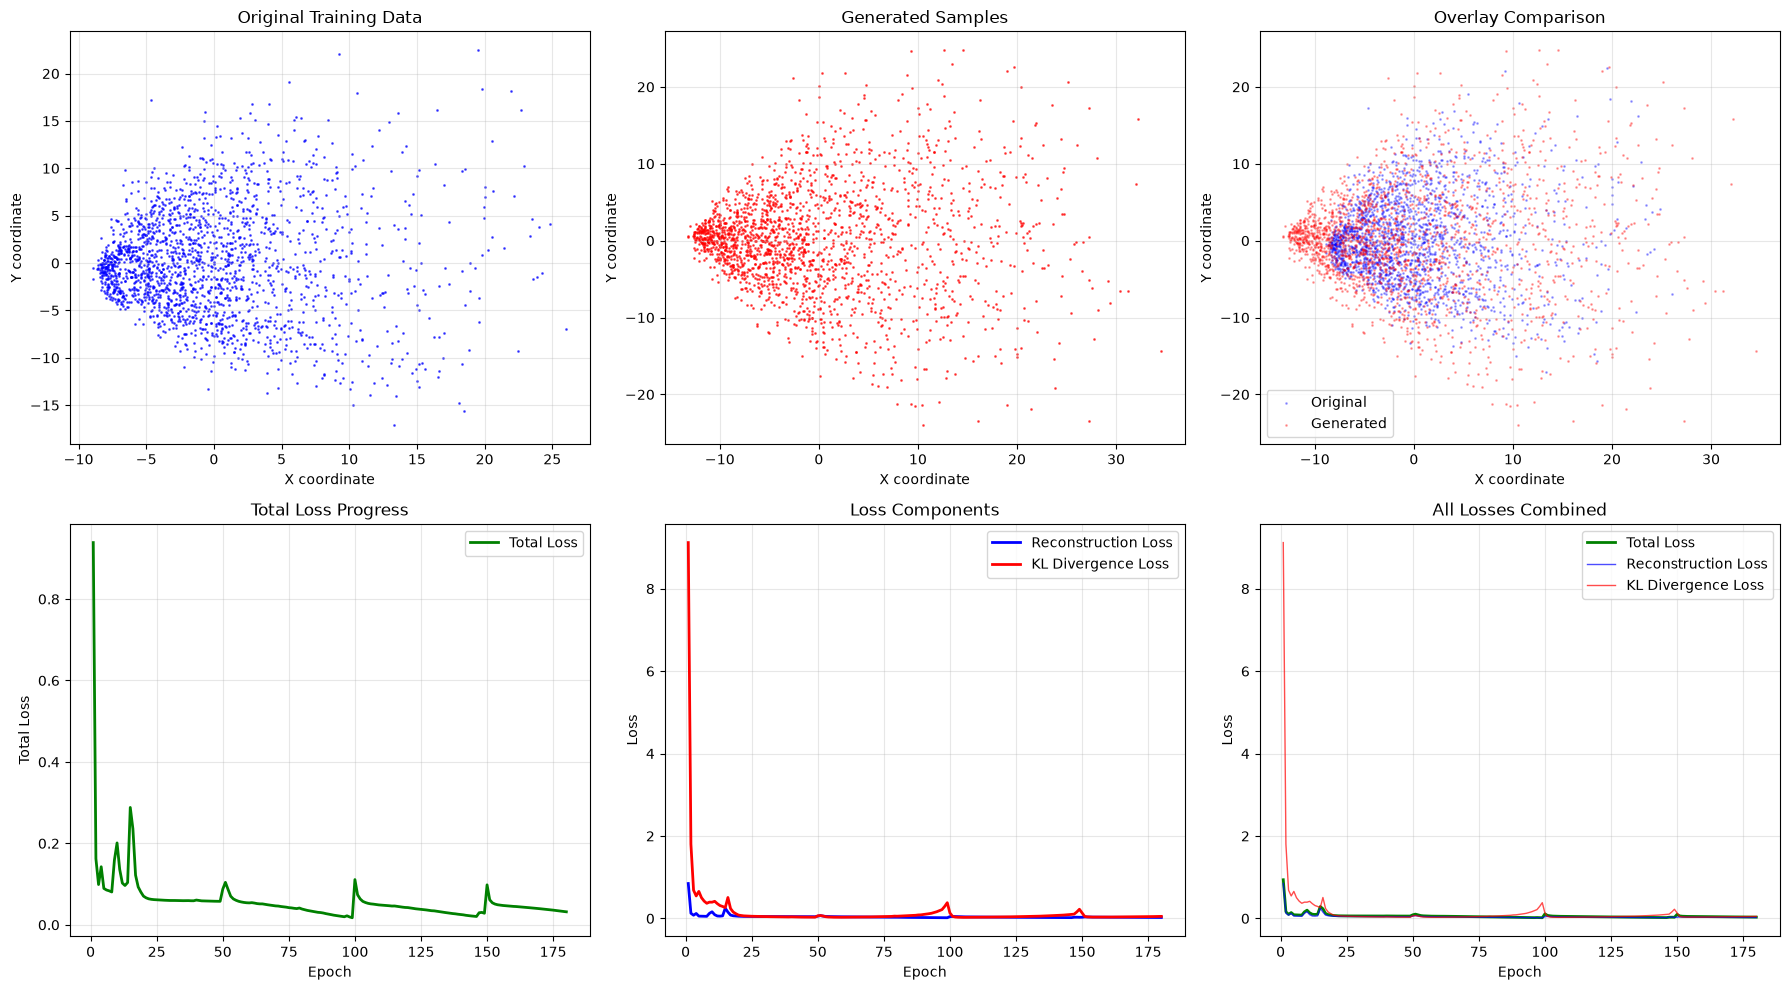

📈 Epoch 180 Summary:
   Total Loss: 0.0319
   Reconstruction Loss: 0.0233
   KL Divergence Loss: 0.0501
   Beta: 0.173
   Learning Rate: 0.000063

📊 Epoch 181/300
----------------------------------------
Epoch: 181 [0/60000 (0%)]	Total Loss: 0.030968	Recon Loss: 0.022908	KL Loss: 0.051025	Beta: 0.158
====> Epoch: 181 Average Total Loss: 0.0311, Average Recon Loss: 0.0230, Average KL Loss: 0.0515, Beta: 0.158
📈 Epoch 181 Summary:
   Total Loss: 0.0311
   Reconstruction Loss: 0.0230
   KL Divergence Loss: 0.0515
   Beta: 0.158
   Learning Rate: 0.000063

📊 Epoch 182/300
----------------------------------------
Epoch: 182 [0/60000 (0%)]	Total Loss: 0.030445	Recon Loss: 0.022863	KL Loss: 0.052814	Beta: 0.144
====> Epoch: 182 Average Total Loss: 0.0303, Average Recon Loss: 0.0226, Average KL Loss: 0.0534, Beta: 0.144
📈 Epoch 182 Summary:
   Total Loss: 0.0303
   Reconstruction Loss: 0.0226
   KL Divergence Loss: 0.0534
   Beta: 0.144
   Learning Rate: 0.000063

📊 Epoch 183/300
-------------

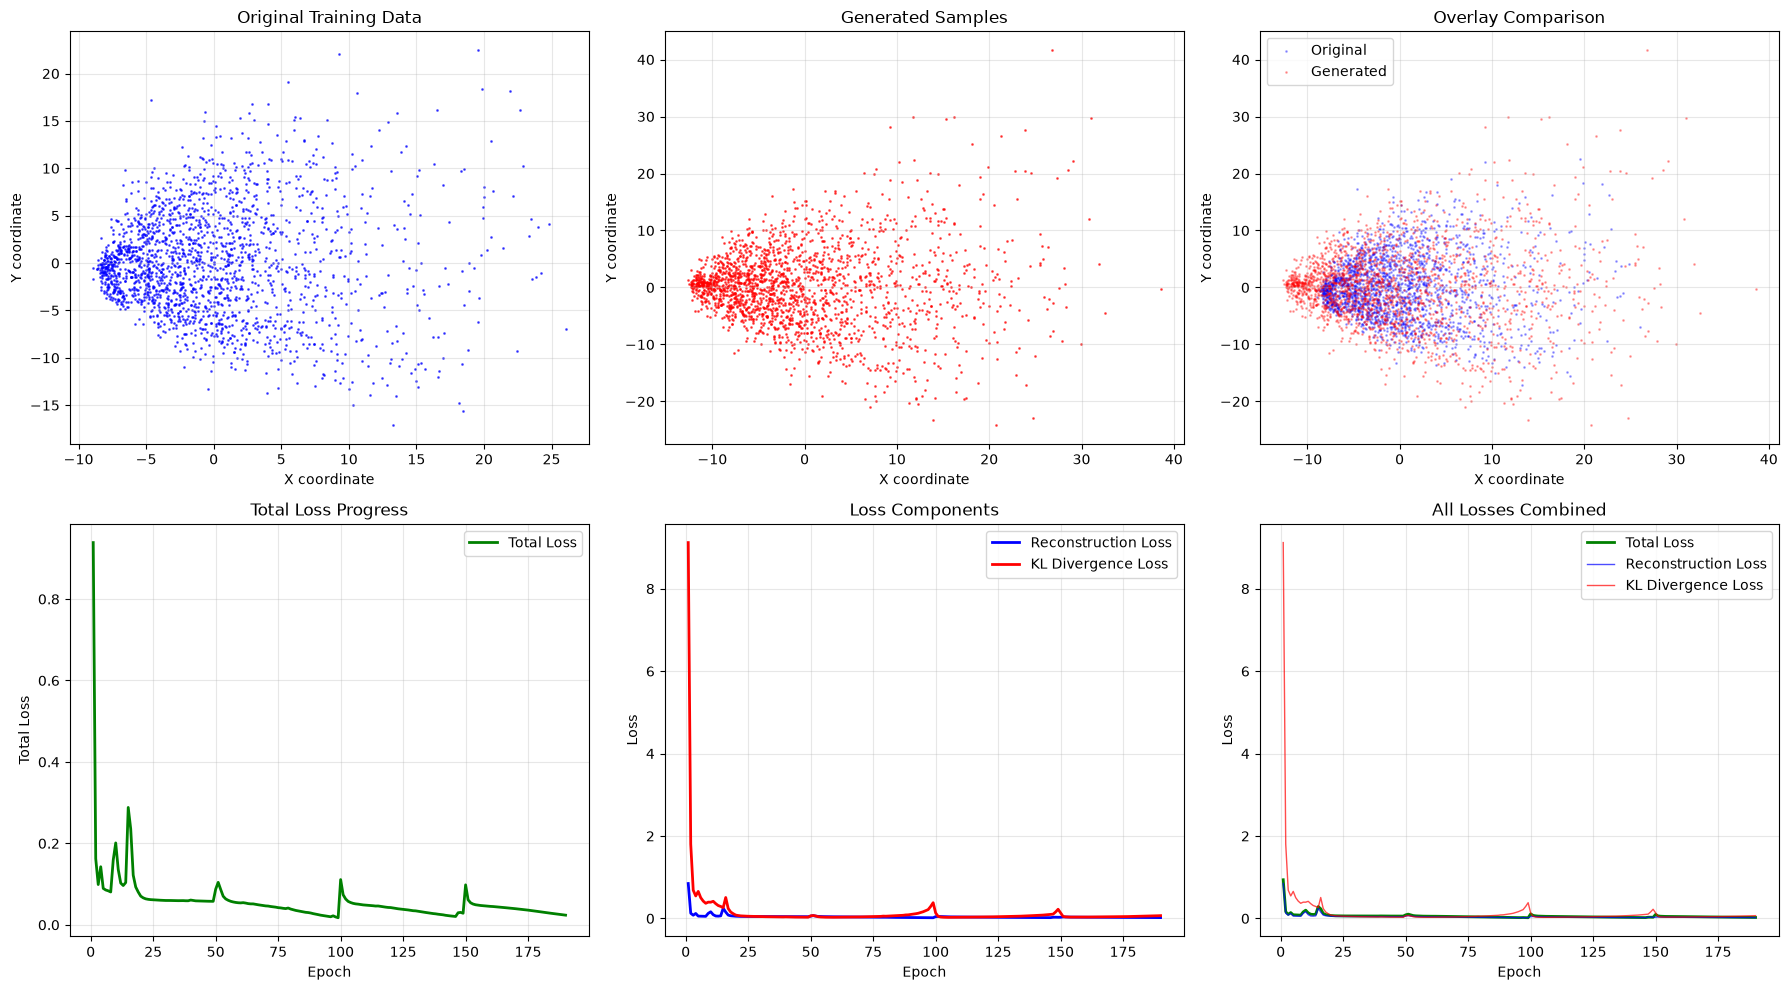

📈 Epoch 190 Summary:
   Total Loss: 0.0237
   Reconstruction Loss: 0.0205
   KL Divergence Loss: 0.0678
   Beta: 0.048
   Learning Rate: 0.000031

📊 Epoch 191/300
----------------------------------------
Epoch: 191 [0/60000 (0%)]	Total Loss: 0.023442	Recon Loss: 0.020728	KL Loss: 0.069737	Beta: 0.039
====> Epoch: 191 Average Total Loss: 0.0231, Average Recon Loss: 0.0203, Average KL Loss: 0.0705, Beta: 0.039
📈 Epoch 191 Summary:
   Total Loss: 0.0231
   Reconstruction Loss: 0.0203
   KL Divergence Loss: 0.0705
   Beta: 0.039
   Learning Rate: 0.000031

📊 Epoch 192/300
----------------------------------------
Epoch: 192 [0/60000 (0%)]	Total Loss: 0.022174	Recon Loss: 0.019942	KL Loss: 0.072206	Beta: 0.031
====> Epoch: 192 Average Total Loss: 0.0223, Average Recon Loss: 0.0200, Average KL Loss: 0.0733, Beta: 0.031
📈 Epoch 192 Summary:
   Total Loss: 0.0223
   Reconstruction Loss: 0.0200
   KL Divergence Loss: 0.0733
   Beta: 0.031
   Learning Rate: 0.000031

📊 Epoch 193/300
-------------

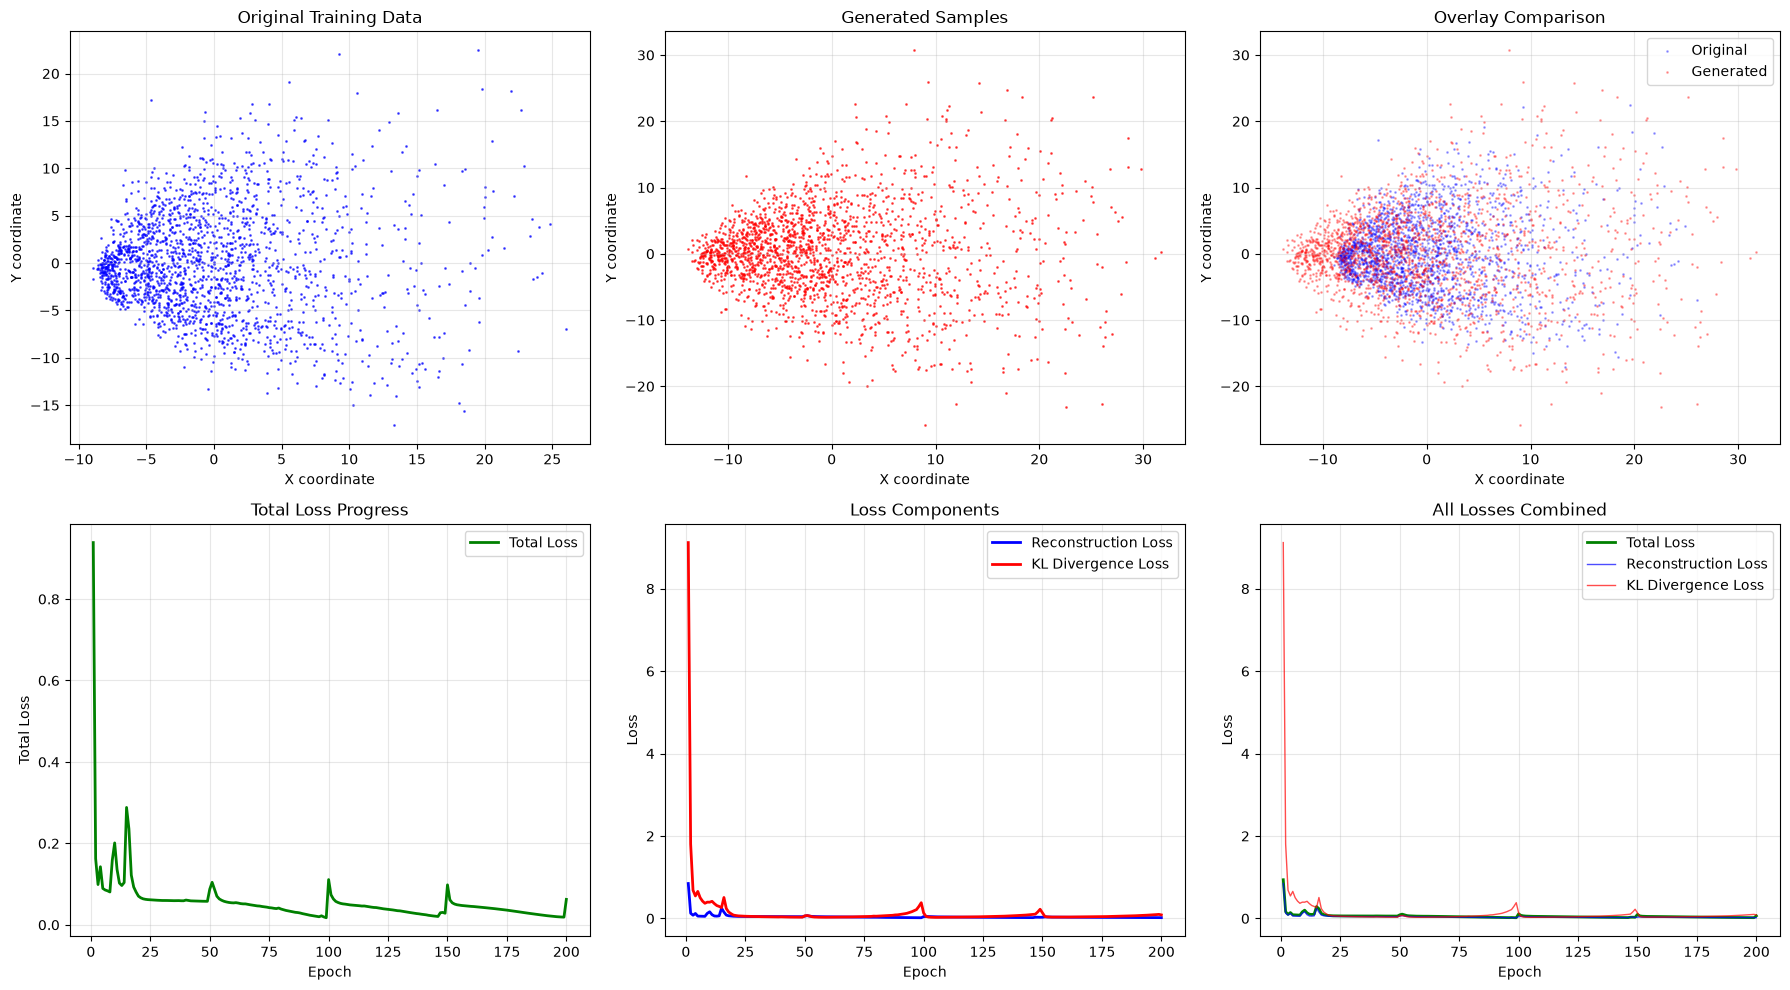

📈 Epoch 200 Summary:
   Total Loss: 0.0625
   Reconstruction Loss: 0.0195
   KL Divergence Loss: 0.0860
   Beta: 0.500
   Learning Rate: 0.000031

📊 Epoch 201/300
----------------------------------------
Epoch: 201 [0/60000 (0%)]	Total Loss: 0.052943	Recon Loss: 0.021361	KL Loss: 0.063227	Beta: 0.500
====> Epoch: 201 Average Total Loss: 0.0508, Average Recon Loss: 0.0242, Average KL Loss: 0.0532, Beta: 0.500
📈 Epoch 201 Summary:
   Total Loss: 0.0508
   Reconstruction Loss: 0.0242
   KL Divergence Loss: 0.0532
   Beta: 0.500
   Learning Rate: 0.000031

📊 Epoch 202/300
----------------------------------------
Epoch: 202 [0/60000 (0%)]	Total Loss: 0.048980	Recon Loss: 0.026967	KL Loss: 0.044200	Beta: 0.498
====> Epoch: 202 Average Total Loss: 0.0484, Average Recon Loss: 0.0275, Average KL Loss: 0.0420, Beta: 0.498
📈 Epoch 202 Summary:
   Total Loss: 0.0484
   Reconstruction Loss: 0.0275
   KL Divergence Loss: 0.0420
   Beta: 0.498
   Learning Rate: 0.000031

📊 Epoch 203/300
-------------

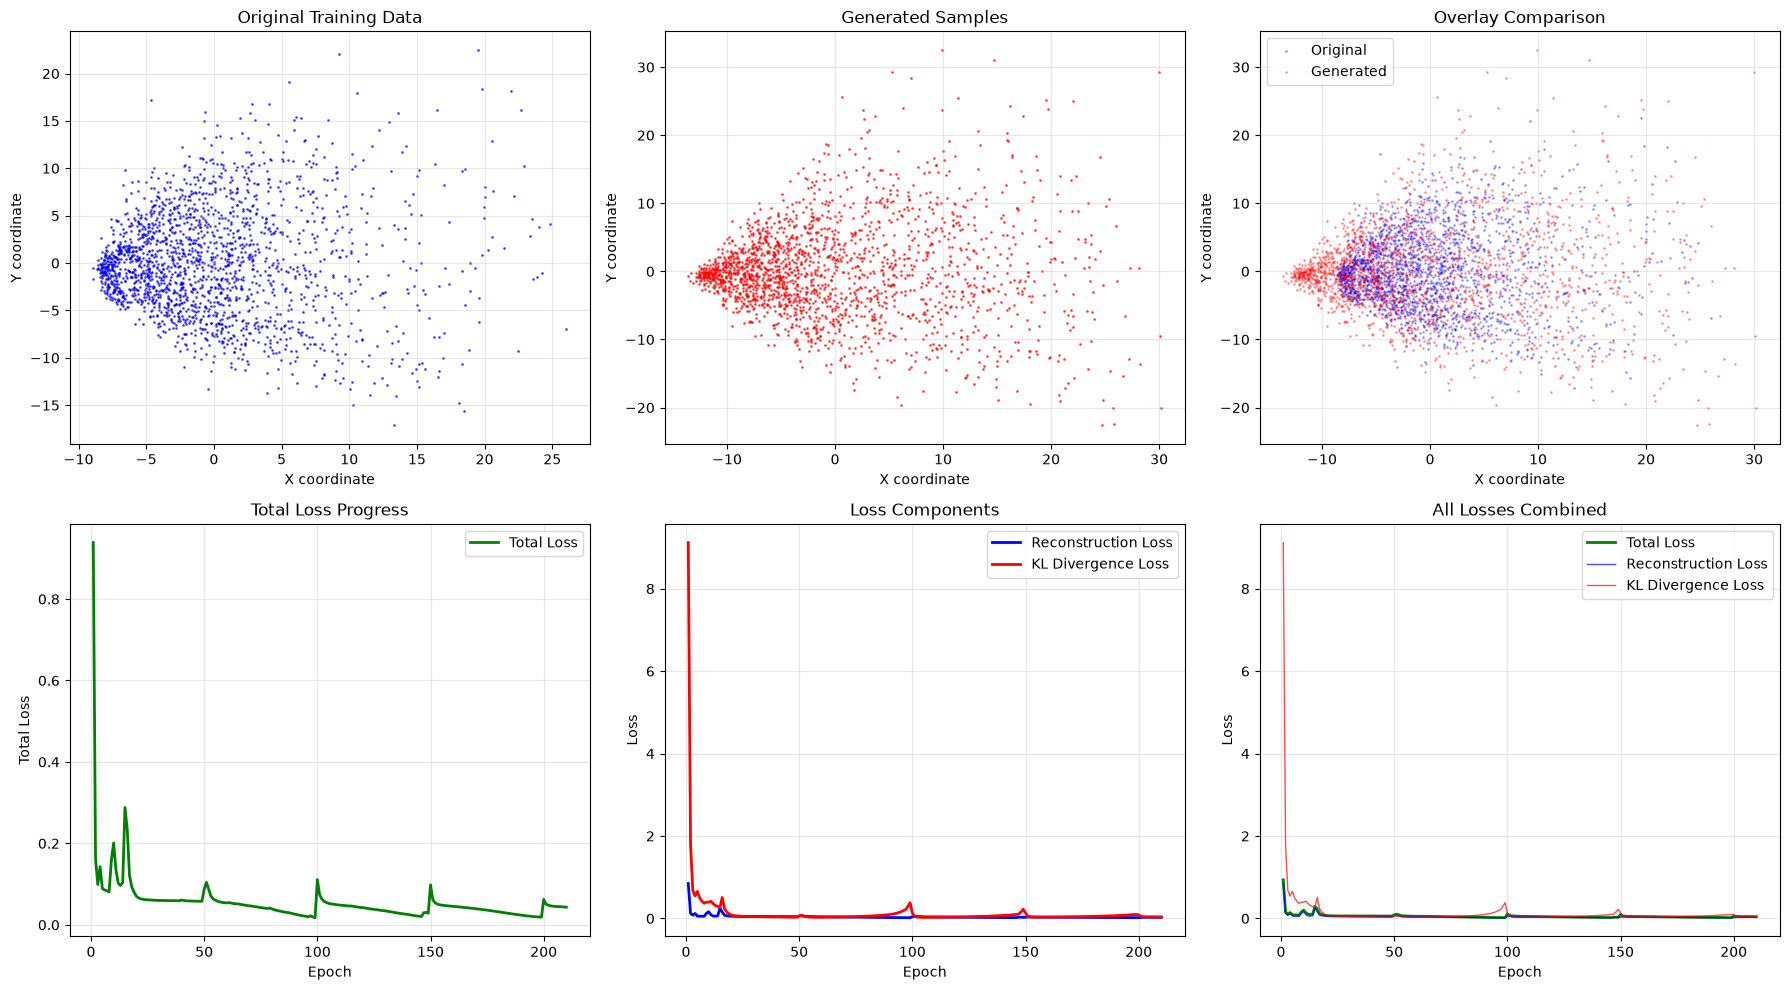

📈 Epoch 210 Summary:
   Total Loss: 0.0434
   Reconstruction Loss: 0.0267
   KL Divergence Loss: 0.0370
   Beta: 0.452
   Learning Rate: 0.000016

📊 Epoch 211/300
----------------------------------------
Epoch: 211 [0/60000 (0%)]	Total Loss: 0.042913	Recon Loss: 0.026655	KL Loss: 0.036730	Beta: 0.443
====> Epoch: 211 Average Total Loss: 0.0430, Average Recon Loss: 0.0267, Average KL Loss: 0.0369, Beta: 0.443
📈 Epoch 211 Summary:
   Total Loss: 0.0430
   Reconstruction Loss: 0.0267
   KL Divergence Loss: 0.0369
   Beta: 0.443
   Learning Rate: 0.000016

📊 Epoch 212/300
----------------------------------------
Epoch: 212 [0/60000 (0%)]	Total Loss: 0.042564	Recon Loss: 0.026645	KL Loss: 0.036829	Beta: 0.432
====> Epoch: 212 Average Total Loss: 0.0426, Average Recon Loss: 0.0265, Average KL Loss: 0.0373, Beta: 0.432
📈 Epoch 212 Summary:
   Total Loss: 0.0426
   Reconstruction Loss: 0.0265
   KL Divergence Loss: 0.0373
   Beta: 0.432
   Learning Rate: 0.000016

📊 Epoch 213/300
-------------

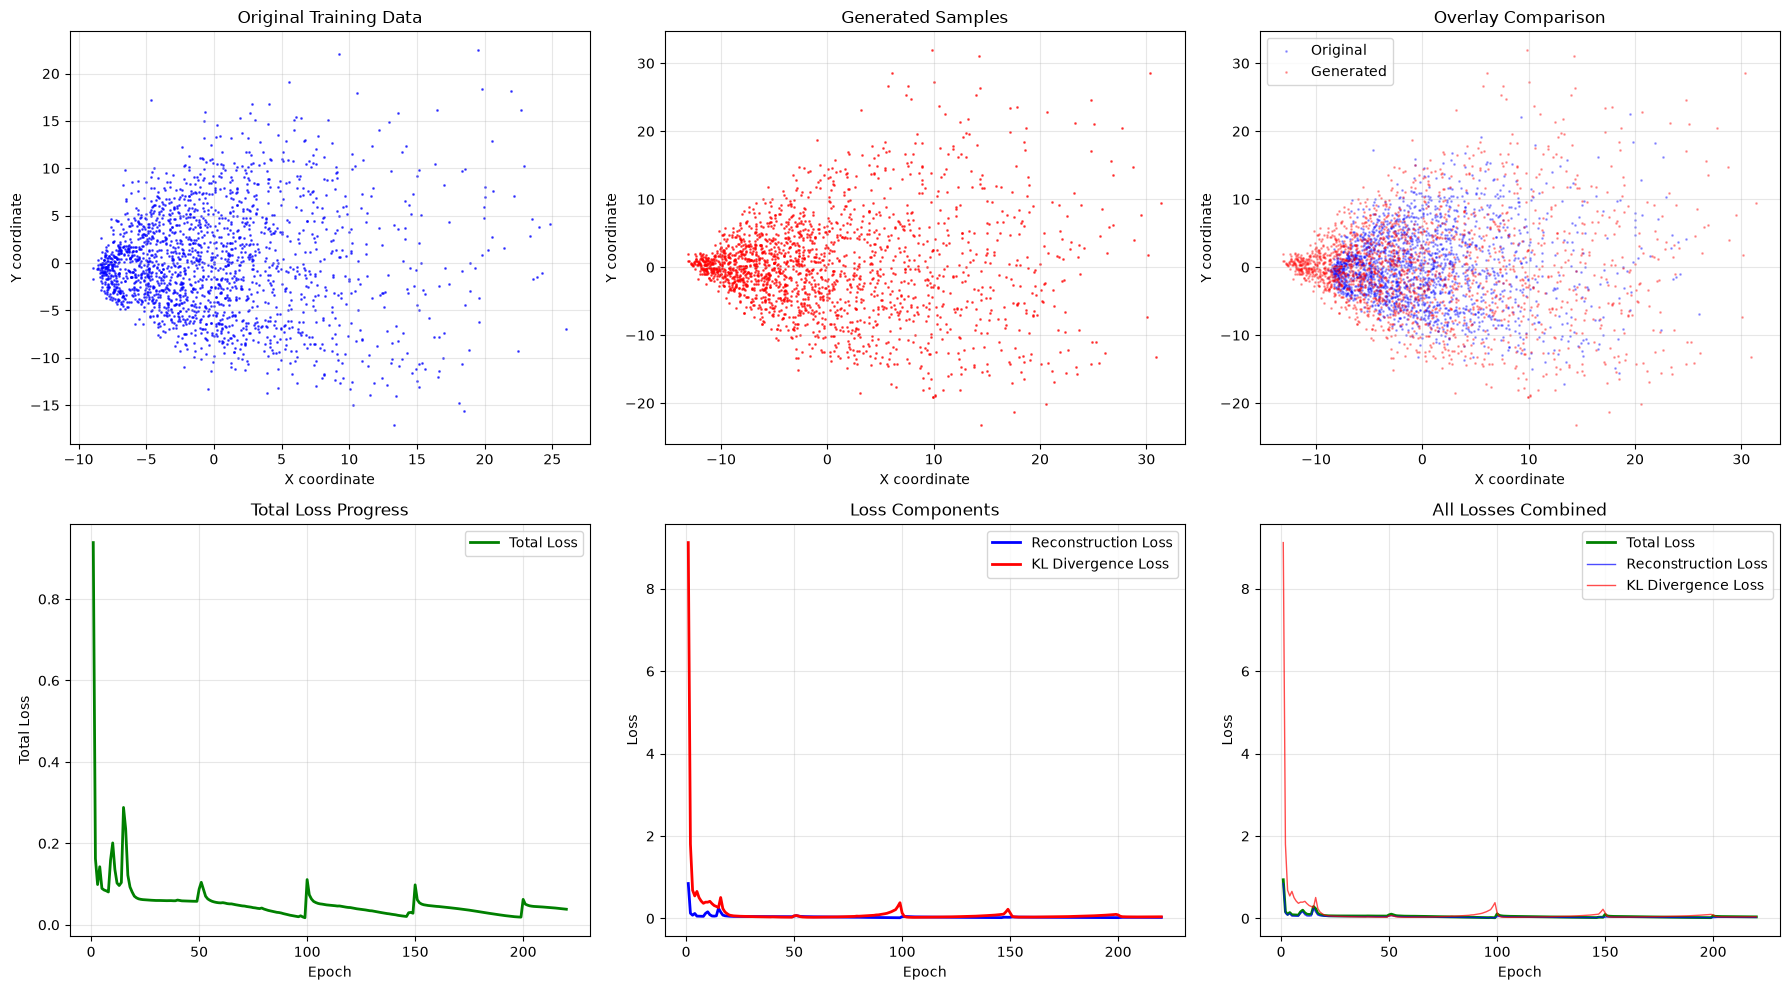

📈 Epoch 220 Summary:
   Total Loss: 0.0383
   Reconstruction Loss: 0.0251
   KL Divergence Loss: 0.0405
   Beta: 0.327
   Learning Rate: 0.000016

📊 Epoch 221/300
----------------------------------------
Epoch: 221 [0/60000 (0%)]	Total Loss: 0.037530	Recon Loss: 0.024589	KL Loss: 0.041454	Beta: 0.312
====> Epoch: 221 Average Total Loss: 0.0376, Average Recon Loss: 0.0248, Average KL Loss: 0.0412, Beta: 0.312
📈 Epoch 221 Summary:
   Total Loss: 0.0376
   Reconstruction Loss: 0.0248
   KL Divergence Loss: 0.0412
   Beta: 0.312
   Learning Rate: 0.000016

📊 Epoch 222/300
----------------------------------------
Epoch: 222 [0/60000 (0%)]	Total Loss: 0.036837	Recon Loss: 0.024265	KL Loss: 0.042351	Beta: 0.297
====> Epoch: 222 Average Total Loss: 0.0370, Average Recon Loss: 0.0246, Average KL Loss: 0.0417, Beta: 0.297
📈 Epoch 222 Summary:
   Total Loss: 0.0370
   Reconstruction Loss: 0.0246
   KL Divergence Loss: 0.0417
   Beta: 0.297
   Learning Rate: 0.000016

📊 Epoch 223/300
-------------

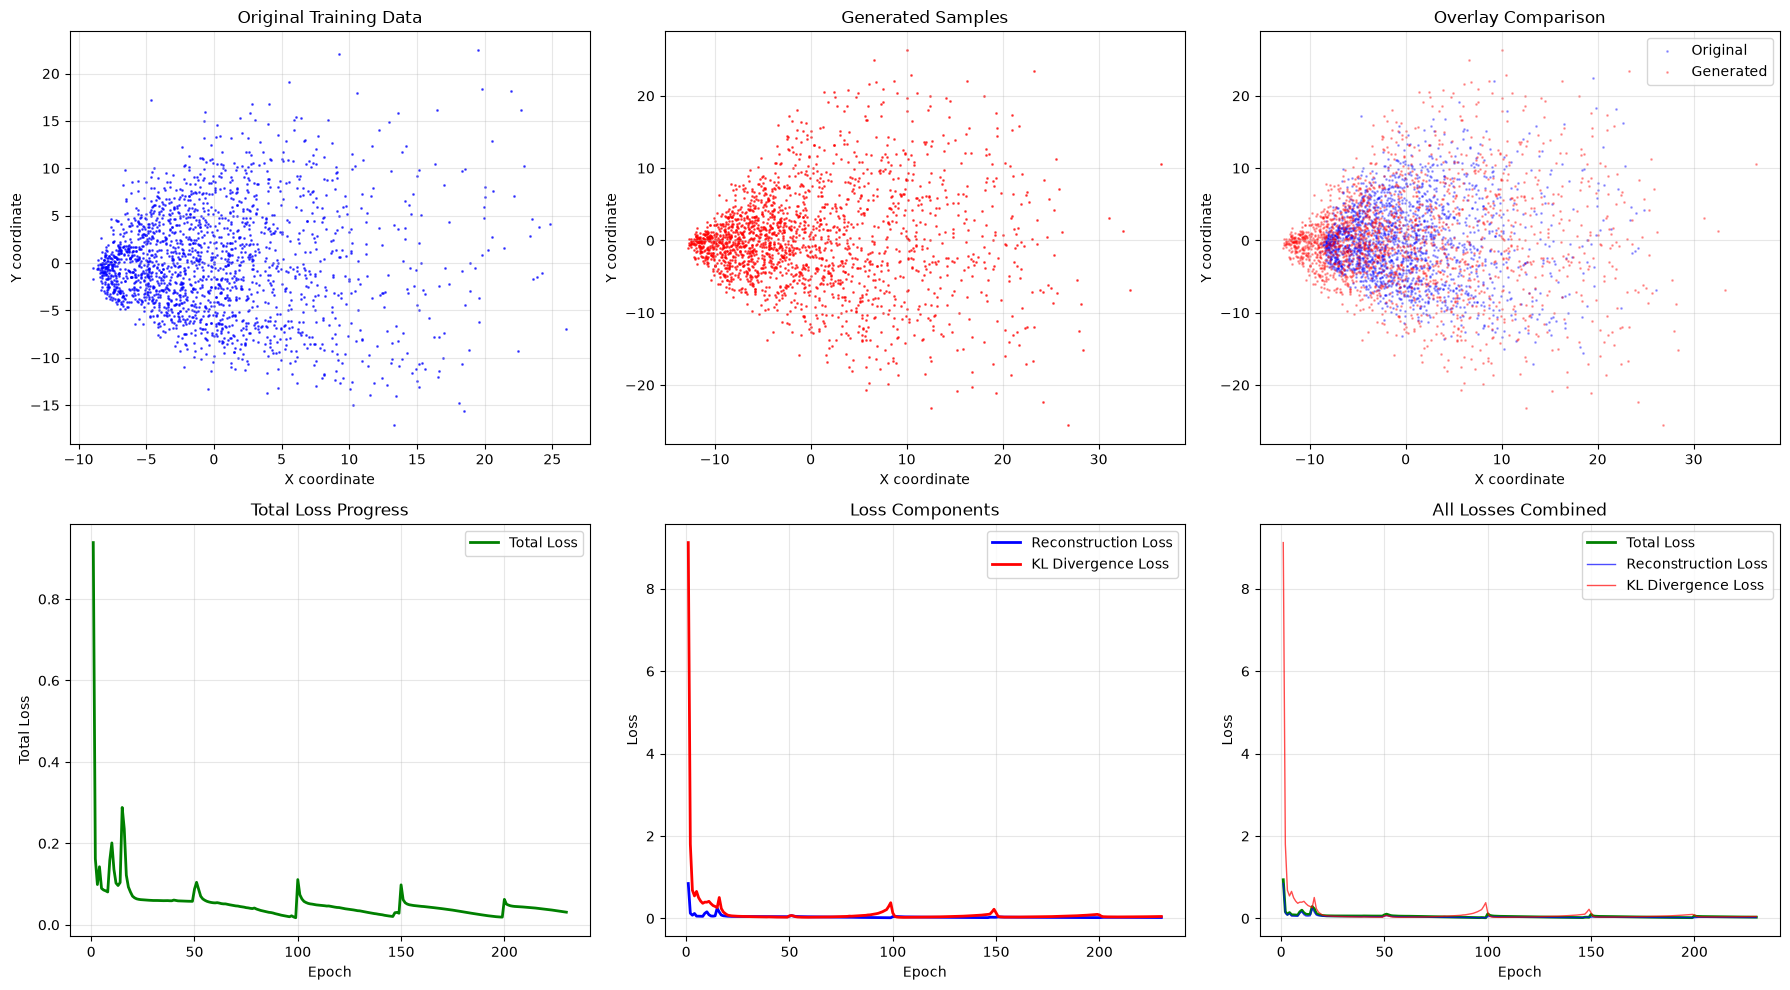

📈 Epoch 230 Summary:
   Total Loss: 0.0311
   Reconstruction Loss: 0.0228
   KL Divergence Loss: 0.0476
   Beta: 0.173
   Learning Rate: 0.000008

📊 Epoch 231/300
----------------------------------------
Epoch: 231 [0/60000 (0%)]	Total Loss: 0.030378	Recon Loss: 0.022670	KL Loss: 0.048794	Beta: 0.158
====> Epoch: 231 Average Total Loss: 0.0303, Average Recon Loss: 0.0226, Average KL Loss: 0.0488, Beta: 0.158
📈 Epoch 231 Summary:
   Total Loss: 0.0303
   Reconstruction Loss: 0.0226
   KL Divergence Loss: 0.0488
   Beta: 0.158
   Learning Rate: 0.000008

📊 Epoch 232/300
----------------------------------------
Epoch: 232 [0/60000 (0%)]	Total Loss: 0.029374	Recon Loss: 0.022187	KL Loss: 0.050059	Beta: 0.144
====> Epoch: 232 Average Total Loss: 0.0295, Average Recon Loss: 0.0224, Average KL Loss: 0.0497, Beta: 0.144
📈 Epoch 232 Summary:
   Total Loss: 0.0295
   Reconstruction Loss: 0.0224
   KL Divergence Loss: 0.0497
   Beta: 0.144
   Learning Rate: 0.000008

📊 Epoch 233/300
-------------

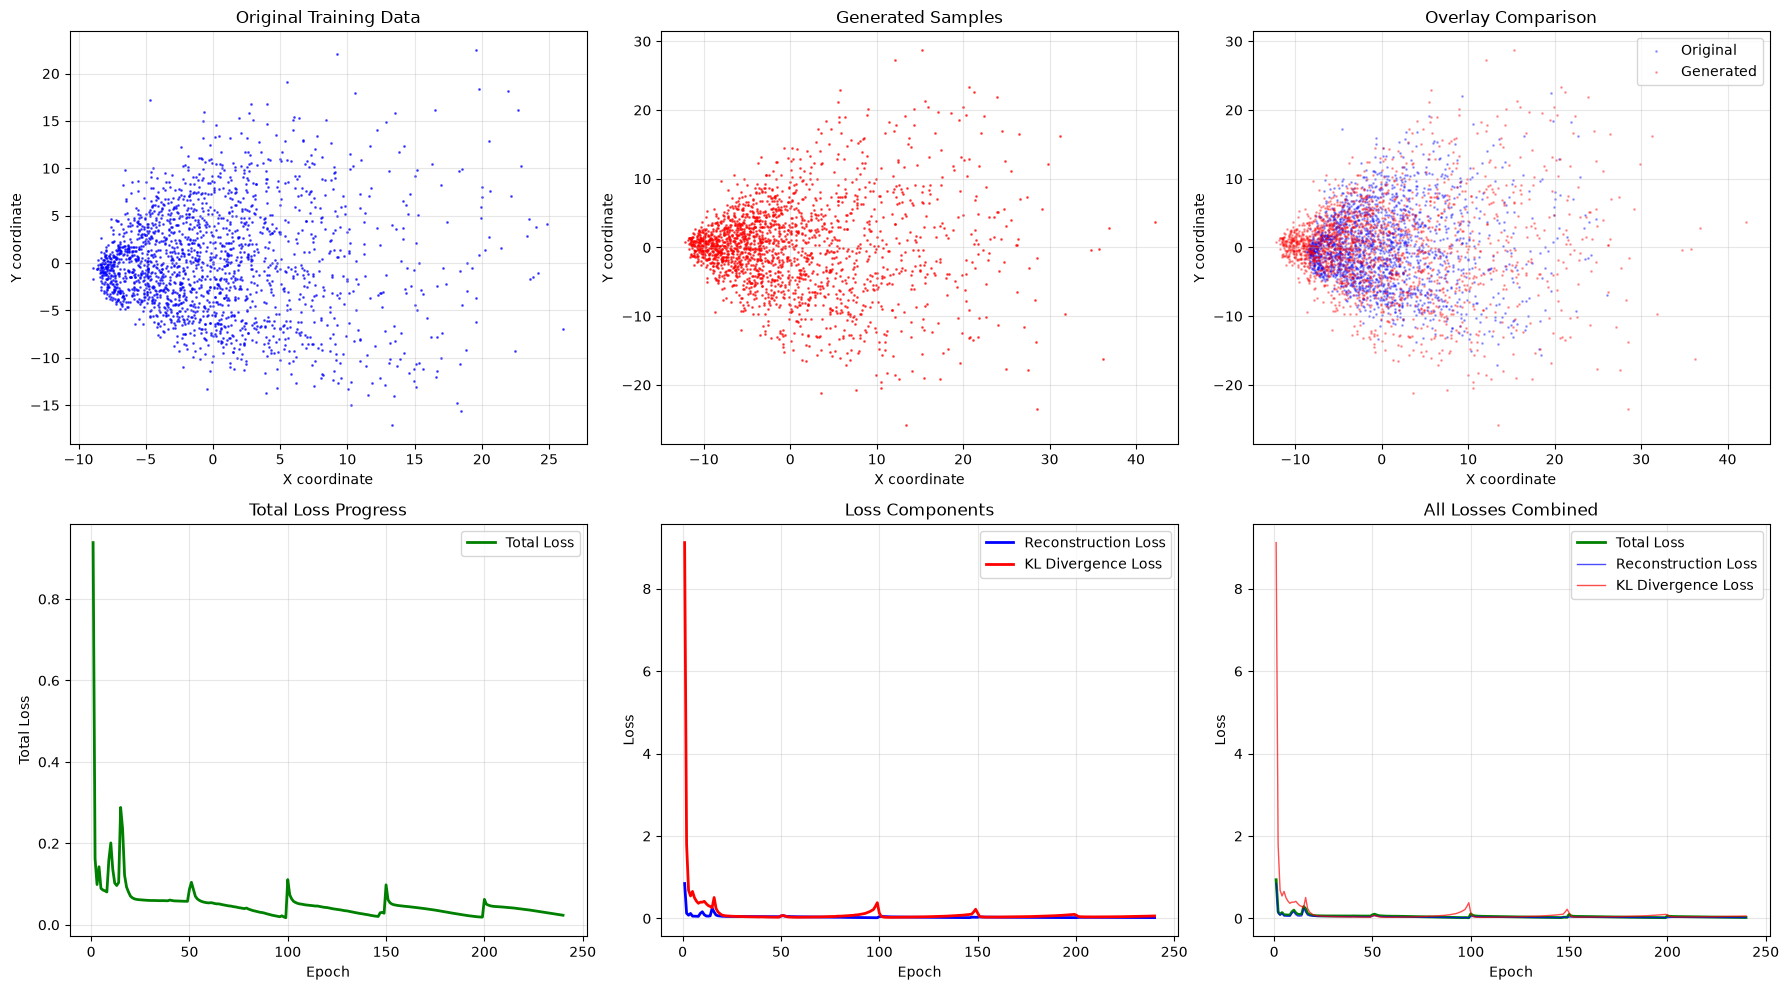

📈 Epoch 240 Summary:
   Total Loss: 0.0235
   Reconstruction Loss: 0.0206
   KL Divergence Loss: 0.0604
   Beta: 0.048
   Learning Rate: 0.000008

📊 Epoch 241/300
----------------------------------------
Epoch: 241 [0/60000 (0%)]	Total Loss: 0.022847	Recon Loss: 0.020462	KL Loss: 0.061285	Beta: 0.039
====> Epoch: 241 Average Total Loss: 0.0229, Average Recon Loss: 0.0205, Average KL Loss: 0.0623, Beta: 0.039
📈 Epoch 241 Summary:
   Total Loss: 0.0229
   Reconstruction Loss: 0.0205
   KL Divergence Loss: 0.0623
   Beta: 0.039
   Learning Rate: 0.000008

📊 Epoch 242/300
----------------------------------------
Epoch: 242 [0/60000 (0%)]	Total Loss: 0.022208	Recon Loss: 0.020281	KL Loss: 0.062309	Beta: 0.031
====> Epoch: 242 Average Total Loss: 0.0223, Average Recon Loss: 0.0203, Average KL Loss: 0.0638, Beta: 0.031
📈 Epoch 242 Summary:
   Total Loss: 0.0223
   Reconstruction Loss: 0.0203
   KL Divergence Loss: 0.0638
   Beta: 0.031
   Learning Rate: 0.000008

📊 Epoch 243/300
-------------

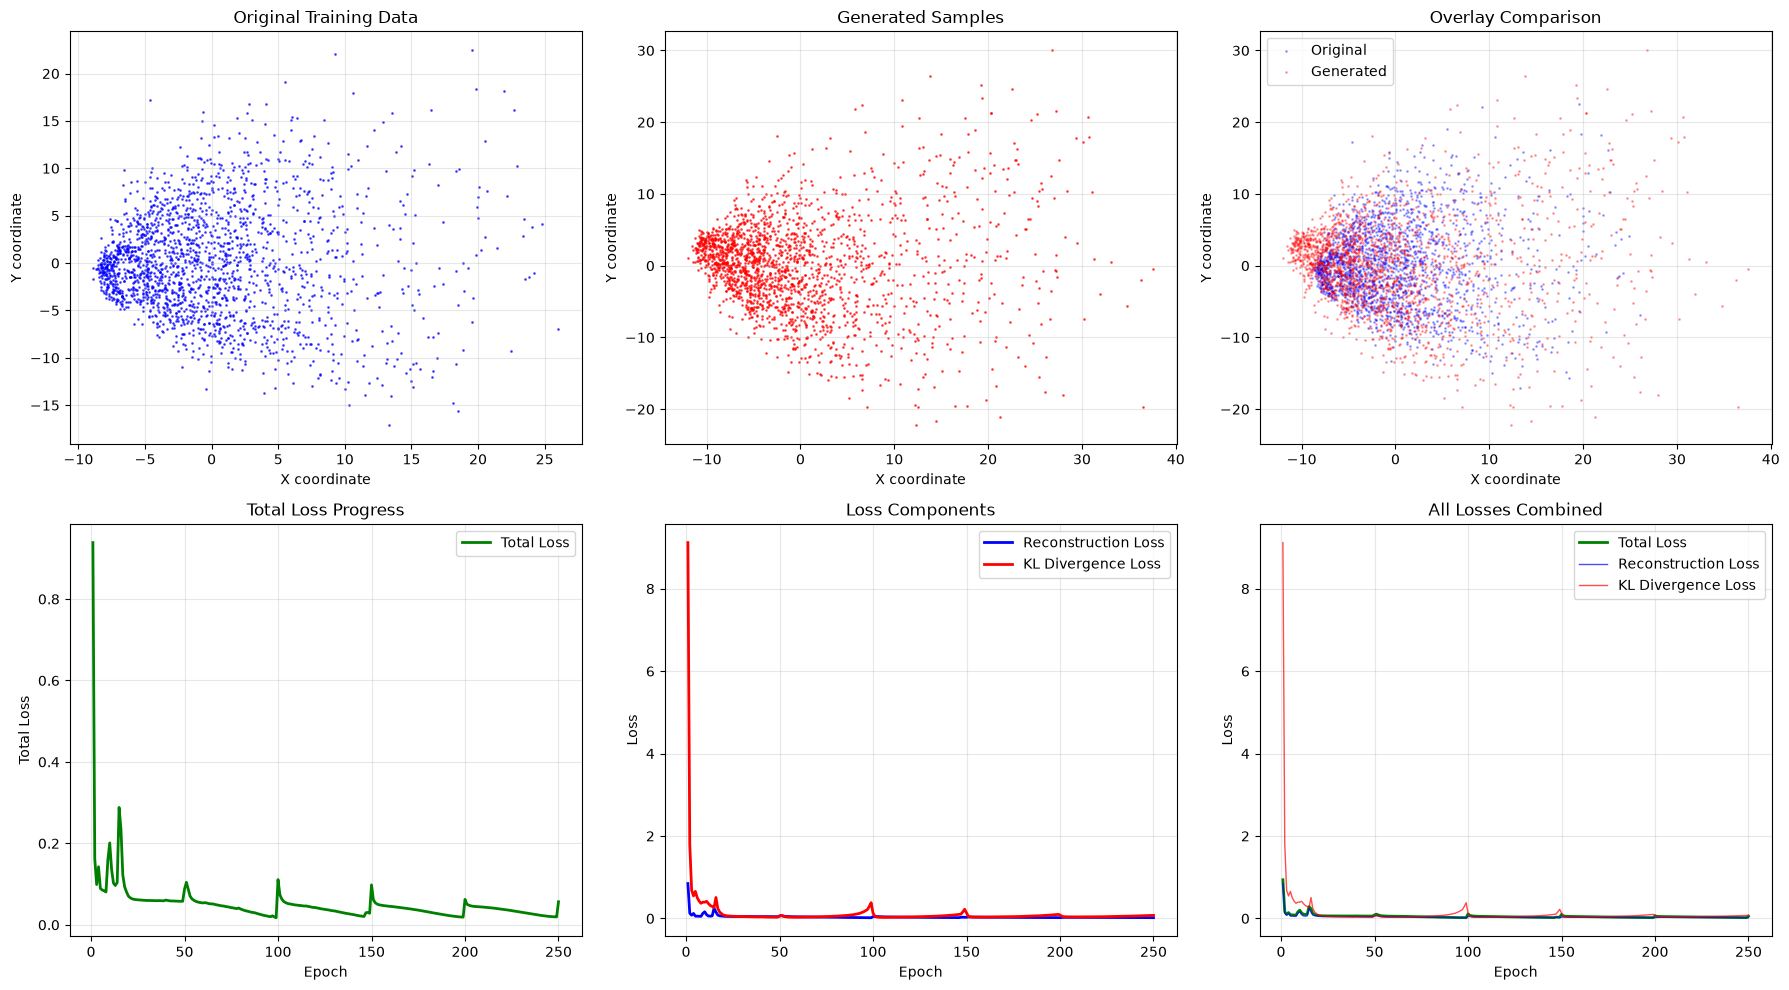

📈 Epoch 250 Summary:
   Total Loss: 0.0566
   Reconstruction Loss: 0.0194
   KL Divergence Loss: 0.0745
   Beta: 0.500
   Learning Rate: 0.000004

📊 Epoch 251/300
----------------------------------------
Epoch: 251 [0/60000 (0%)]	Total Loss: 0.054970	Recon Loss: 0.019640	KL Loss: 0.070728	Beta: 0.500
====> Epoch: 251 Average Total Loss: 0.0540, Average Recon Loss: 0.0198, Average KL Loss: 0.0685, Beta: 0.500
📈 Epoch 251 Summary:
   Total Loss: 0.0540
   Reconstruction Loss: 0.0198
   KL Divergence Loss: 0.0685
   Beta: 0.500
   Learning Rate: 0.000004

📊 Epoch 252/300
----------------------------------------
Epoch: 252 [0/60000 (0%)]	Total Loss: 0.052155	Recon Loss: 0.020057	KL Loss: 0.064449	Beta: 0.498
====> Epoch: 252 Average Total Loss: 0.0509, Average Recon Loss: 0.0204, Average KL Loss: 0.0613, Beta: 0.498
📈 Epoch 252 Summary:
   Total Loss: 0.0509
   Reconstruction Loss: 0.0204
   KL Divergence Loss: 0.0613
   Beta: 0.498
   Learning Rate: 0.000004

📊 Epoch 253/300
-------------

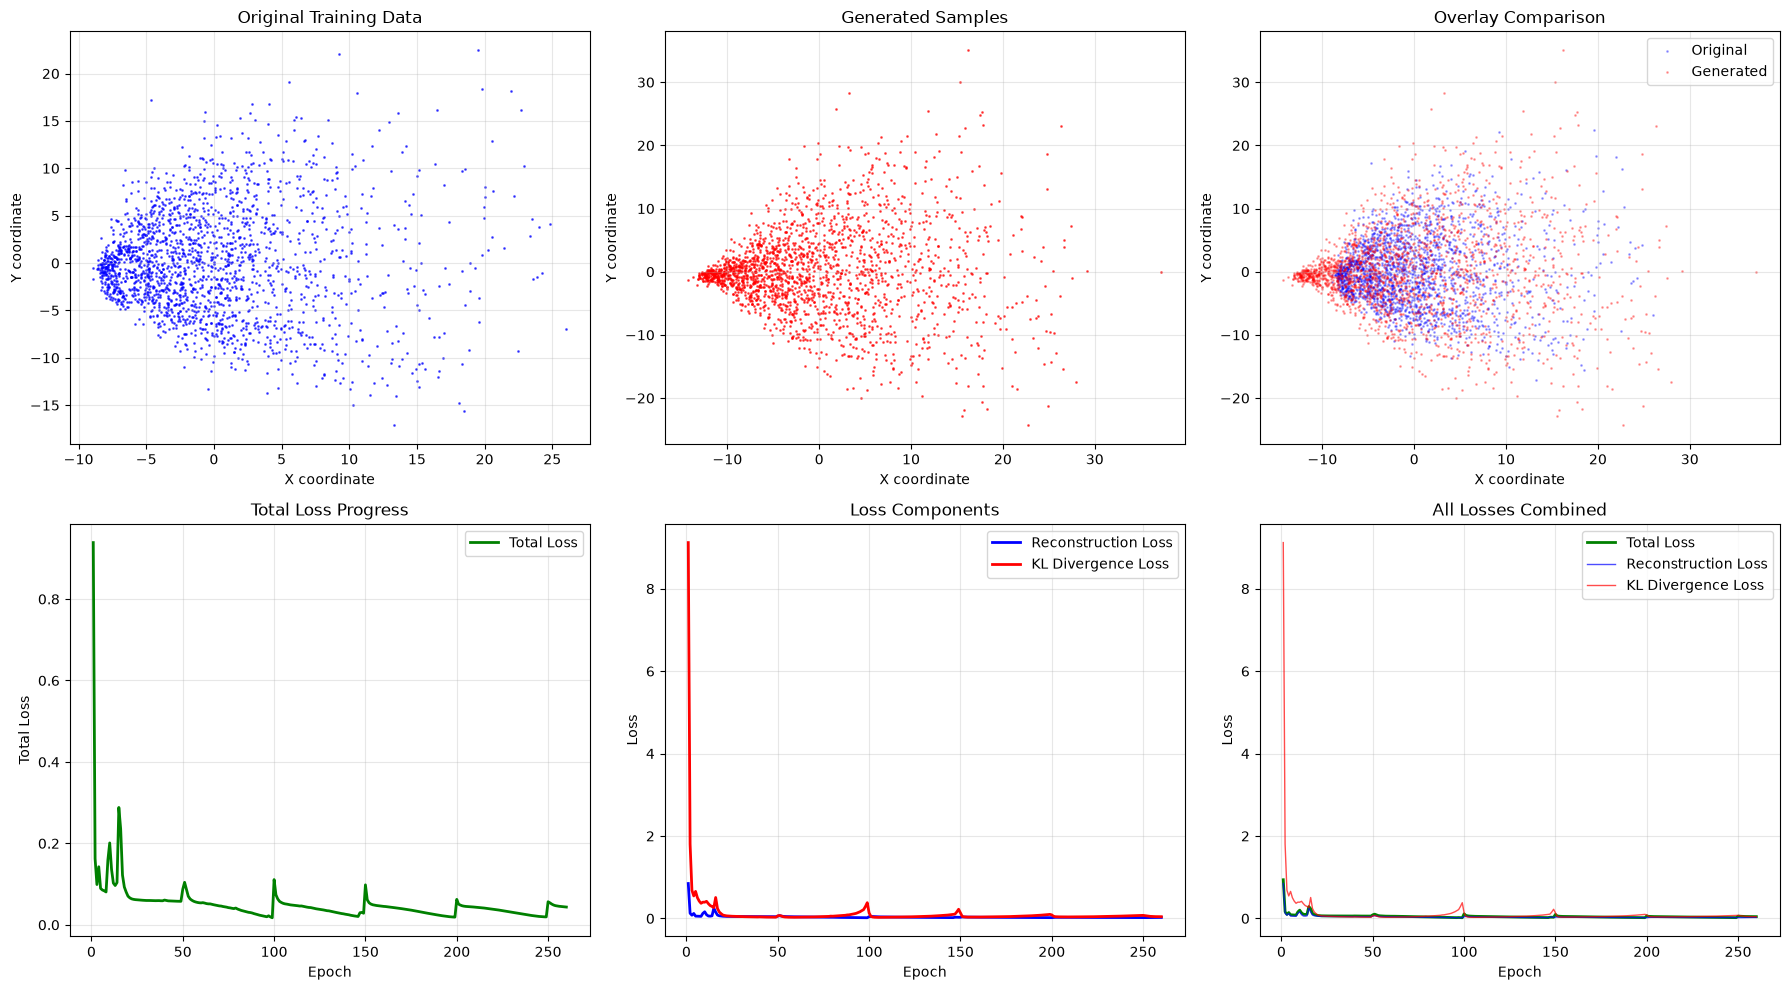

📈 Epoch 260 Summary:
   Total Loss: 0.0436
   Reconstruction Loss: 0.0244
   KL Divergence Loss: 0.0425
   Beta: 0.452
   Learning Rate: 0.000004

📊 Epoch 261/300
----------------------------------------
Epoch: 261 [0/60000 (0%)]	Total Loss: 0.043178	Recon Loss: 0.024536	KL Loss: 0.042116	Beta: 0.443
====> Epoch: 261 Average Total Loss: 0.0431, Average Recon Loss: 0.0244, Average KL Loss: 0.0423, Beta: 0.443
📈 Epoch 261 Summary:
   Total Loss: 0.0431
   Reconstruction Loss: 0.0244
   KL Divergence Loss: 0.0423
   Beta: 0.443
   Learning Rate: 0.000004

📊 Epoch 262/300
----------------------------------------
Epoch: 262 [0/60000 (0%)]	Total Loss: 0.042593	Recon Loss: 0.024556	KL Loss: 0.041729	Beta: 0.432
====> Epoch: 262 Average Total Loss: 0.0426, Average Recon Loss: 0.0244, Average KL Loss: 0.0421, Beta: 0.432
📈 Epoch 262 Summary:
   Total Loss: 0.0426
   Reconstruction Loss: 0.0244
   KL Divergence Loss: 0.0421
   Beta: 0.432
   Learning Rate: 0.000004

📊 Epoch 263/300
-------------

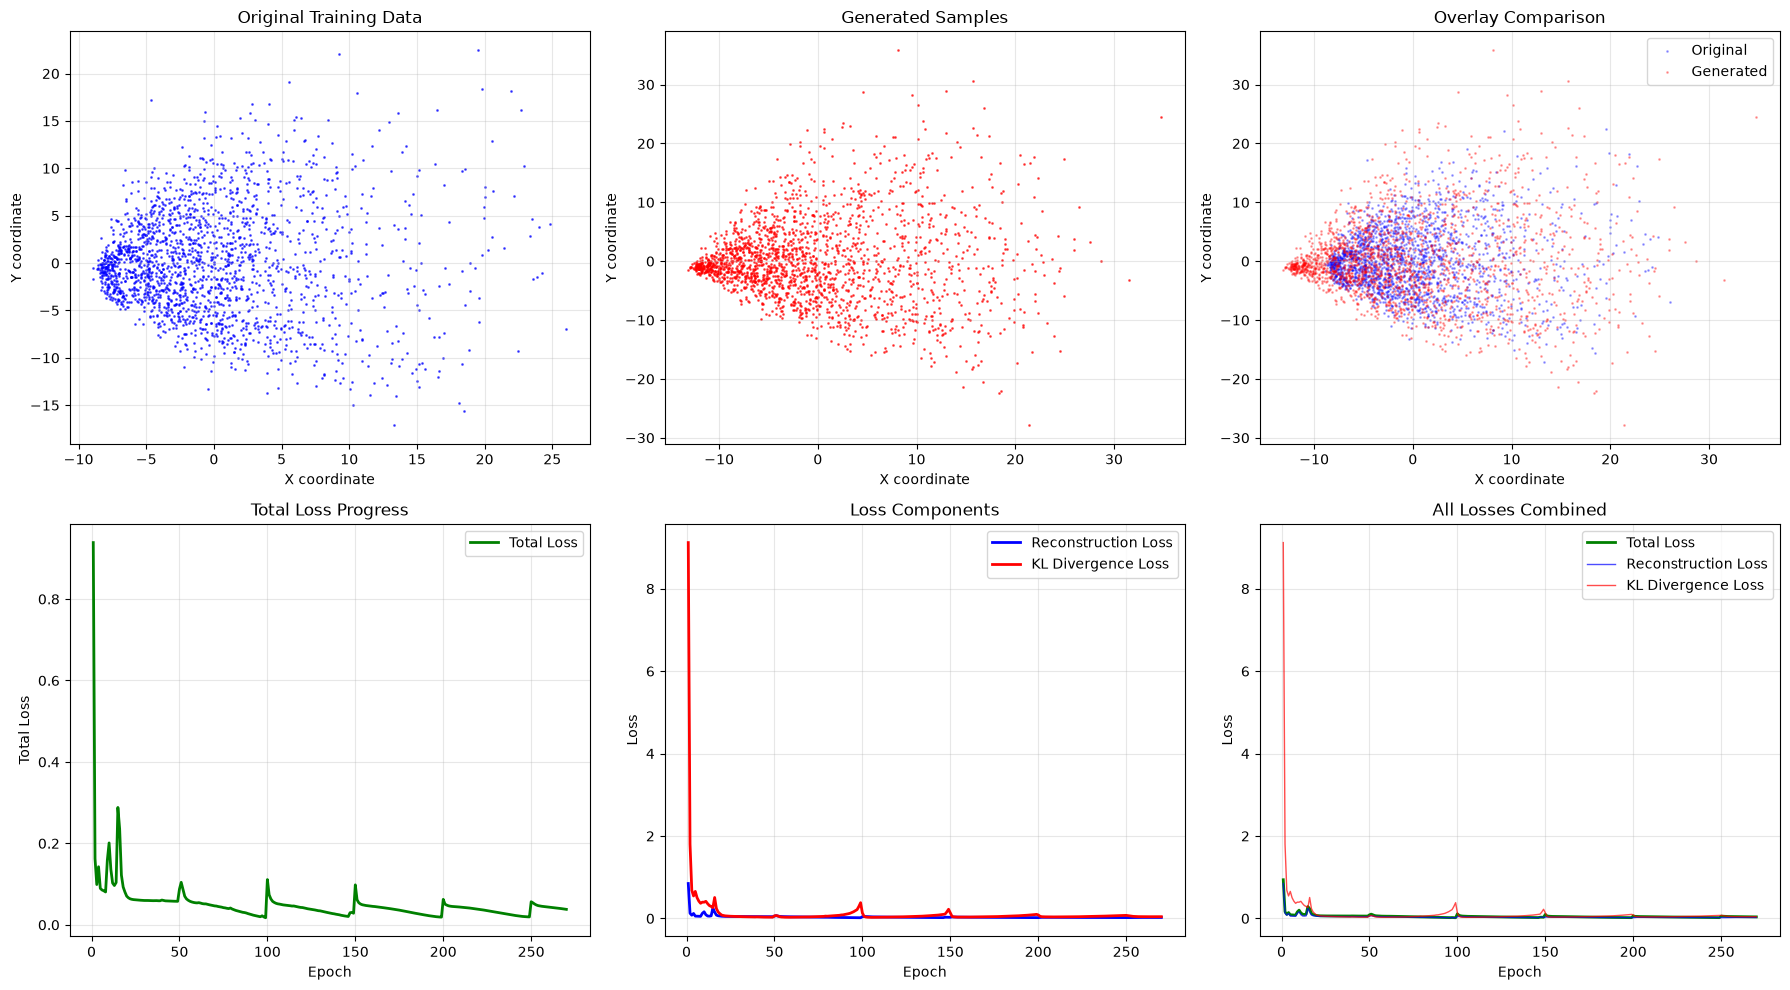

📈 Epoch 270 Summary:
   Total Loss: 0.0380
   Reconstruction Loss: 0.0240
   KL Divergence Loss: 0.0426
   Beta: 0.327
   Learning Rate: 0.000002

📊 Epoch 271/300
----------------------------------------
Epoch: 271 [0/60000 (0%)]	Total Loss: 0.037203	Recon Loss: 0.023788	KL Loss: 0.042972	Beta: 0.312
====> Epoch: 271 Average Total Loss: 0.0373, Average Recon Loss: 0.0240, Average KL Loss: 0.0427, Beta: 0.312
📈 Epoch 271 Summary:
   Total Loss: 0.0373
   Reconstruction Loss: 0.0240
   KL Divergence Loss: 0.0427
   Beta: 0.312
   Learning Rate: 0.000002

📊 Epoch 272/300
----------------------------------------
Epoch: 272 [0/60000 (0%)]	Total Loss: 0.036813	Recon Loss: 0.024225	KL Loss: 0.042407	Beta: 0.297
====> Epoch: 272 Average Total Loss: 0.0367, Average Recon Loss: 0.0240, Average KL Loss: 0.0427, Beta: 0.297
📈 Epoch 272 Summary:
   Total Loss: 0.0367
   Reconstruction Loss: 0.0240
   KL Divergence Loss: 0.0427
   Beta: 0.297
   Learning Rate: 0.000002

📊 Epoch 273/300
-------------

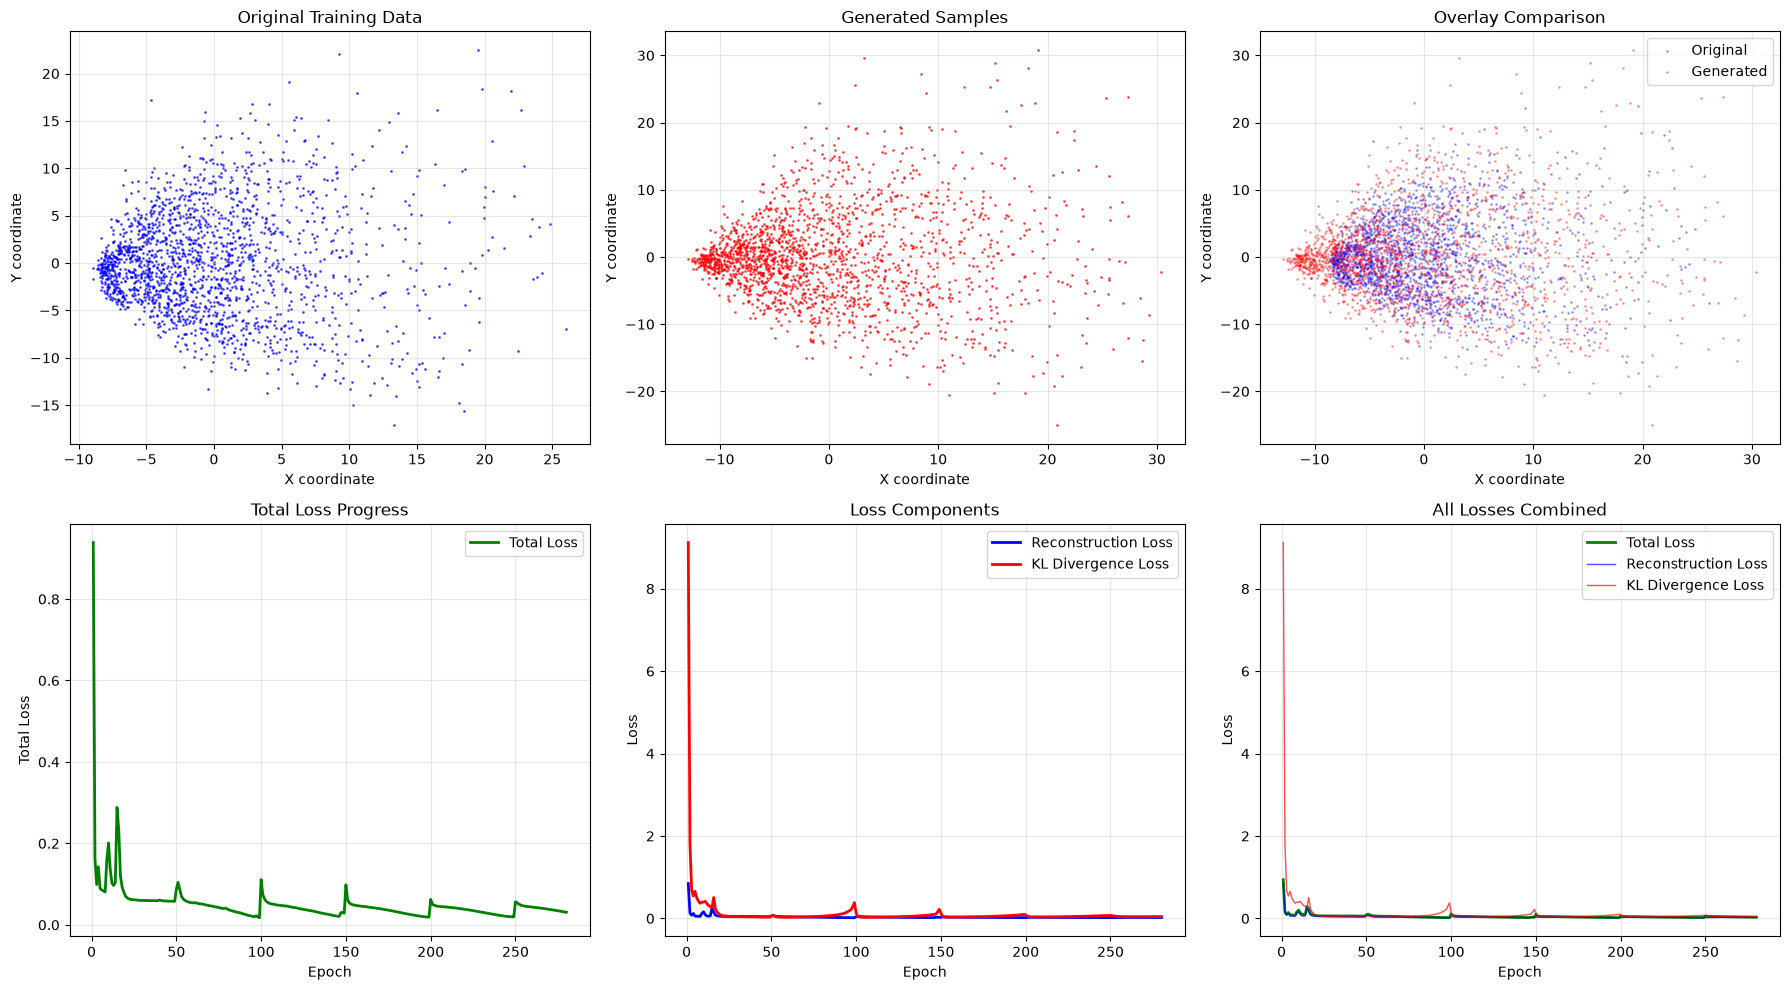

📈 Epoch 280 Summary:
   Total Loss: 0.0309
   Reconstruction Loss: 0.0229
   KL Divergence Loss: 0.0462
   Beta: 0.173
   Learning Rate: 0.000002

📊 Epoch 281/300
----------------------------------------
Epoch: 281 [0/60000 (0%)]	Total Loss: 0.030158	Recon Loss: 0.022796	KL Loss: 0.046603	Beta: 0.158
====> Epoch: 281 Average Total Loss: 0.0302, Average Recon Loss: 0.0228, Average KL Loss: 0.0465, Beta: 0.158
📈 Epoch 281 Summary:
   Total Loss: 0.0302
   Reconstruction Loss: 0.0228
   KL Divergence Loss: 0.0465
   Beta: 0.158
   Learning Rate: 0.000002

📊 Epoch 282/300
----------------------------------------
Epoch: 282 [0/60000 (0%)]	Total Loss: 0.029530	Recon Loss: 0.022829	KL Loss: 0.046677	Beta: 0.144
====> Epoch: 282 Average Total Loss: 0.0293, Average Recon Loss: 0.0226, Average KL Loss: 0.0472, Beta: 0.144
📈 Epoch 282 Summary:
   Total Loss: 0.0293
   Reconstruction Loss: 0.0226
   KL Divergence Loss: 0.0472
   Beta: 0.144
   Learning Rate: 0.000002

📊 Epoch 283/300
-------------

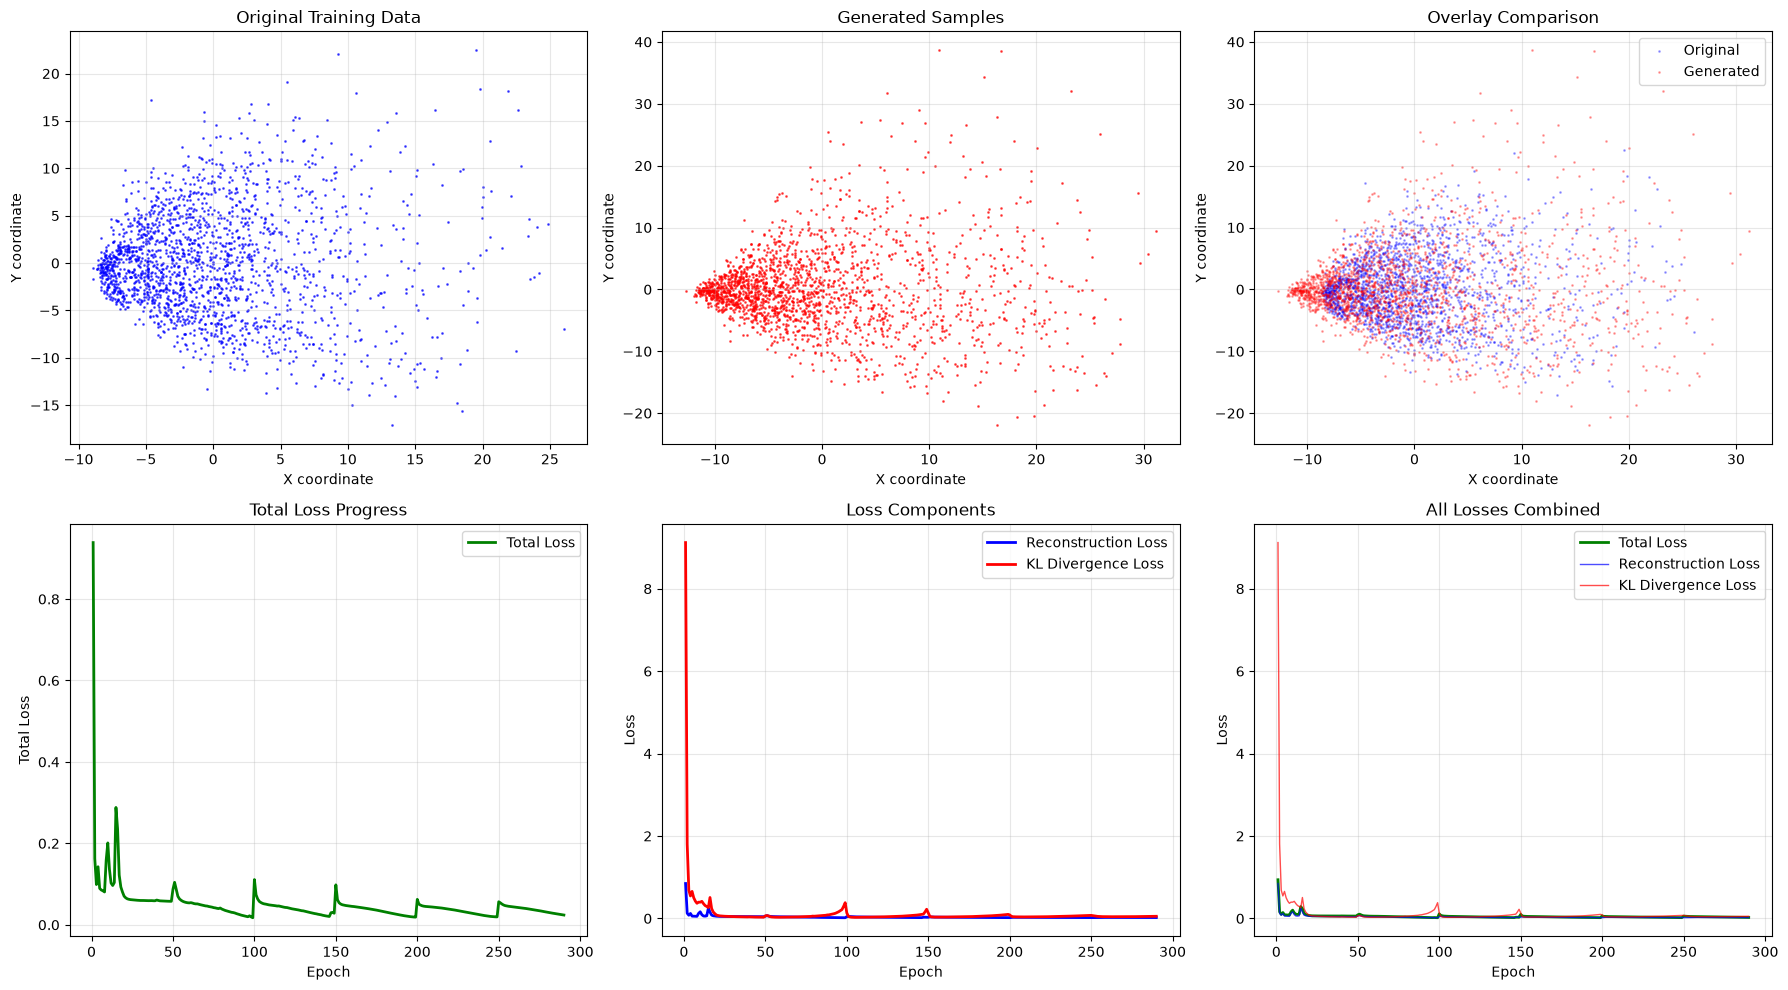

📈 Epoch 290 Summary:
   Total Loss: 0.0240
   Reconstruction Loss: 0.0215
   KL Divergence Loss: 0.0524
   Beta: 0.048
   Learning Rate: 0.000001

📊 Epoch 291/300
----------------------------------------
Epoch: 291 [0/60000 (0%)]	Total Loss: 0.023836	Recon Loss: 0.021801	KL Loss: 0.052285	Beta: 0.039
====> Epoch: 291 Average Total Loss: 0.0235, Average Recon Loss: 0.0215, Average KL Loss: 0.0528, Beta: 0.039
📈 Epoch 291 Summary:
   Total Loss: 0.0235
   Reconstruction Loss: 0.0215
   KL Divergence Loss: 0.0528
   Beta: 0.039
   Learning Rate: 0.000001

📊 Epoch 292/300
----------------------------------------
Epoch: 292 [0/60000 (0%)]	Total Loss: 0.023153	Recon Loss: 0.021525	KL Loss: 0.052635	Beta: 0.031
====> Epoch: 292 Average Total Loss: 0.0230, Average Recon Loss: 0.0214, Average KL Loss: 0.0533, Beta: 0.031
📈 Epoch 292 Summary:
   Total Loss: 0.0230
   Reconstruction Loss: 0.0214
   KL Divergence Loss: 0.0533
   Beta: 0.031
   Learning Rate: 0.000001

📊 Epoch 293/300
-------------

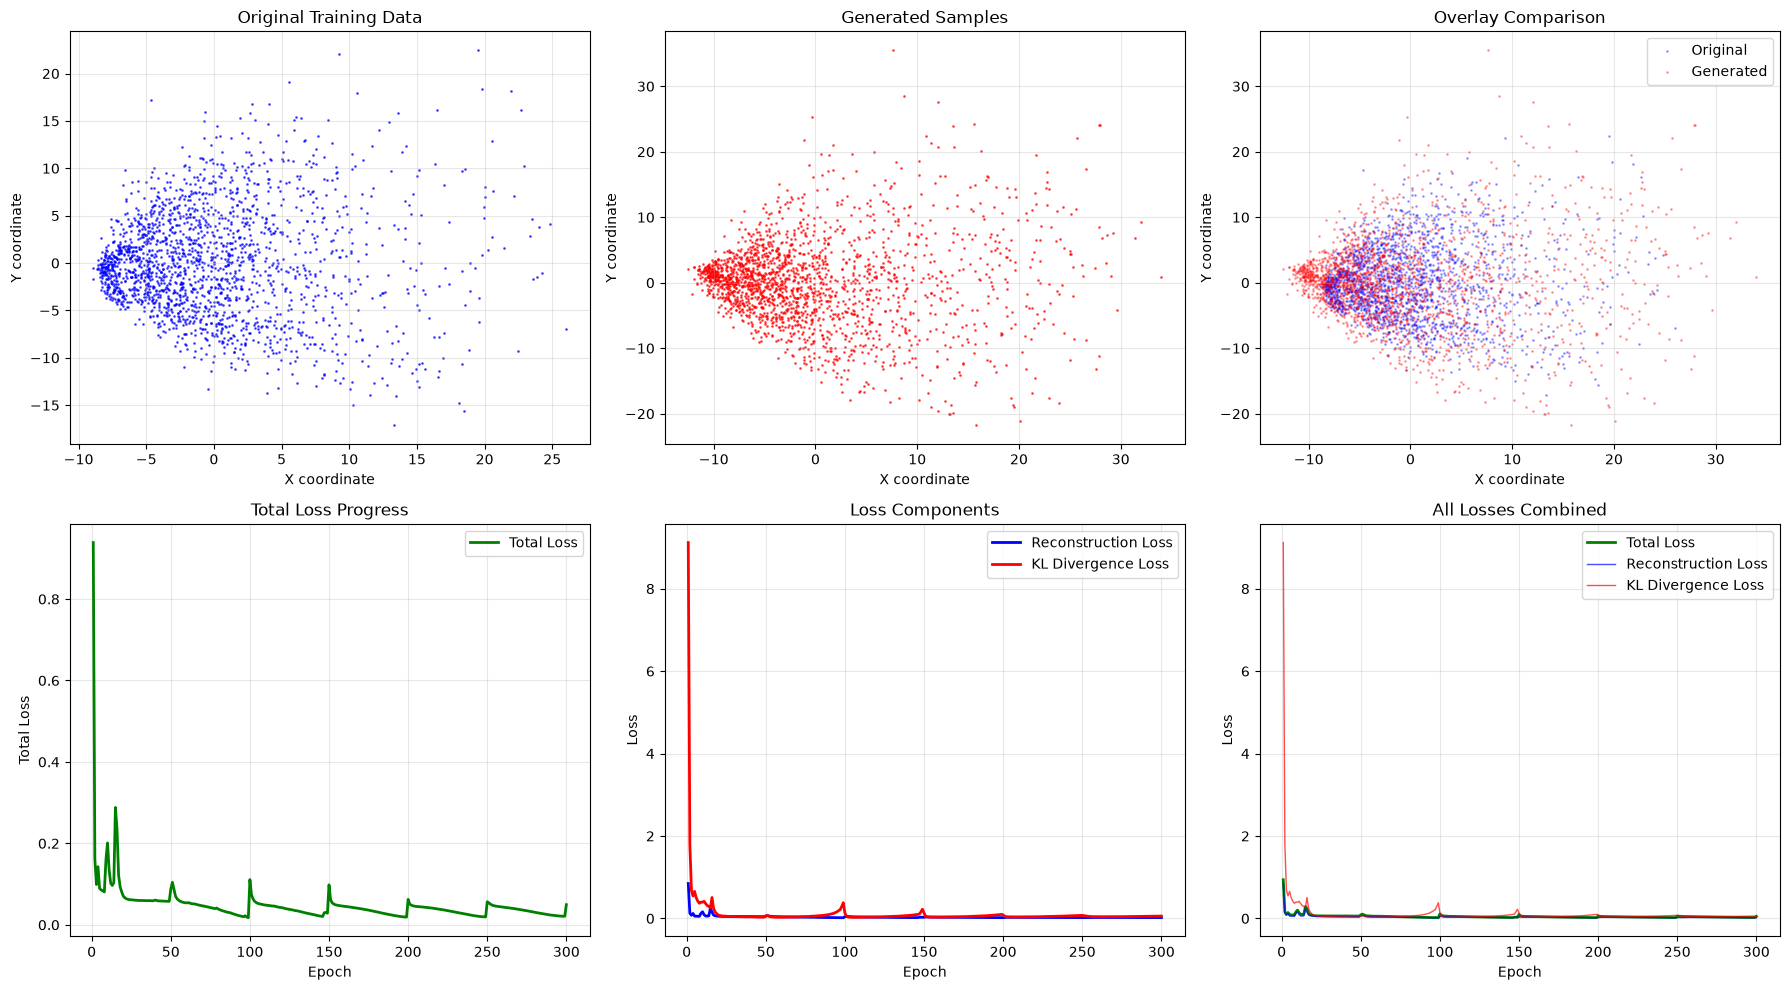

📈 Epoch 300 Summary:
   Total Loss: 0.0494
   Reconstruction Loss: 0.0208
   KL Divergence Loss: 0.0573
   Beta: 0.500
   Learning Rate: 0.000001

🎉 Training completed!
💾 Model saved as 'vae_model.pth'

🎨 Final comprehensive visualization:
💾 Saved plot: vae_results/vae_progress_epoch_300.png


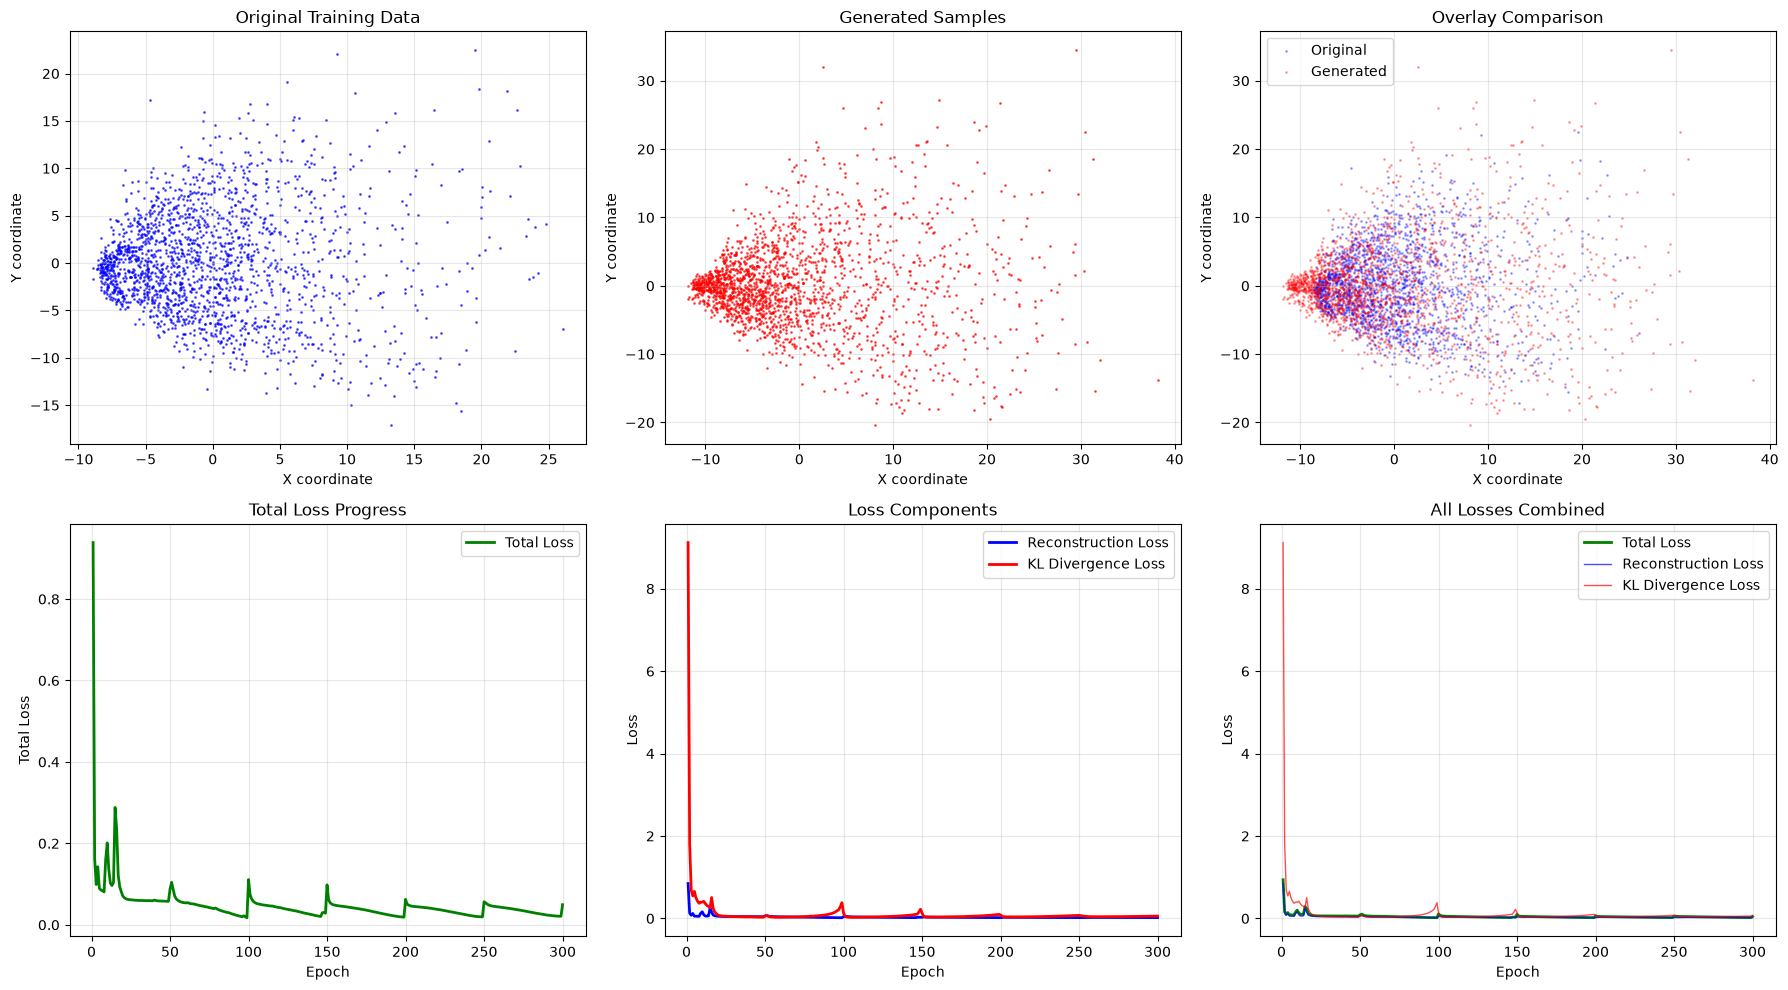

In [9]:
# Training loop
print("🎯 Starting VAE training...")
print("=" * 60)

# Lists to track training progress
total_losses = []
recon_losses = []
kl_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")
visualize_training_progress(0, [], [], [], save_plot=True)

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch
    avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta = train_epoch(epoch)
    
    # Track losses
    total_losses.append(avg_total_loss)
    recon_losses.append(avg_recon_loss)
    kl_losses.append(avg_kl_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=True)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Total Loss: {avg_total_loss:.4f}")
    print(f"   Reconstruction Loss: {avg_recon_loss:.4f}")
    print(f"   KL Divergence Loss: {avg_kl_loss:.4f}")
    print(f"   Beta: {current_beta:.3f}")
    print(f"   Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained model
torch.save(vae.state_dict(), 'models/vae_model.pth')
print("💾 Model saved as 'vae_model.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, total_losses, recon_losses, kl_losses, save_plot=True)


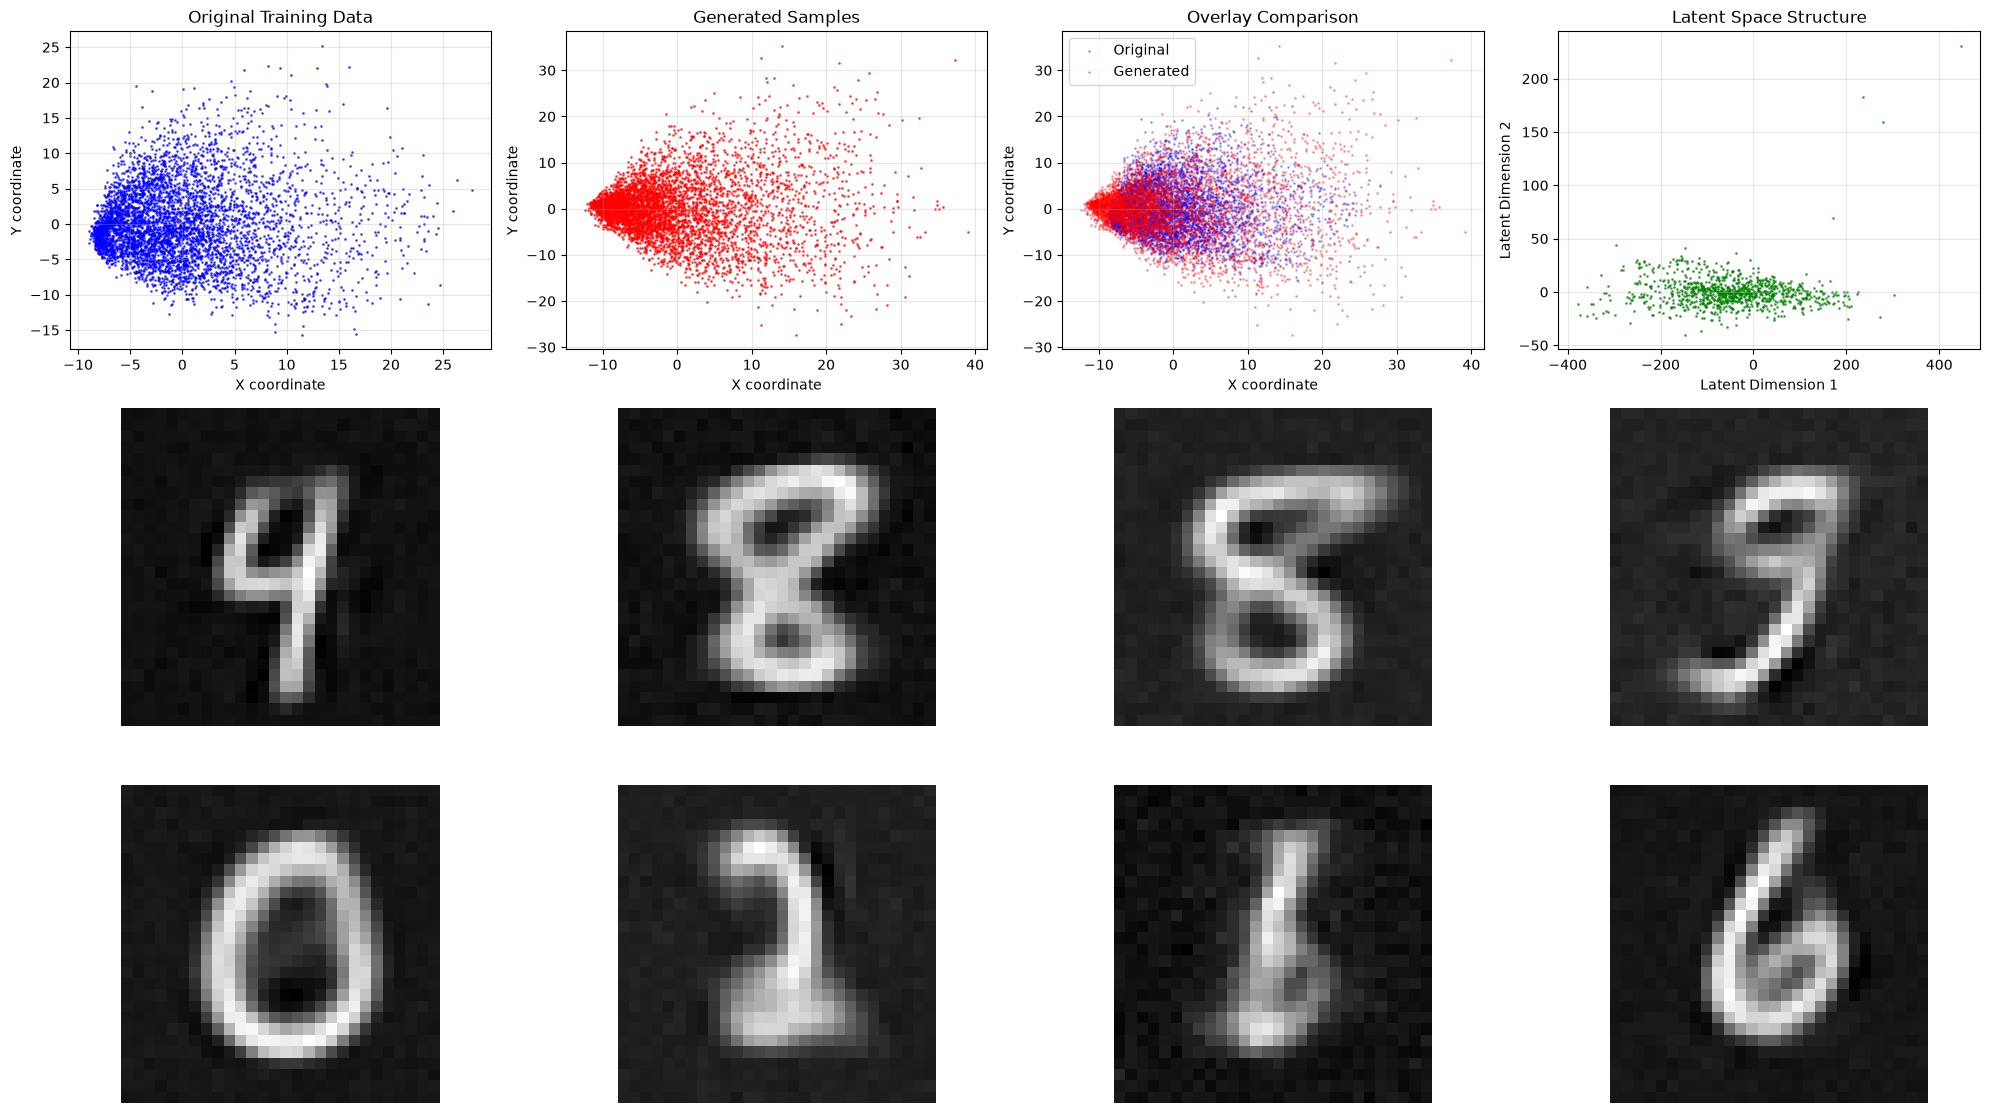

In [10]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 4, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 4, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 4, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)

# Show the latent space structure
plt.subplot(4, 4, 4)
# Encode some real data to see latent space
vae.eval()
with torch.no_grad():
    train_data_reshaped = np.reshape(train_data.data[:1000], [1000, INPUT_DIM])
    mu, logvar = vae.encode(train_data_reshaped.to(device).float())
    latent_points = mu.cpu().numpy()

plt.scatter(latent_points[:, 0], latent_points[:, 1], c='green', s=1, alpha=0.6)
plt.title('Latent Space Structure')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.grid(True, alpha=0.3)


for i in range(8):
    plt.subplot(4, 4, 4 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 🚀 Next Steps and Experiments

Now that you understand the basics, here are some exciting experiments you can try:

### Easy Experiments:
1. **Change the Dataset**: Try different datasets like circles, spirals, or your own 2D data
2. **Adjust Hyperparameters**: 
   - Change learning rate (try 1e-4, 1e-2)
   - Modify network sizes (try 128, 512 hidden units)
   - Adjust beta parameter (try 0.1, 2.0, 10.0)
3. **Visualize Training**: Watch how the latent space evolves during training

### Intermediate Experiments:
4. **Different Latent Dimensions**: Try 1D, 3D, or 4D latent spaces
5. **Beta-VAE**: Experiment with different beta values to control disentanglement
6. **Conditional VAE**: Generate different types of data based on labels

### Advanced Experiments:
7. **Higher Dimensions**: Apply to image data (MNIST, CIFAR-10)
8. **WAE (Wasserstein Autoencoder)**: Implement the Wasserstein variant
9. **VAE-GAN**: Combine VAE with GAN for better generation quality

### Code Modifications to Try:
```python
# Try different datasets
from sklearn.datasets import make_circles, make_spiral
train_data = make_circles(n_samples=50000, noise=0.05)[0].astype(np.float32)

# Try different architectures
LATENT_DIM = 4         # Higher dimensional latent space
HIDDEN_DIM = 512       # Larger networks

# Try different beta values
BETA = 0.1             # Less regularization
BETA = 10.0            # More regularization
```


## 📚 Further Reading and Resources

### Papers to Read:
1. **Original VAE Paper**: "Auto-Encoding Variational Bayes" by Kingma & Welling (2014)
2. **Beta-VAE**: "β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework" by Higgins et al. (2017)
3. **WAE**: "Wasserstein Auto-Encoders" by Tolstikhin et al. (2018)
4. **VAE-GAN**: "Autoencoding beyond pixels using a learned similarity metric" by Larsen et al. (2016)

### Libraries to Explore:
- **PyTorch Lightning**: For easier VAE training
- **Hugging Face Transformers**: For text-based VAEs
- **Pyro**: Probabilistic programming with VAEs

### Applications:
- **Image Generation**: Creating new images from scratch
- **Data Compression**: Learning efficient representations
- **Anomaly Detection**: Finding unusual patterns in data
- **Data Augmentation**: Generating more training data
- **Representation Learning**: Learning useful features for downstream tasks

### Key Takeaways:
- VAEs are powerful tools for generative modeling and representation learning
- The reparameterization trick is crucial for training
- The beta parameter controls the trade-off between reconstruction and regularization
- VAEs provide a principled way to learn continuous latent representations
- The latent space can be used for interpolation and manipulation

### Common VAE Challenges:
- **Blurry Reconstructions**: VAEs tend to produce smoother, less sharp outputs
- **Posterior Collapse**: When the latent space becomes uninformative
- **Beta Tuning**: Finding the right balance between reconstruction and regularization
- **Evaluation**: Measuring VAE quality objectively

---

**Happy Learning! 🎓**

*Remember: The best way to learn is by experimenting. Try modifying the code, changing parameters, and seeing what happens. Every experiment teaches you something new about how VAEs work!*
